# GRF Post-Processing

GRF Post-Processing — ATE, Heterogeneity Diagnostics, and CATE by Moderator (Dictator + Trust)

Tristan Muno [ORCID profile for Tristan Muno](https://orcid.org/0009-0002-3078-8436) (University of Mannheim)  
Vera Okisheva (University of Mannheim)  
Raphael Klöckner (University of Mannheim)  
October 19, 2026

## Purpose

This notebook post-processes the **primary** estimator — the saved `grf` causal forests (`data/03_final/grf_{dictator,trust}.rds`) — following the canonical post-fit workflow from the generalized-random-forest literature (`athey2019generalized`, `wager2018estimation`, `athey2019estimating`).

It is written to be read **line by line**: every step is laid out sequentially, the two games (Dictator, Trust) are done one after the other, and the headline CATE-by-moderator figures are built **one explicit chunk per moderator** rather than through shared helper functions.

For each game we run, in order:

1.  **Average treatment effect (ATE) + SE** — `average_treatment_effect()`, the doubly-robust (AIPW) estimate with the cluster-robust standard error from the respondent clusters stored on the forest.
2.  **Targeting Operator Characteristic (TOC) / RATE** — `rank_average_treatment_effect()`, the overall “is there targetable heterogeneity” summary (AUTOC ± SE plus the TOC curve).
3.  **Best linear projection (BLP)** — `best_linear_projection()` of the CATE onto the moderator set, an appendix-style linear summary of effect modification.
4.  **Variable importance** — `variable_importance()`, aggregated from the expanded dummy columns back up to the original moderators (construct level).
5.  **CATE by moderator** — the headline figures: estimated CATE on the y-axis, the moderator on the x-axis, with an **honest 95% confidence interval at each level**. Per-level intervals come straight from `average_treatment_effect(cf, subset = ...)`, which is the documented `grf` way to get a doubly-robust, cluster-robust subset ATE.

Two moderator families, matching the research plan:

- **Conjoint round-level** moderators (`prof_mods`) — other attributes in the same profile.
- **Individual-level** moderators (`resp_mods`) — respondent pre-treatment items and indices.

The companion notebook `08_postprocess_bcf.qmd` runs the analogous workflow on the BCF fits.

> **A note on cost**
>
> Each per-level CI is a separate `average_treatment_effect()` call, so the CATE-by-moderator sweep makes many calls (one per level, across 31 moderators, twice). This is slower than computing the doubly-robust scores once and reusing them, but it is the most transparent route and the user-requested one; Quarto `freeze: auto` caches the rendered result.

## Setup

In [ ]:
# execution time
start_time <- Sys.time()
# console width
options(width = 80)
# packages
p_required <- c(
  "tidyverse", # dplyr, ggplot2, tidyr, purrr
  "here", # relative paths
  "ggpubr", # theme_pubr
  "patchwork", # later composition
  "grf", # causal_forest predictions, ATE, RATE, BLP
  "sessioninfo" # session docs
)
packages <- rownames(installed.packages())
p_to_install <- p_required[!(p_required %in% packages)]
if (length(p_to_install) > 0) {
  install.packages(p_to_install)
}
sapply(p_required, require, character.only = TRUE)


Loading required package: tidyverse

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: here

here() starts at C:/R/research/MBEU25

Loading required package: ggpubr

Loading required package: patchwork

Loading required package: grf

Loading required package: sessioninfo

  tidyverse        here      ggpubr   patchwork         grf sessioninfo 
       TRUE        TRUE        TRUE        TRUE        TRUE        TRUE 

## Load data and fits

In [ ]:
eu25_long <- readRDS(here::here("data", "02_processed", "eu25_long.rds"))
cf_dict <- readRDS(here::here("data", "03_final", "grf_dictator.rds"))
cf_trust <- readRDS(here::here("data", "03_final", "grf_trust.rds"))


## Reconstruct the moderator designs

The frozen moderator list, copied verbatim from `06_grf_fit.qmd`.

In [ ]:
prof_mods <- c(
  "cj_nationality_shown",
  "der_cj_eu_identity",
  "der_cj_partisanship",
  "cj_age",
  "cj_sex",
  "cj_class"
)
resp_mods <- c(
  "q_gender",
  "q_age",
  "q_identity_country",
  "q_identity_eu",
  "q_identity_europe",
  "q_religion",
  "q_class",
  "q_eu_efficacy_understand",
  "q_pop_reps",
  "q_pop_goodevil",
  "q_pop_compromise",
  "q_dem_compromise",
  "q_dem_listen",
  "q_tech_experts",
  "q_tech_leaders",
  "q_party_harm",
  "q_people_incompetent",
  "q_eu_longterm",
  "q_eu_responsive",
  "q_eu_imp_nat_econ",
  "q_eu_imp_nat_cul",
  "q_eu_imp_nat_pol",
  "q_eu_abolish",
  "q_eu_satisfaction",
  "q_rural_urban",
  "q_edu_age_stop"
)
all_mods <- c(prof_mods, resp_mods)


For each game we filter `dat` to that game in its original order (the same order the forest was fit on), keep the original moderator columns for plotting (`m_dict` / `m_trust`), and build the numeric moderator matrix used by the projection and importance steps (`X_dict` / `X_trust`) exactly as at fit time. The `stopifnot()` confirms the reconstructed rows line up with the forest’s training rows, so each τ̂ aligns with its moderator value.

In [ ]:
# dictator design (same row order as the fit)
sub_dict <- eu25_long |> filter(cj_game_type == "cj_dict")
m_dict <- sub_dict |>
  select(all_of(all_mods)) |>
  mutate(across(where(is.character), factor))
X_dict <- model.matrix(~ . - 1, data = m_dict)

# trust design (same row order as the fit)
sub_trust <- eu25_long |> filter(cj_game_type == "cj_trust")
m_trust <- sub_trust |>
  select(all_of(all_mods)) |>
  mutate(across(where(is.character), factor))
X_trust <- model.matrix(~ . - 1, data = m_trust)

stopifnot(
  length(cf_dict$Y.orig) == nrow(m_dict),
  length(cf_trust$Y.orig) == nrow(m_trust),
  !anyNA(X_dict),
  !anyNA(X_trust)
)


The y-axis label, shared by every CATE figure.

In [ ]:
yl <- expression(widehat(CATE))


## Dictator game

## Average treatment effect

The doubly-robust ATE with its cluster-robust SE (respondent clusters are stored on the forest), and the implied 95% interval.

In [ ]:
ate_dict <- grf::average_treatment_effect(cf_dict, target.sample = "all")
cat(sprintf(
  "Dictator ATE: %.4f  (SE %.4f);  95%% CI [%.4f, %.4f]\n",
  ate_dict["estimate"],
  ate_dict["std.err"],
  ate_dict["estimate"] - 1.96 * ate_dict["std.err"],
  ate_dict["estimate"] + 1.96 * ate_dict["std.err"]
))


Dictator ATE: -0.5672  (SE 0.0190);  95% CI [-0.6045, -0.5300]

## Targeting Operator Characteristic (RATE)

`rank_average_treatment_effect()` ranks observations by their out-of-bag predicted CATE and traces the ATE among the top-`q` fraction against the overall ATE. The area under this curve is the AUTOC; a curve and AUTOC clearly above zero is evidence of targetable heterogeneity. Priorities here are the forest’s own out-of-bag predictions. Because the prioritization rule is not estimated on data independent of the evaluation data, the AUTOC is read as descriptive support for targetable heterogeneity rather than a strictly valid test. A separate train/evaluate split would be required for formal inference and is out of scope.

  estimate    std.err             target
 0.2753056 0.01947141 priorities | AUTOC

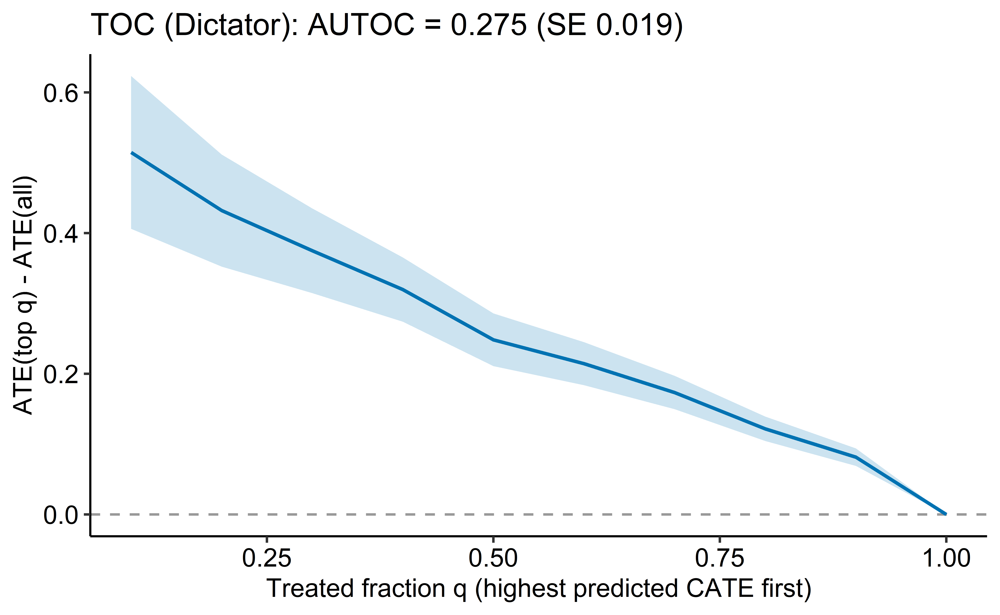

In [ ]:
prio_dict <- predict(cf_dict)$predictions
rate_dict <- grf::rank_average_treatment_effect(cf_dict, prio_dict)
print(rate_dict)


## Best linear projection

The best linear projection of the CATE onto the moderator matrix: a linear summary of which moderators shift the treatment effect. This is an appendix/robustness summary, not a headline.

In [ ]:
blp_dict <- grf::best_linear_projection(cf_dict, X_dict)
blp_dict_df <- blp_dict |>
  unclass() |>
  as.data.frame() |>
  tibble::rownames_to_column("term") |>
  as_tibble() |>
  rename(estimate = Estimate, std_error = `Std. Error`) |>
  mutate(
    lower = estimate - 1.96 * std_error,
    upper = estimate + 1.96 * std_error
  ) |>
  filter(term != "(Intercept)")

ggplot(blp_dict_df, aes(x = estimate, y = fct_reorder(term, estimate))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), colour = "#0072B2") +
  labs(
    title = "Best linear projection of the CATE (Dictator)",
    x = "Projection coefficient",
    y = NULL
  ) +
  ggpubr::theme_pubr()


## Variable importance

`variable_importance()` returns one value per design column (the expanded moderator dummies plus the country fixed-effect dummies). We map each column back to its source moderator by longest-prefix match and sum, giving a construct-level ranking; country fixed-effect columns match no moderator and are dropped.

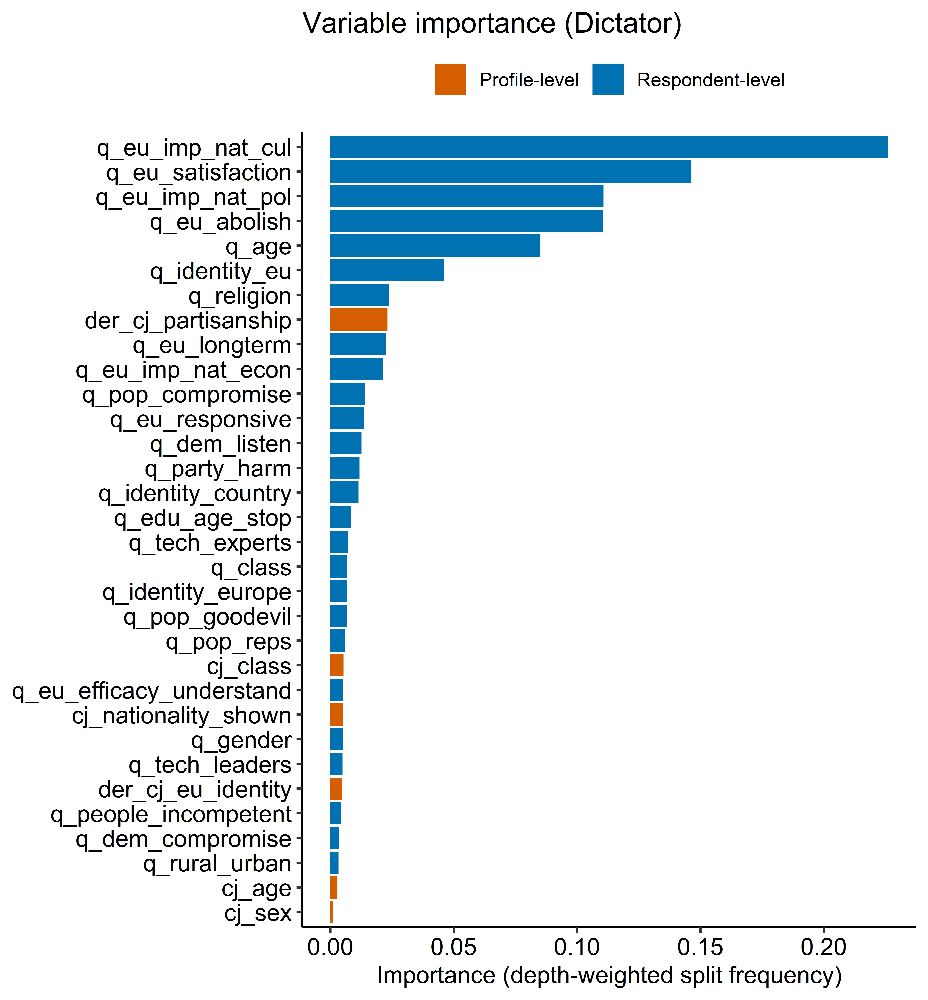

In [ ]:
vi_dict <- grf::variable_importance(cf_dict)
vi_dict_df <- tibble(
  column = colnames(cf_dict$X.orig),
  importance = as.numeric(vi_dict)
) |>
  mutate(
    moderator = map_chr(column, function(cn) {
      hit <- all_mods[startsWith(cn, all_mods)]
      if (length(hit) == 0) NA_character_ else hit[which.max(nchar(hit))]
    })
  ) |>
  filter(!is.na(moderator)) |>
  summarise(importance = sum(importance), .by = moderator) |>
  mutate(
    family = if_else(
      moderator %in% prof_mods,
      "Profile-level",
      "Respondent-level"
    ),
    moderator = fct_reorder(moderator, importance)
  )

ggplot(vi_dict_df, aes(x = importance, y = moderator, fill = family)) +
  geom_col() +
  scale_fill_manual(
    values = c("Profile-level" = "#D55E00", "Respondent-level" = "#0072B2")
  ) +
  labs(
    title = "Variable importance (Dictator)",
    x = "Importance (depth-weighted split frequency)",
    y = NULL,
    fill = NULL
  ) +
  ggpubr::theme_pubr()


## CATE by moderator — conjoint round-level

For each discrete moderator we loop over its levels, compute the subset ATE with its honest cluster-robust SE, form the 95% interval as estimate ± 1.96·SE, and plot the per-level estimate (blue) over grey per-level count bars.

### cj_nationality_shown

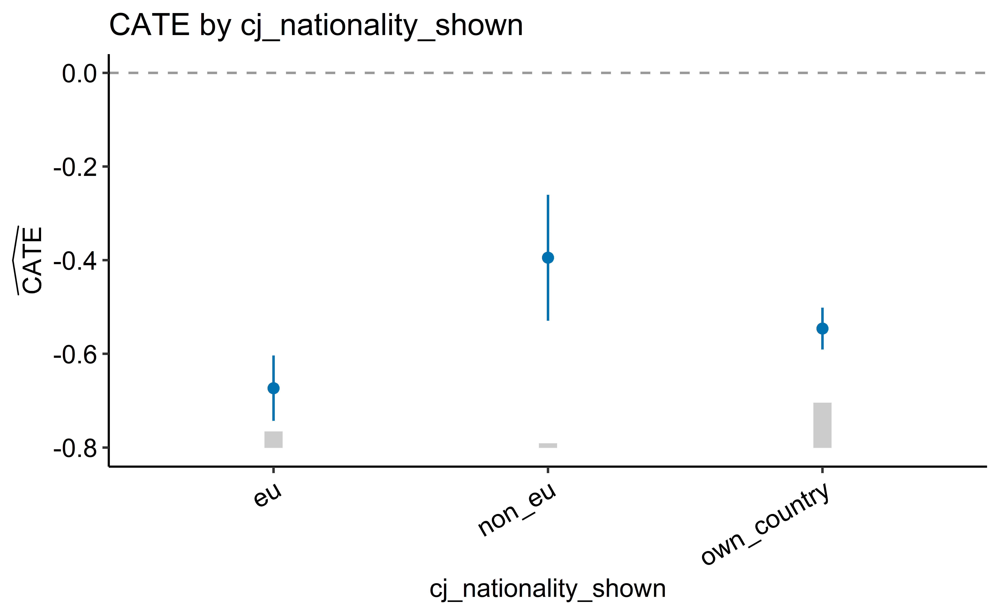

In [ ]:
mod <- "cj_nationality_shown"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### der_cj_eu_identity

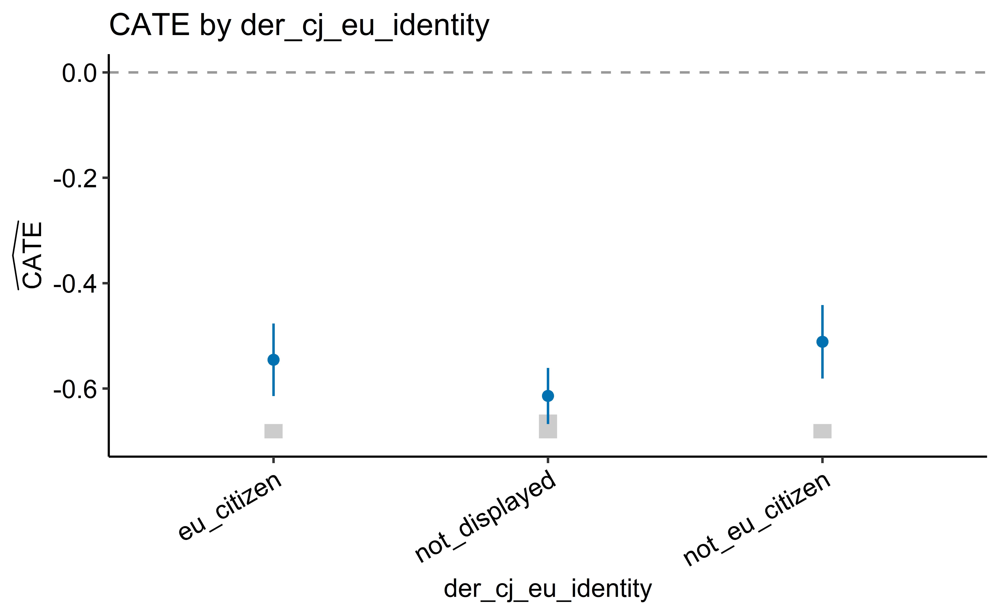

In [ ]:
mod <- "der_cj_eu_identity"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### der_cj_partisanship

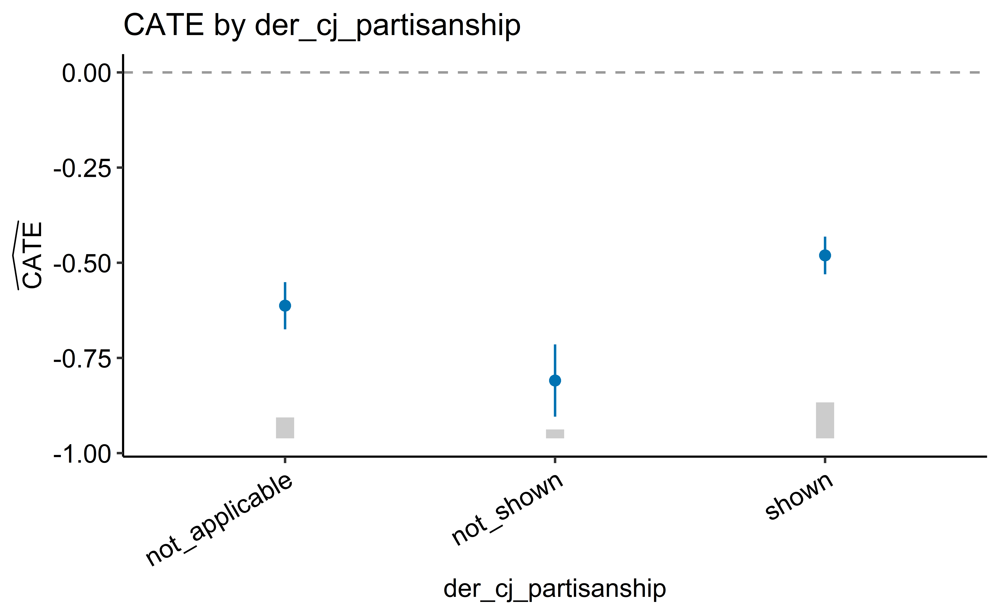

In [ ]:
mod <- "der_cj_partisanship"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### cj_age

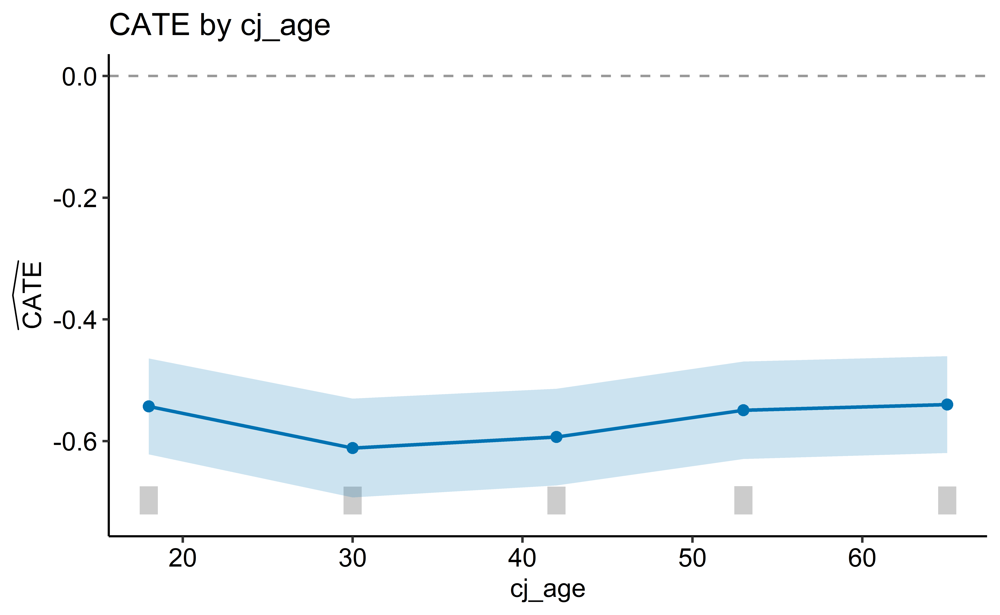

In [ ]:
mod <- "cj_age"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### cj_sex

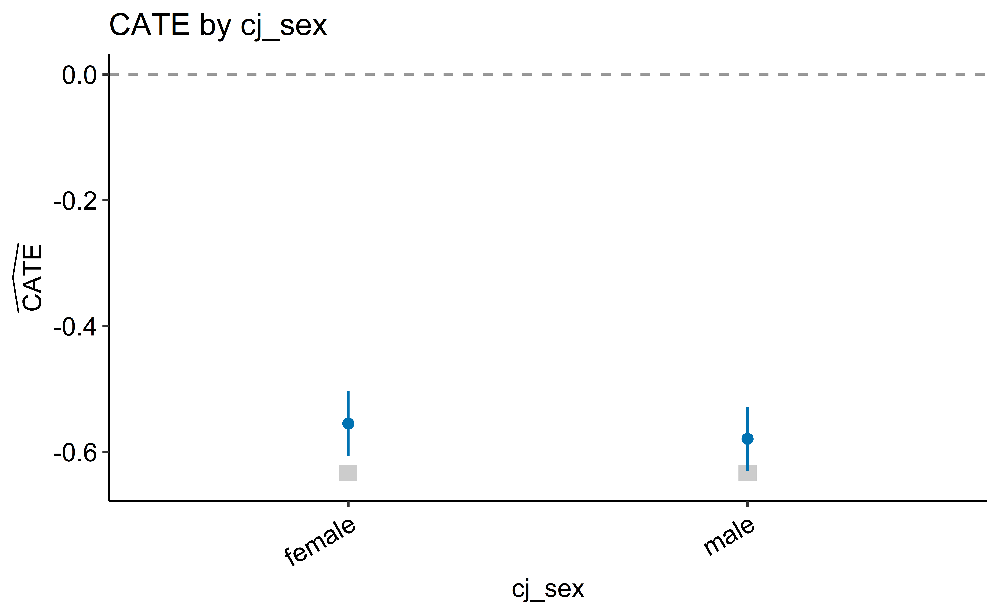

In [ ]:
mod <- "cj_sex"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### cj_class

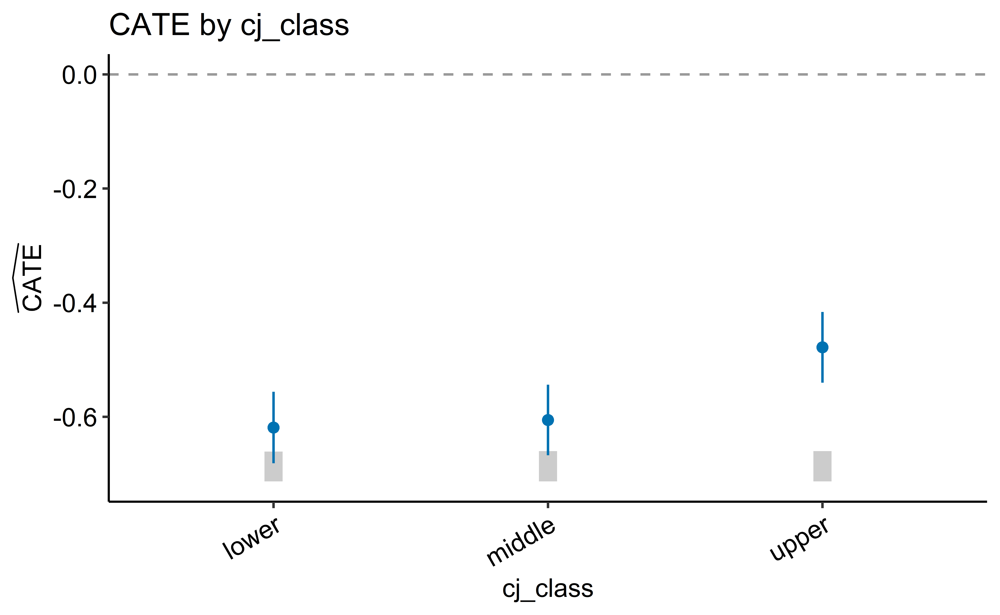

In [ ]:
mod <- "cj_class"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


## CATE by moderator — respondent-level

Same per-level construction for the respondent moderators. The two genuinely continuous moderators — `q_age` and `q_edu_age_stop` — are instead split into ten quantile bins and drawn as a ribbon-and-line with a covariate rug.

### q_gender

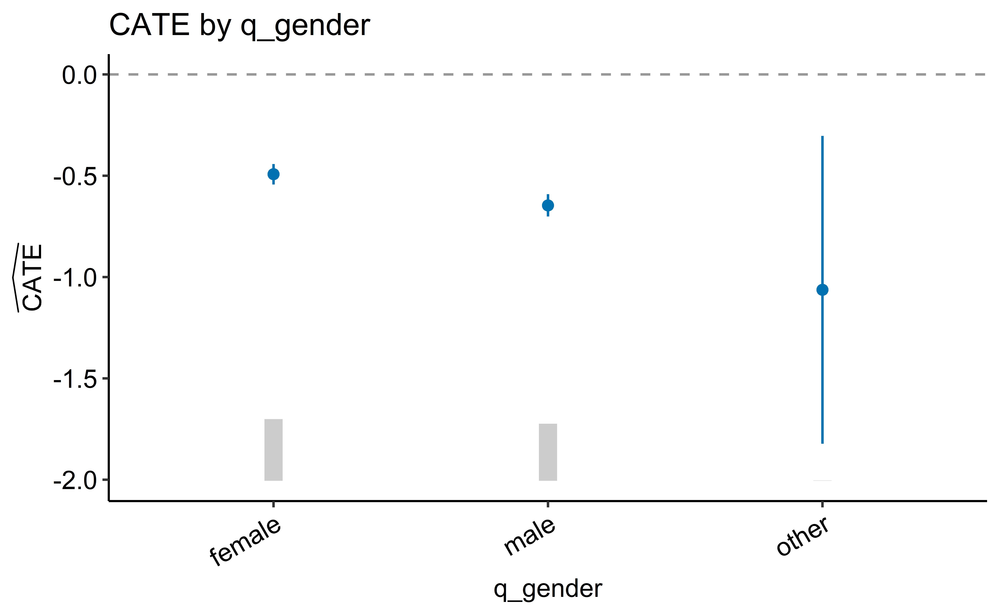

In [ ]:
mod <- "q_gender"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_age

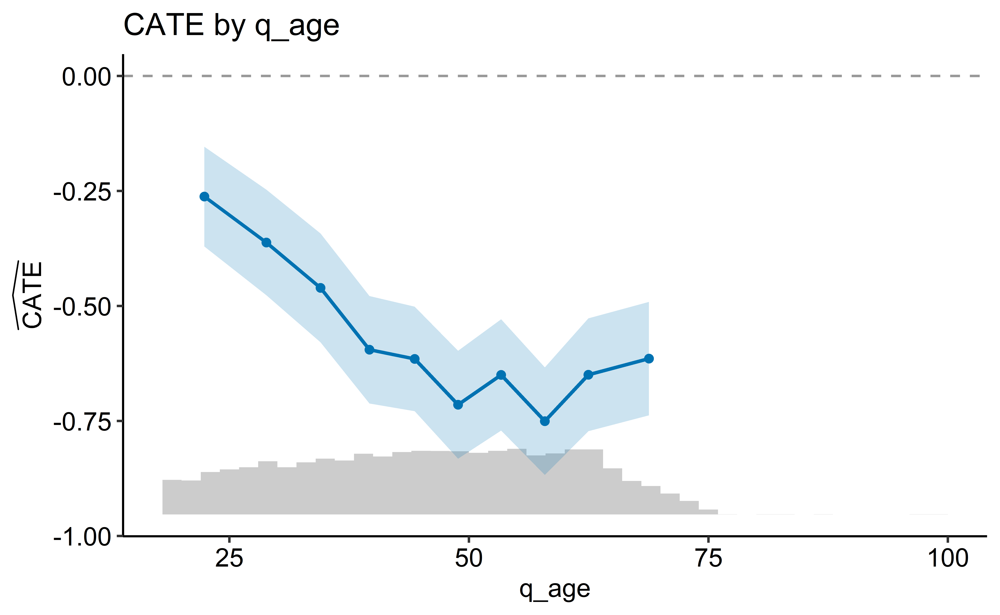

In [ ]:
mod <- "q_age"
col <- m_dict[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_country

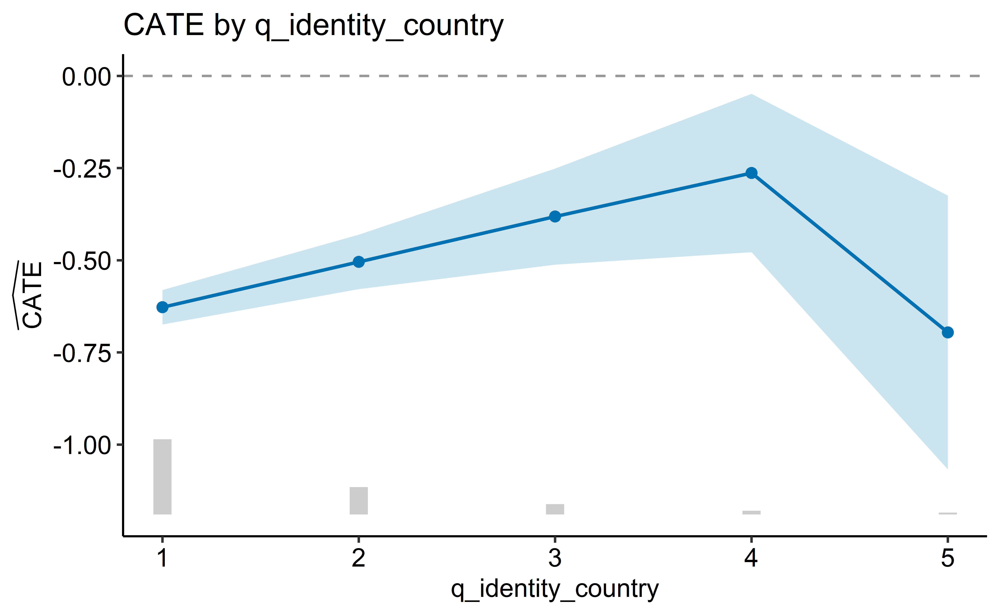

In [ ]:
mod <- "q_identity_country"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_eu

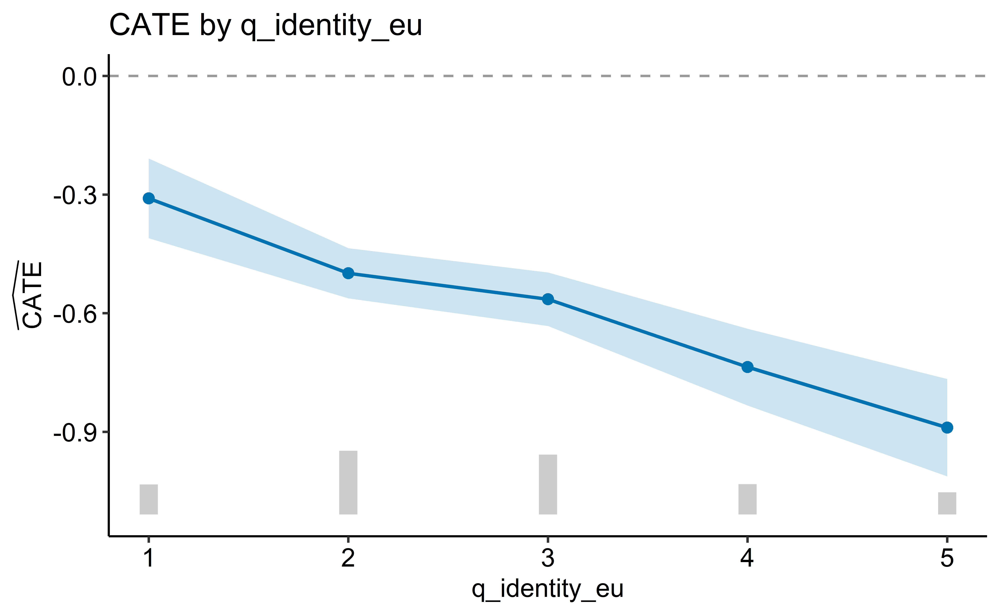

In [ ]:
mod <- "q_identity_eu"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_europe

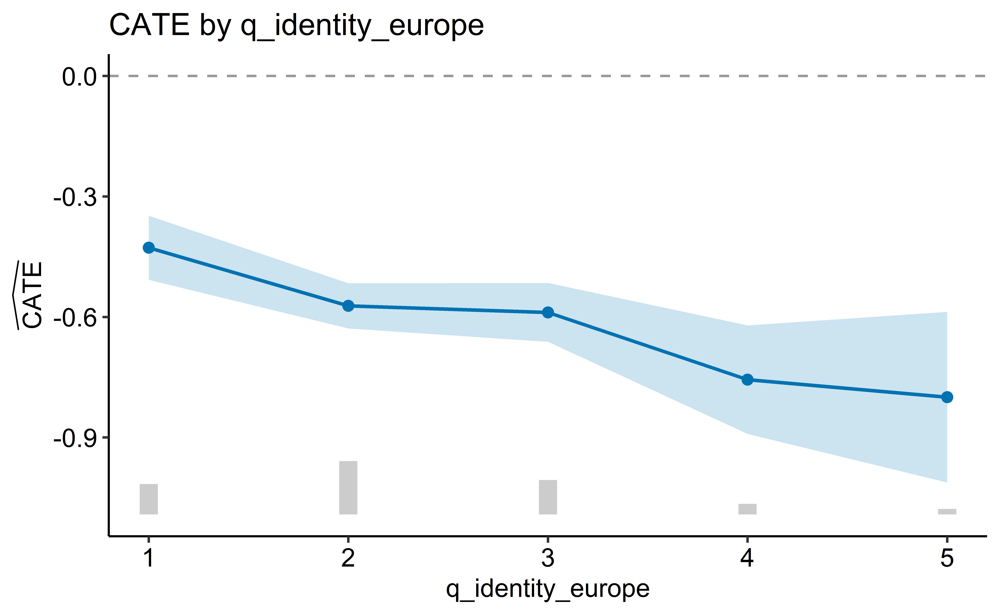

In [ ]:
mod <- "q_identity_europe"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_religion

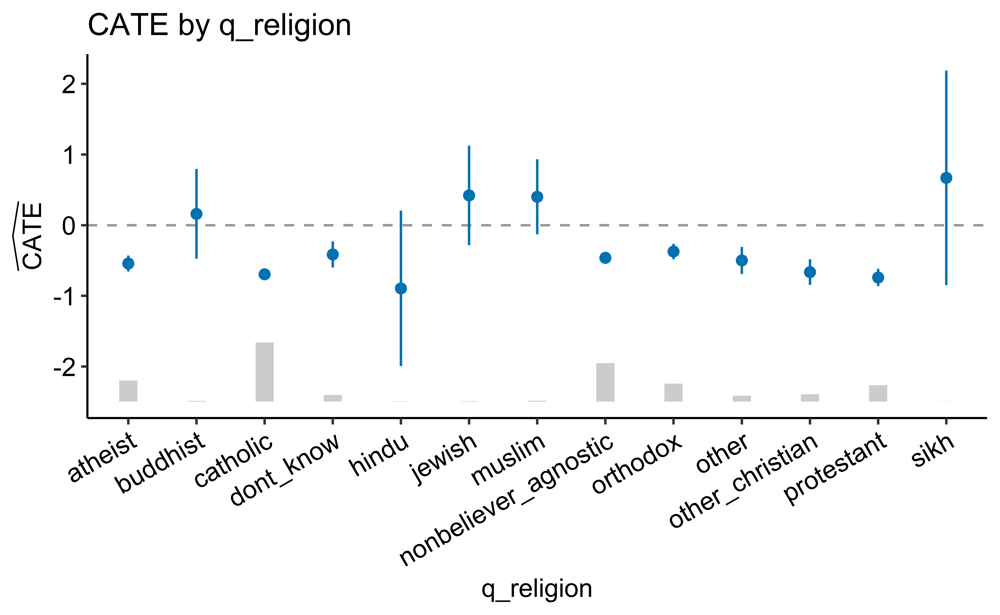

In [ ]:
mod <- "q_religion"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_class

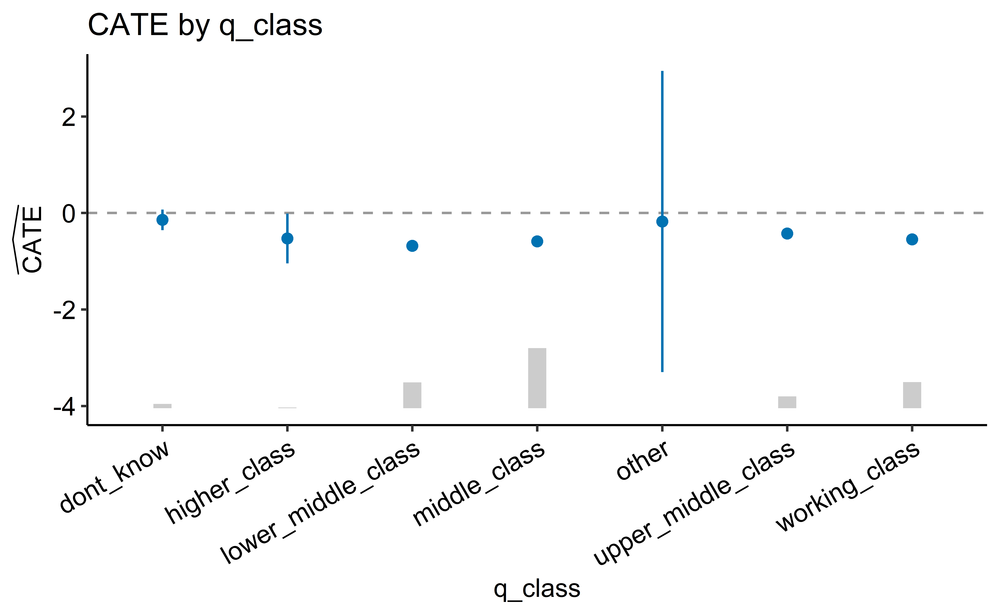

In [ ]:
mod <- "q_class"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_eu_efficacy_understand

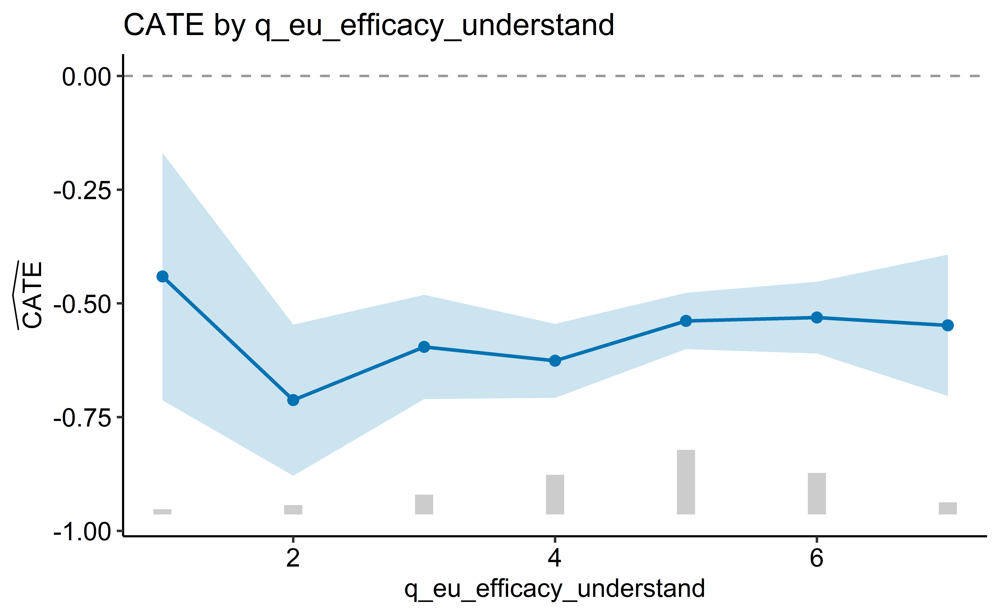

In [ ]:
mod <- "q_eu_efficacy_understand"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_reps

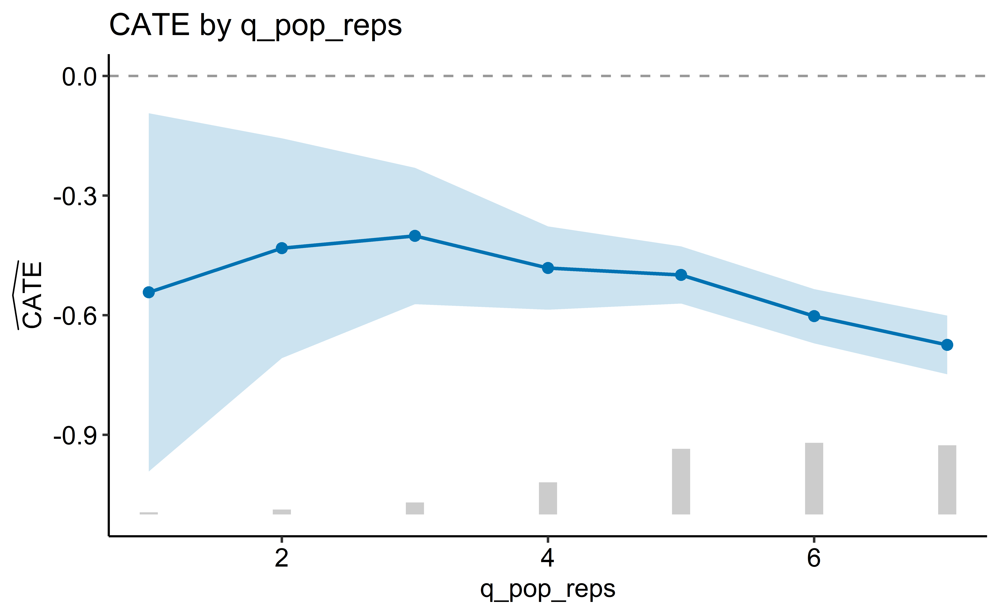

In [ ]:
mod <- "q_pop_reps"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_goodevil

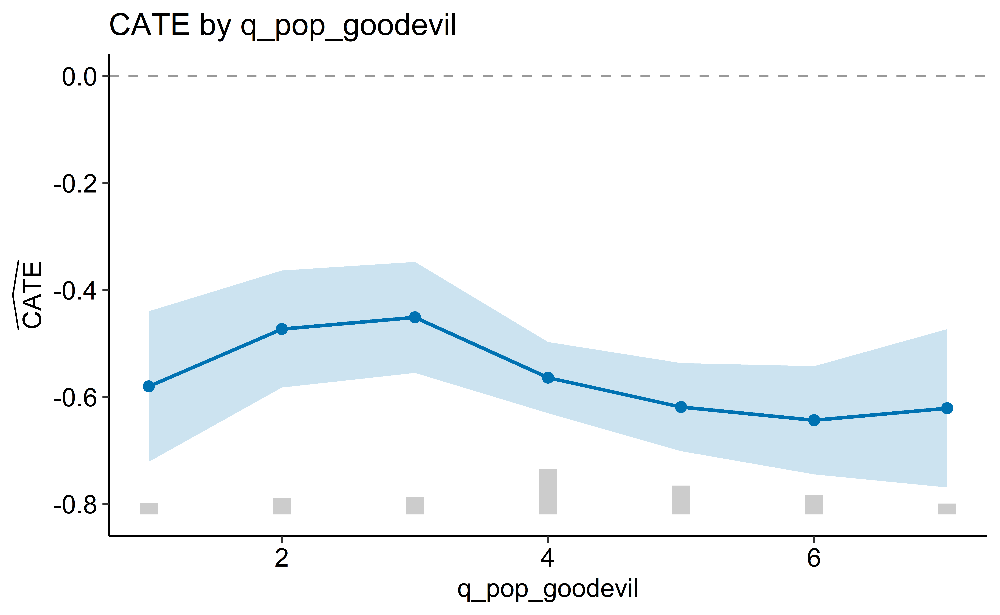

In [ ]:
mod <- "q_pop_goodevil"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_compromise

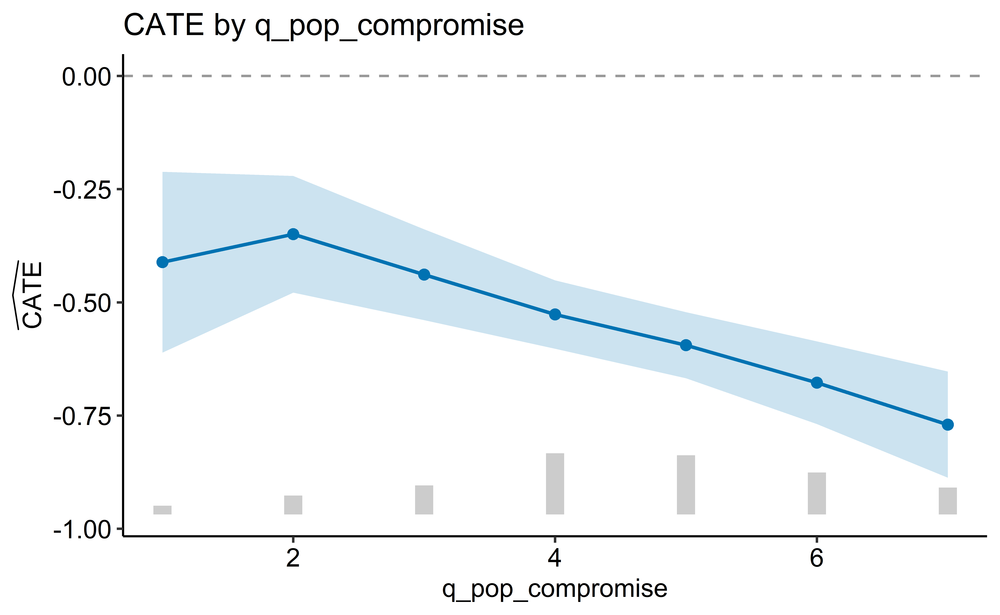

In [ ]:
mod <- "q_pop_compromise"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_dem_compromise

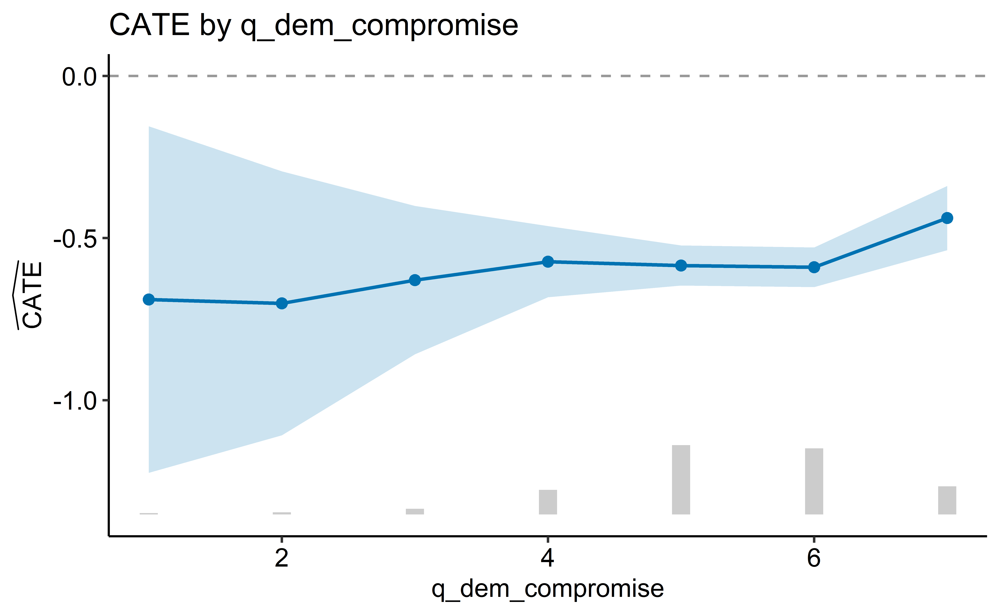

In [ ]:
mod <- "q_dem_compromise"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_dem_listen

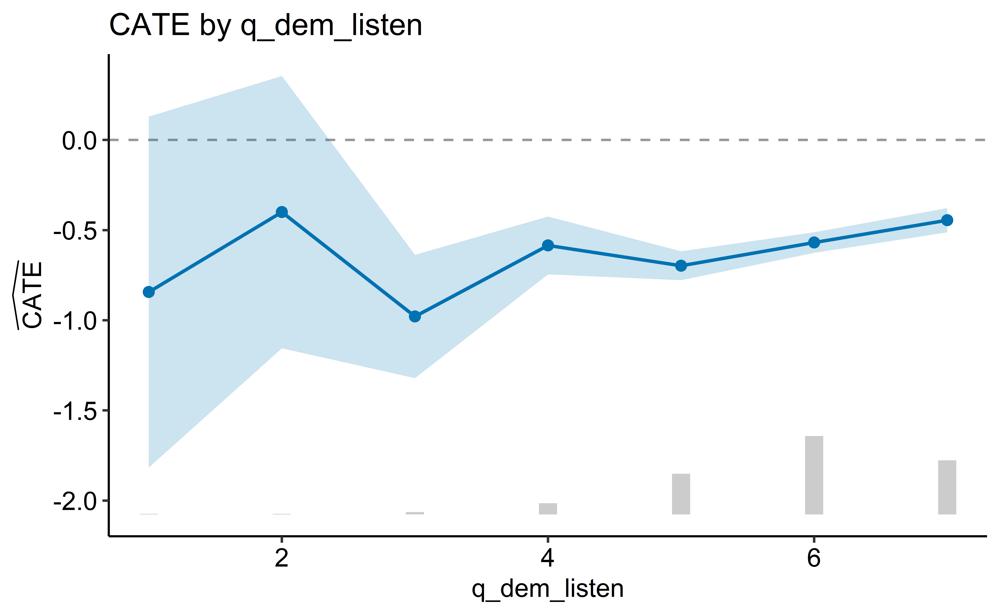

In [ ]:
mod <- "q_dem_listen"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_tech_experts

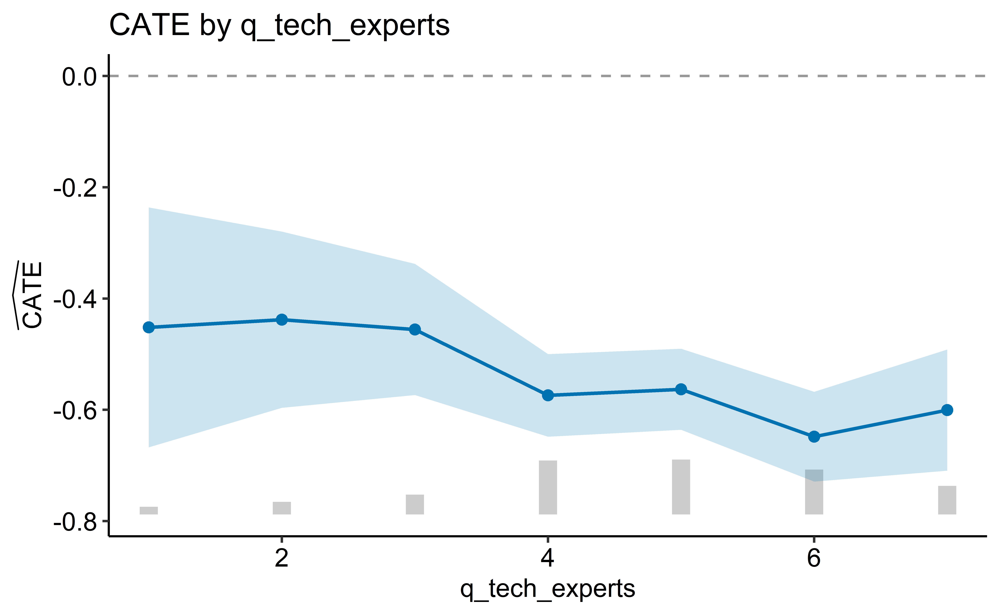

In [ ]:
mod <- "q_tech_experts"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_tech_leaders

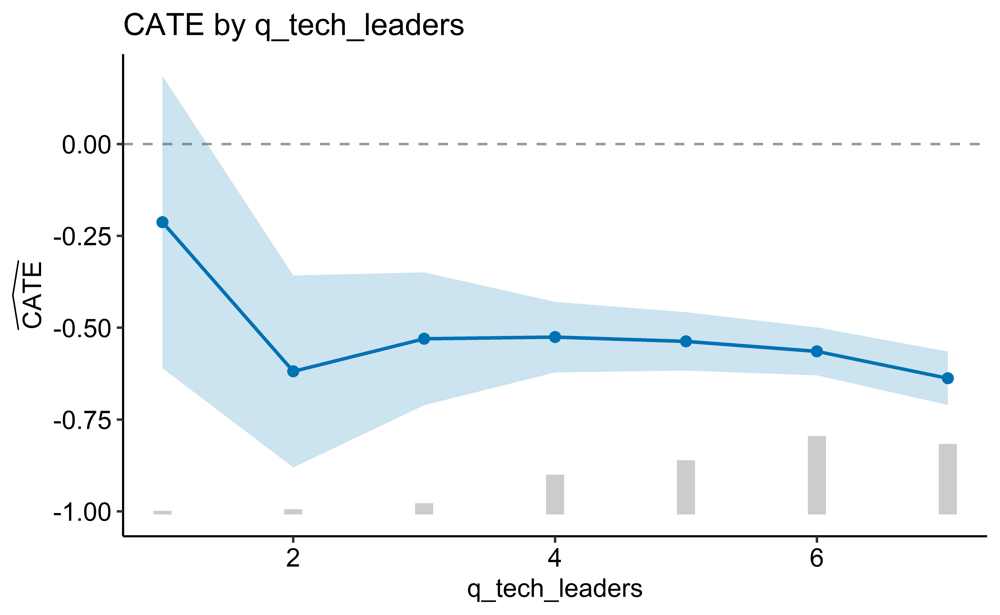

In [ ]:
mod <- "q_tech_leaders"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_party_harm

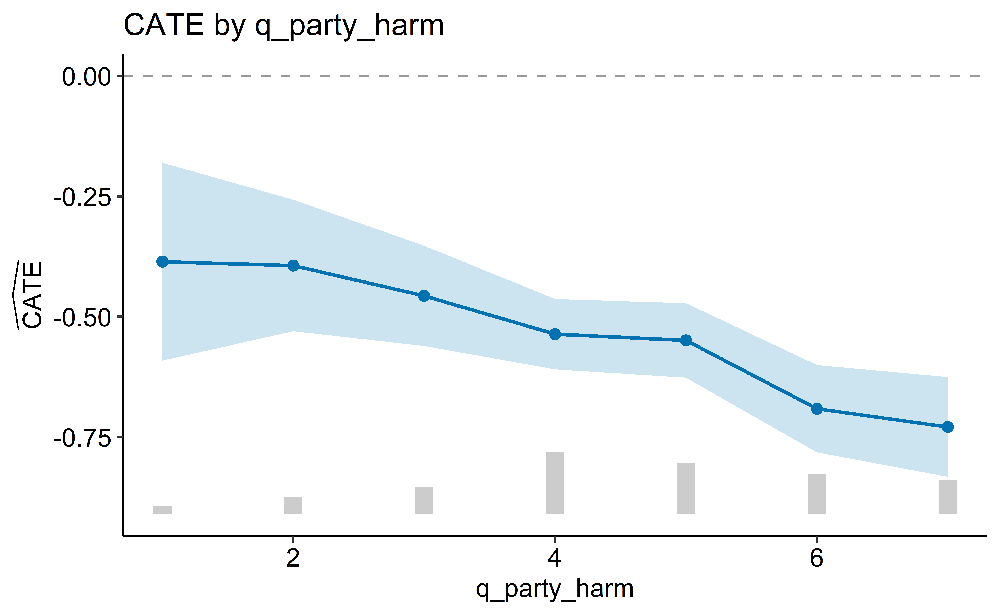

In [ ]:
mod <- "q_party_harm"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_people_incompetent

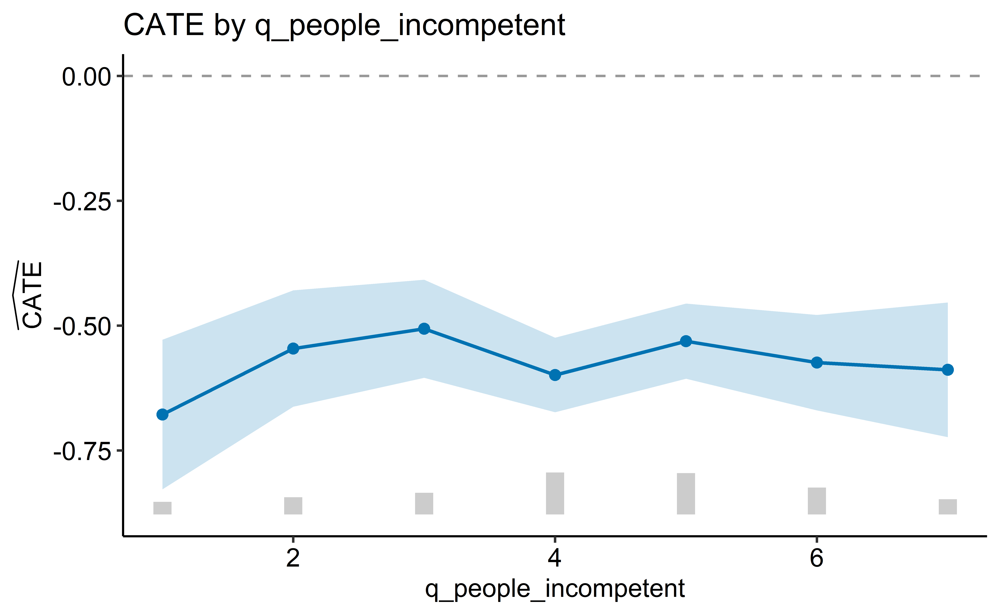

In [ ]:
mod <- "q_people_incompetent"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_longterm

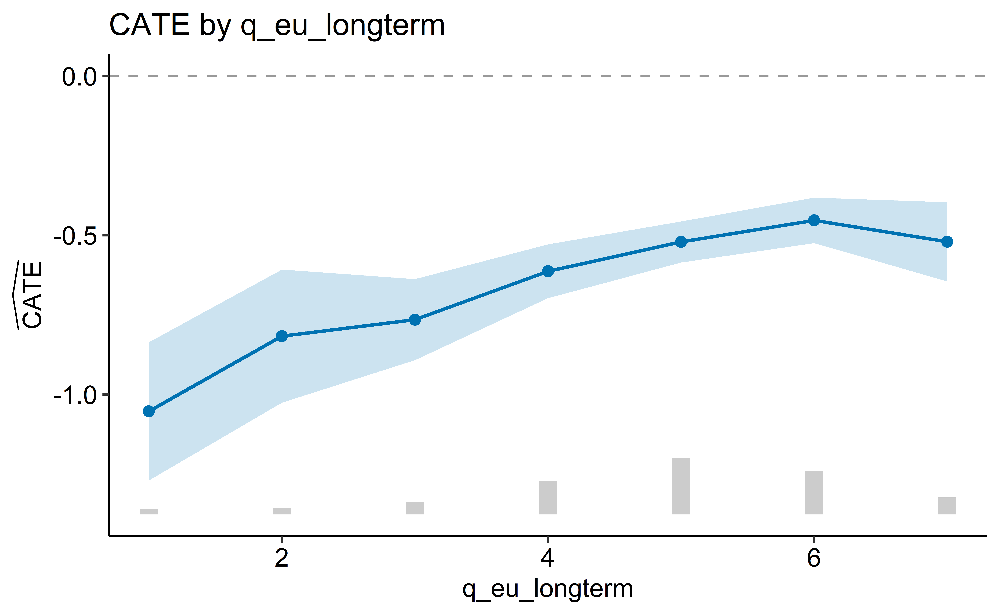

In [ ]:
mod <- "q_eu_longterm"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_responsive

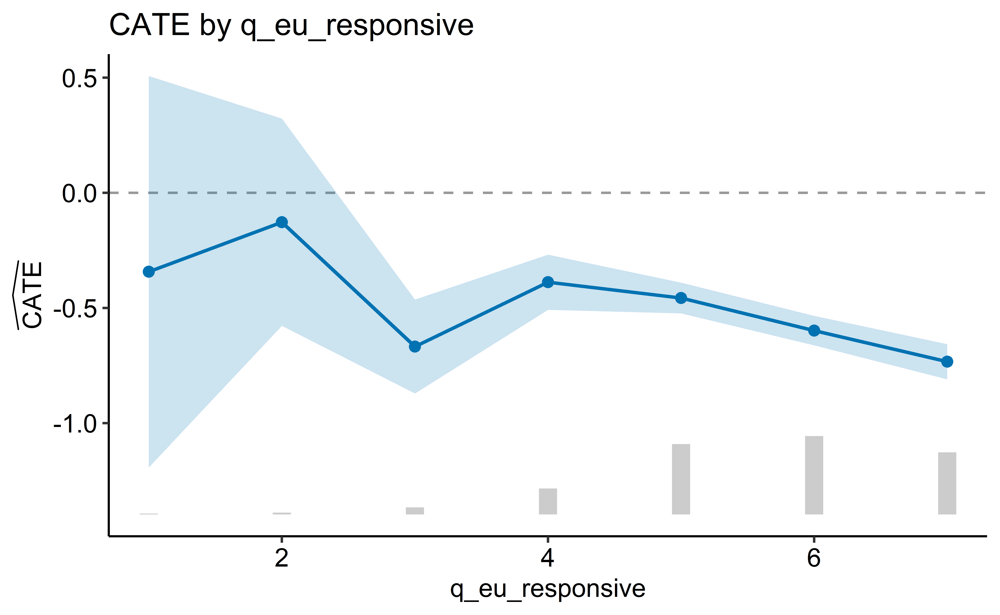

In [ ]:
mod <- "q_eu_responsive"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_econ

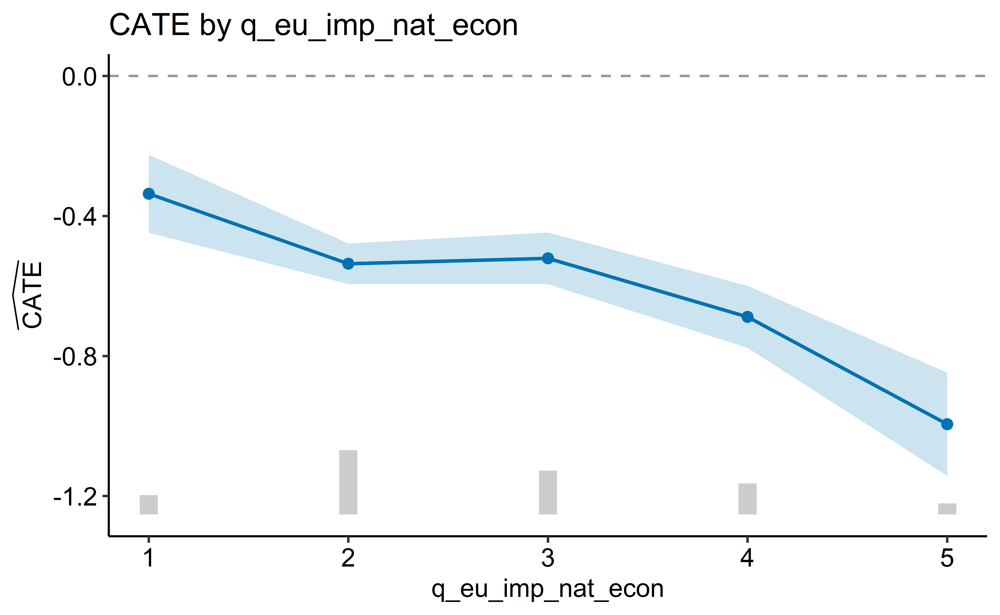

In [ ]:
mod <- "q_eu_imp_nat_econ"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_cul

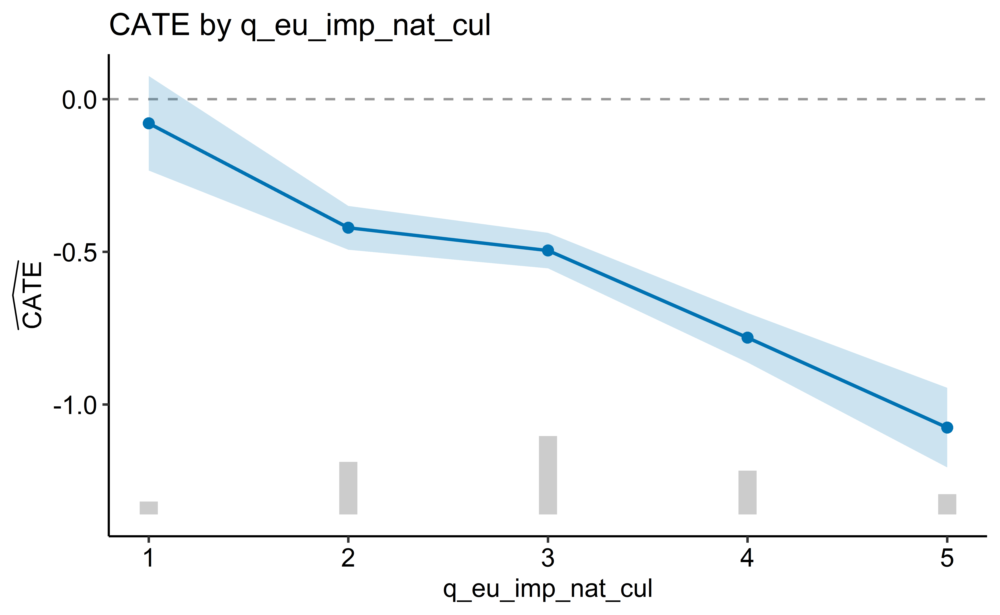

In [ ]:
mod <- "q_eu_imp_nat_cul"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_pol

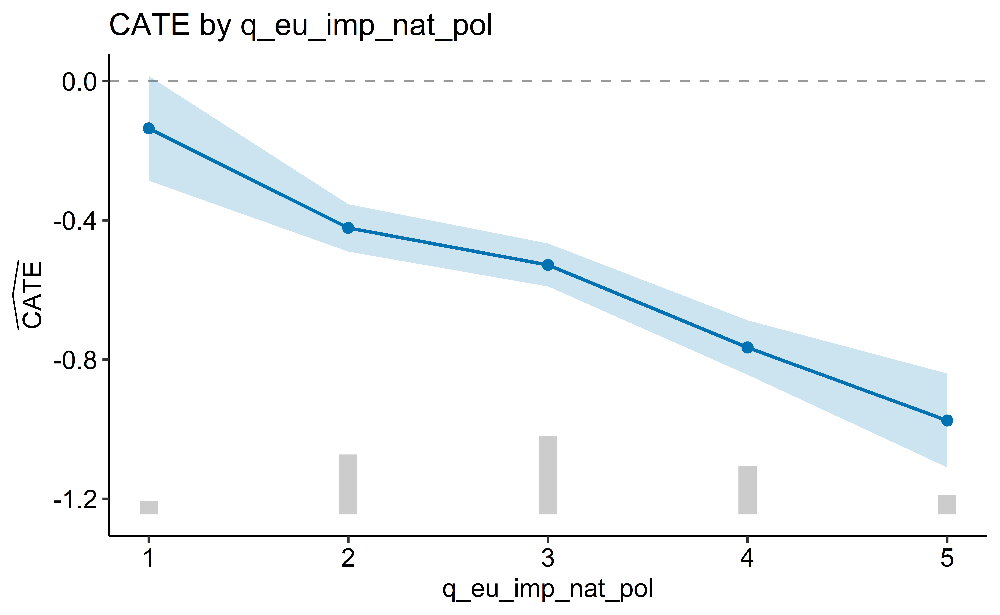

In [ ]:
mod <- "q_eu_imp_nat_pol"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_abolish

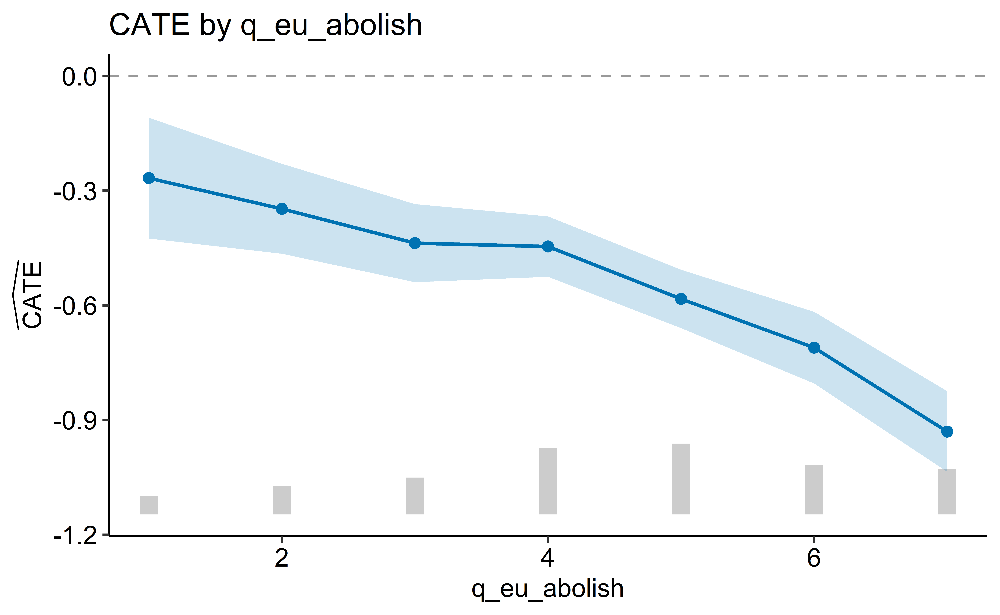

In [ ]:
mod <- "q_eu_abolish"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_satisfaction

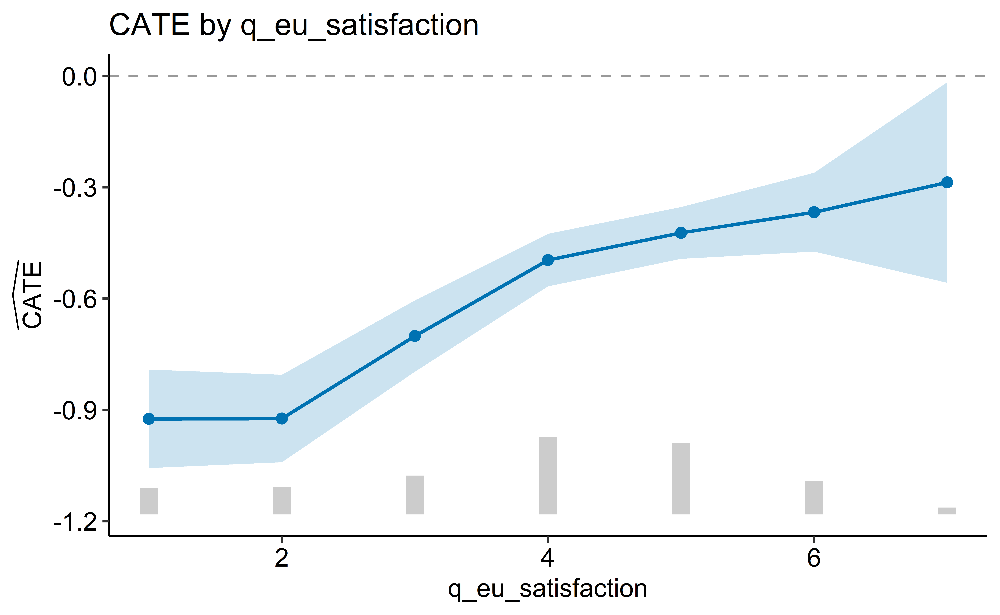

In [ ]:
mod <- "q_eu_satisfaction"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_rural_urban

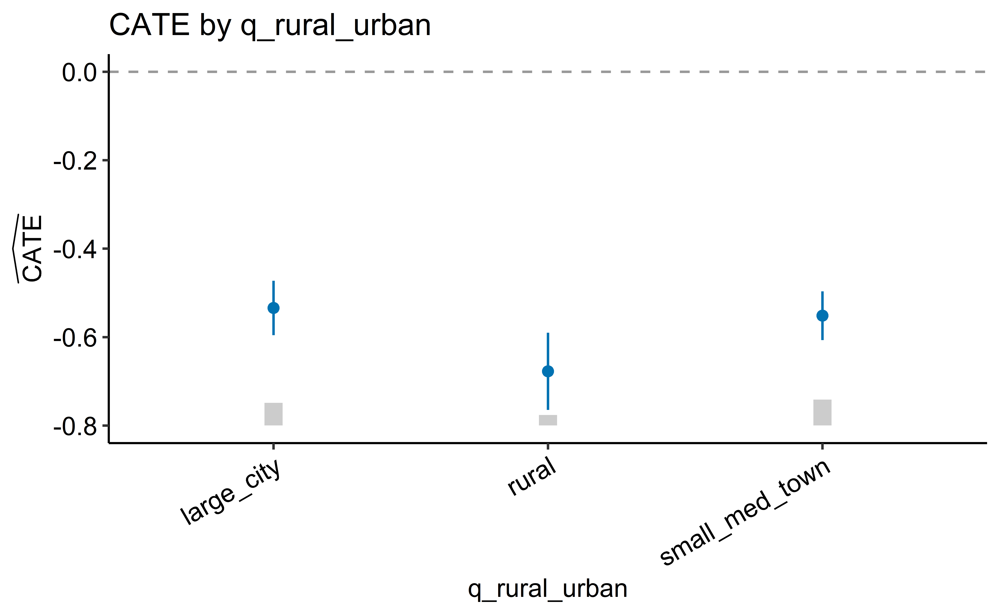

In [ ]:
mod <- "q_rural_urban"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_edu_age_stop

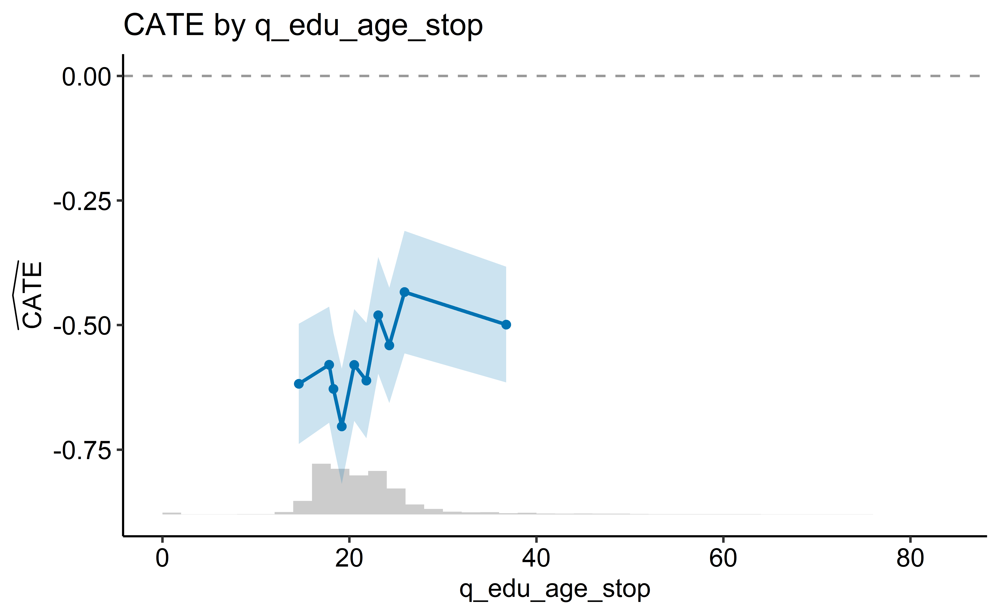

In [ ]:
mod <- "q_edu_age_stop"
col <- m_dict[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


## Trust game

## Average treatment effect

In [ ]:
ate_trust <- grf::average_treatment_effect(cf_trust, target.sample = "all")
cat(sprintf(
  "Trust ATE: %.4f  (SE %.4f);  95%% CI [%.4f, %.4f]\n",
  ate_trust["estimate"],
  ate_trust["std.err"],
  ate_trust["estimate"] - 1.96 * ate_trust["std.err"],
  ate_trust["estimate"] + 1.96 * ate_trust["std.err"]
))


Trust ATE: -0.6440  (SE 0.0205);  95% CI [-0.6841, -0.6039]

## Targeting Operator Characteristic (RATE)

  estimate    std.err             target
 0.2709571 0.02145913 priorities | AUTOC

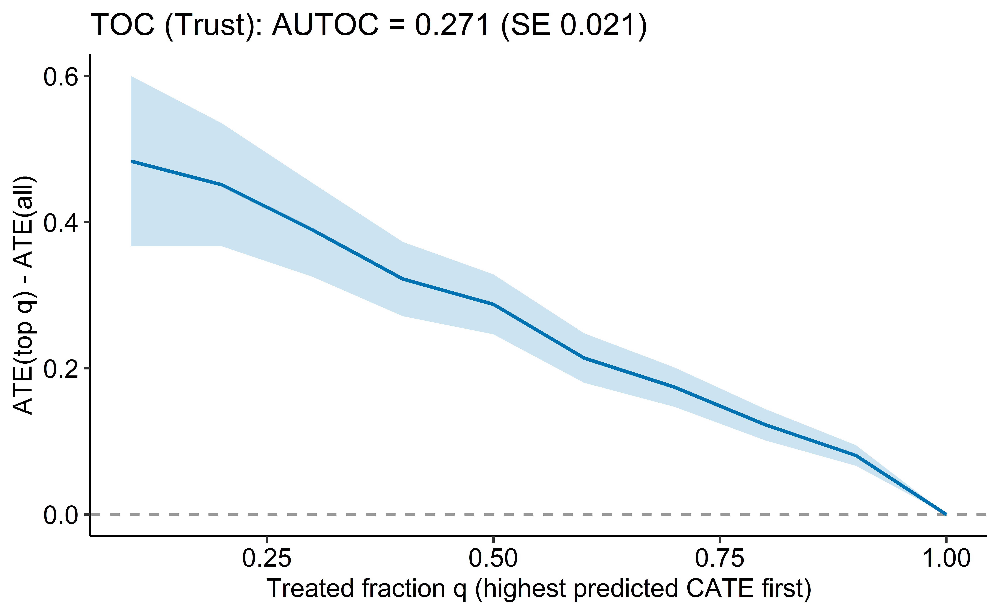

In [ ]:
prio_trust <- predict(cf_trust)$predictions
rate_trust <- grf::rank_average_treatment_effect(cf_trust, prio_trust)
print(rate_trust)


## Best linear projection

In [ ]:
blp_trust <- grf::best_linear_projection(cf_trust, X_trust)
blp_trust_df <- blp_trust |>
  unclass() |>
  as.data.frame() |>
  tibble::rownames_to_column("term") |>
  as_tibble() |>
  rename(estimate = Estimate, std_error = `Std. Error`) |>
  mutate(
    lower = estimate - 1.96 * std_error,
    upper = estimate + 1.96 * std_error
  ) |>
  filter(term != "(Intercept)")

ggplot(blp_trust_df, aes(x = estimate, y = fct_reorder(term, estimate))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), colour = "#0072B2") +
  labs(
    title = "Best linear projection of the CATE (Trust)",
    x = "Projection coefficient",
    y = NULL
  ) +
  ggpubr::theme_pubr()


## Variable importance

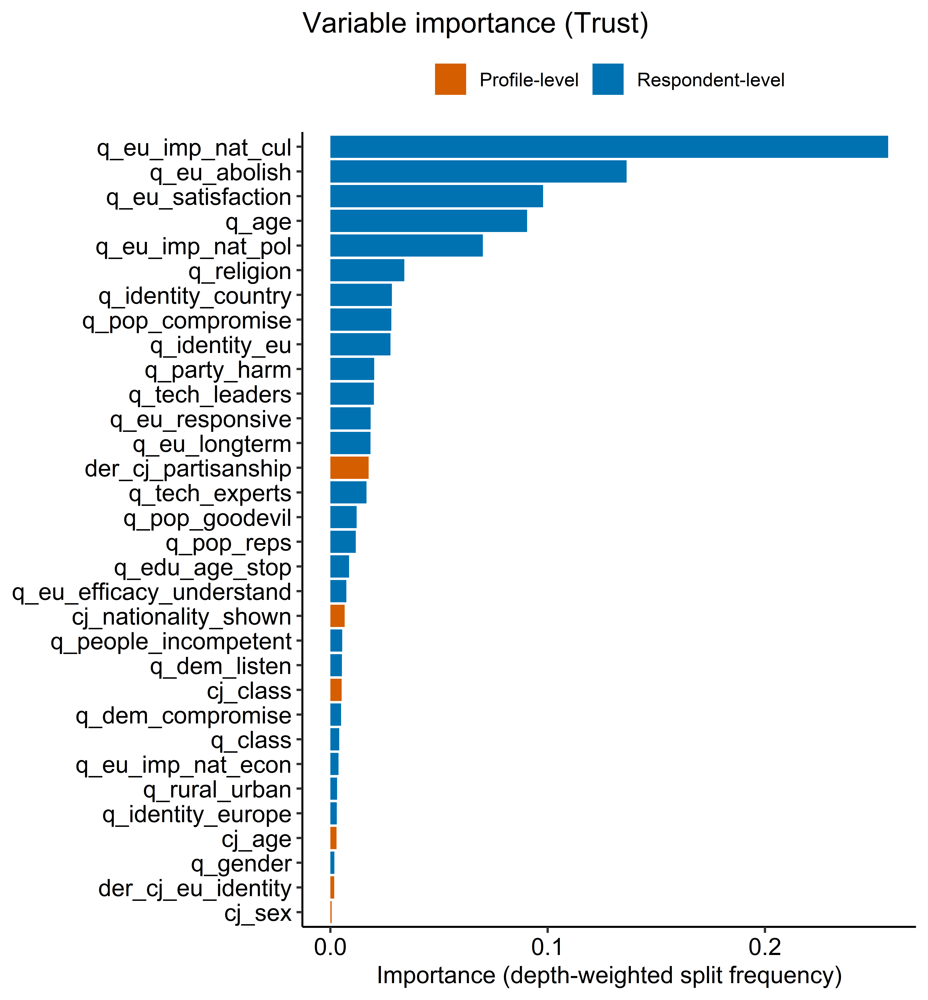

In [ ]:
vi_trust <- grf::variable_importance(cf_trust)
vi_trust_df <- tibble(
  column = colnames(cf_trust$X.orig),
  importance = as.numeric(vi_trust)
) |>
  mutate(
    moderator = map_chr(column, function(cn) {
      hit <- all_mods[startsWith(cn, all_mods)]
      if (length(hit) == 0) NA_character_ else hit[which.max(nchar(hit))]
    })
  ) |>
  filter(!is.na(moderator)) |>
  summarise(importance = sum(importance), .by = moderator) |>
  mutate(
    family = if_else(
      moderator %in% prof_mods,
      "Profile-level",
      "Respondent-level"
    ),
    moderator = fct_reorder(moderator, importance)
  )

ggplot(vi_trust_df, aes(x = importance, y = moderator, fill = family)) +
  geom_col() +
  scale_fill_manual(
    values = c("Profile-level" = "#D55E00", "Respondent-level" = "#0072B2")
  ) +
  labs(
    title = "Variable importance (Trust)",
    x = "Importance (depth-weighted split frequency)",
    y = NULL,
    fill = NULL
  ) +
  ggpubr::theme_pubr()


## CATE by moderator — conjoint round-level

### cj_nationality_shown

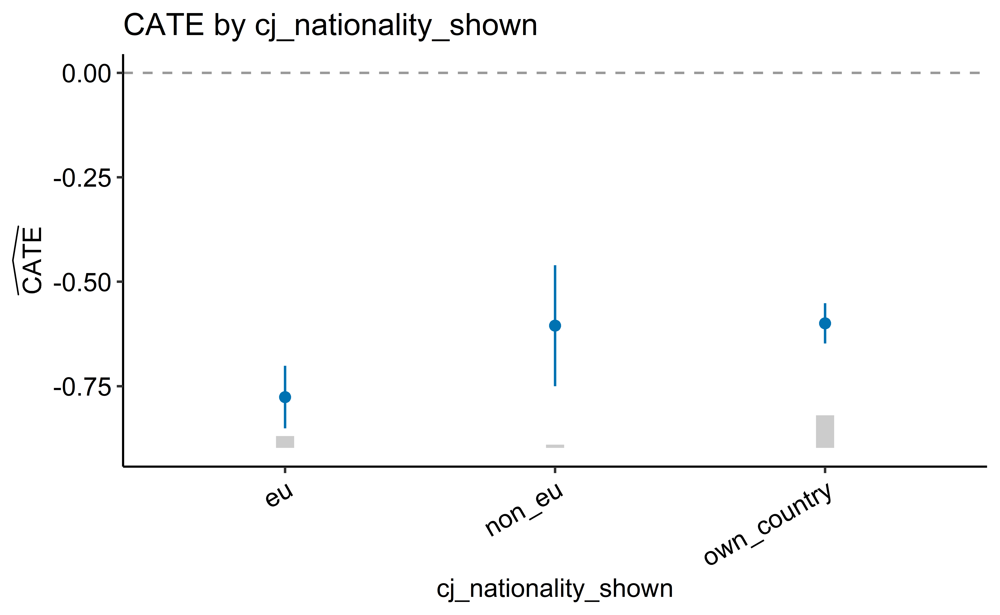

In [ ]:
mod <- "cj_nationality_shown"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### der_cj_eu_identity

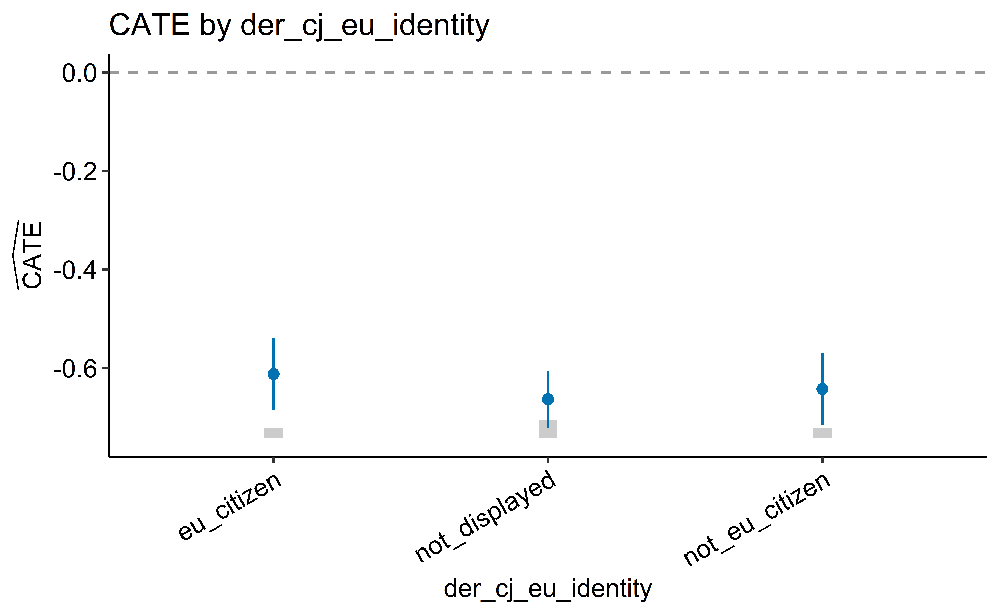

In [ ]:
mod <- "der_cj_eu_identity"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### der_cj_partisanship

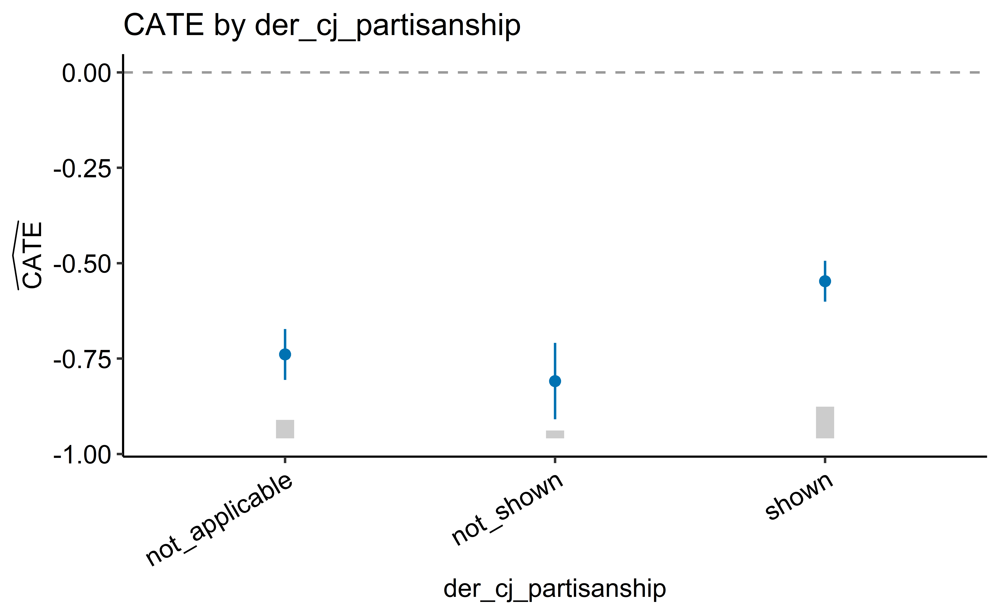

In [ ]:
mod <- "der_cj_partisanship"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### cj_age

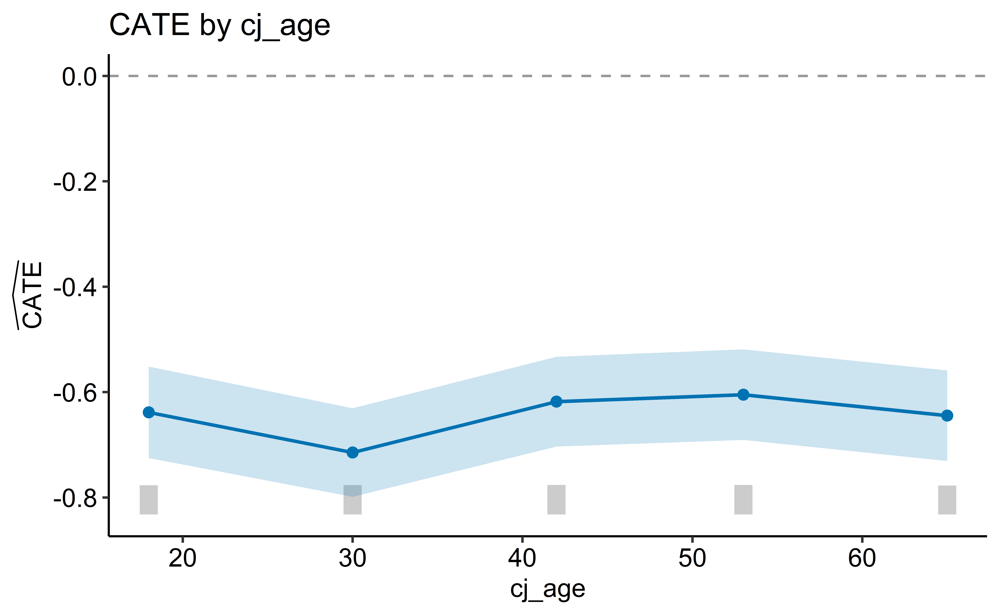

In [ ]:
mod <- "cj_age"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### cj_sex

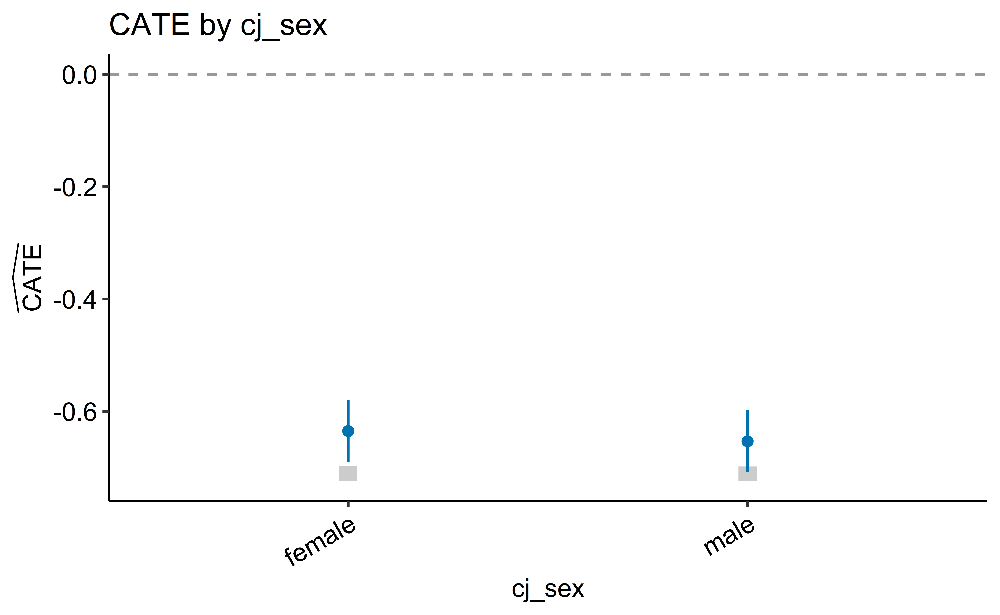

In [ ]:
mod <- "cj_sex"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### cj_class

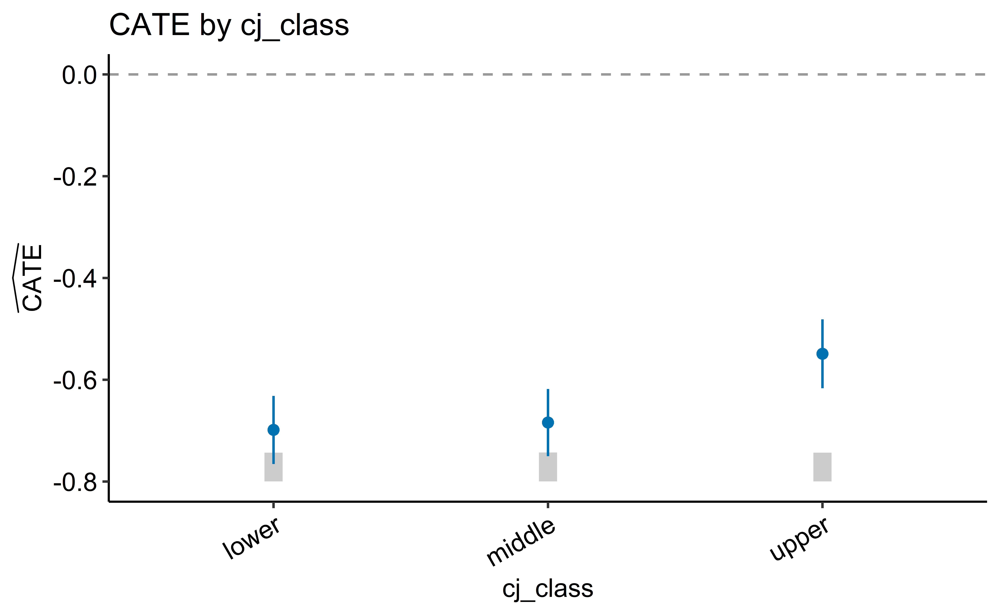

In [ ]:
mod <- "cj_class"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


## CATE by moderator — respondent-level

### q_gender

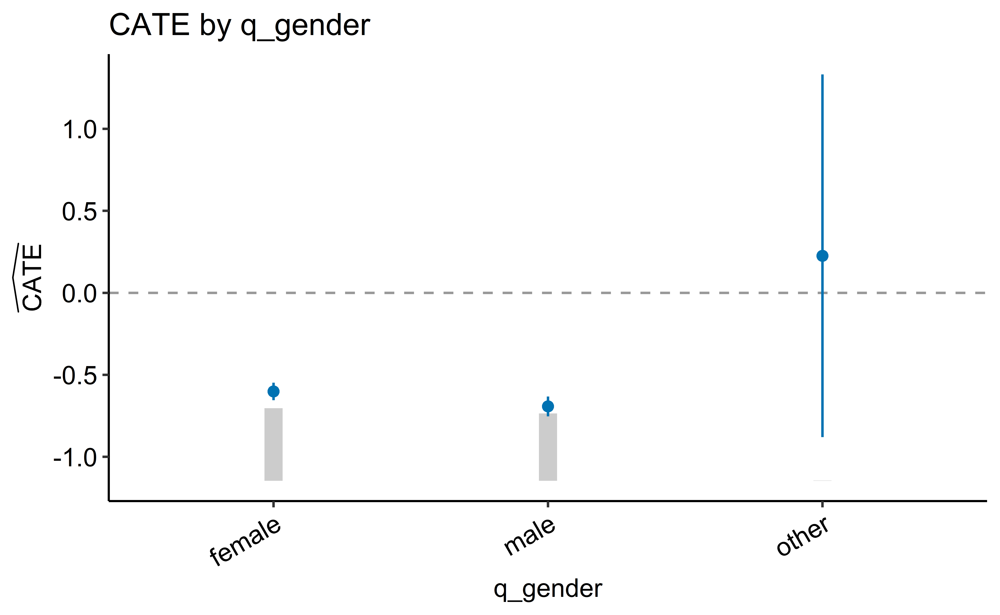

In [ ]:
mod <- "q_gender"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_age

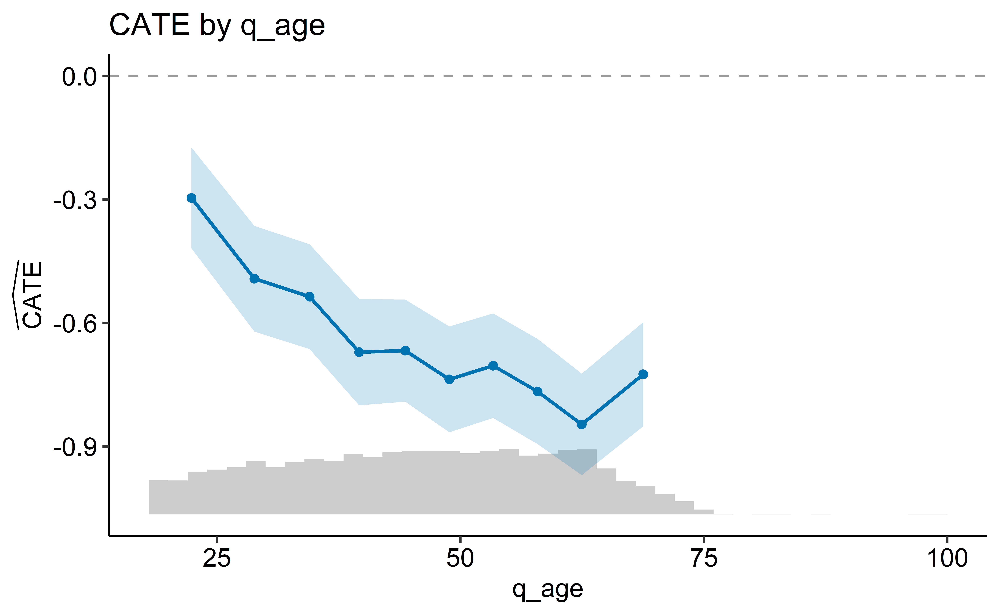

In [ ]:
mod <- "q_age"
col <- m_trust[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_country

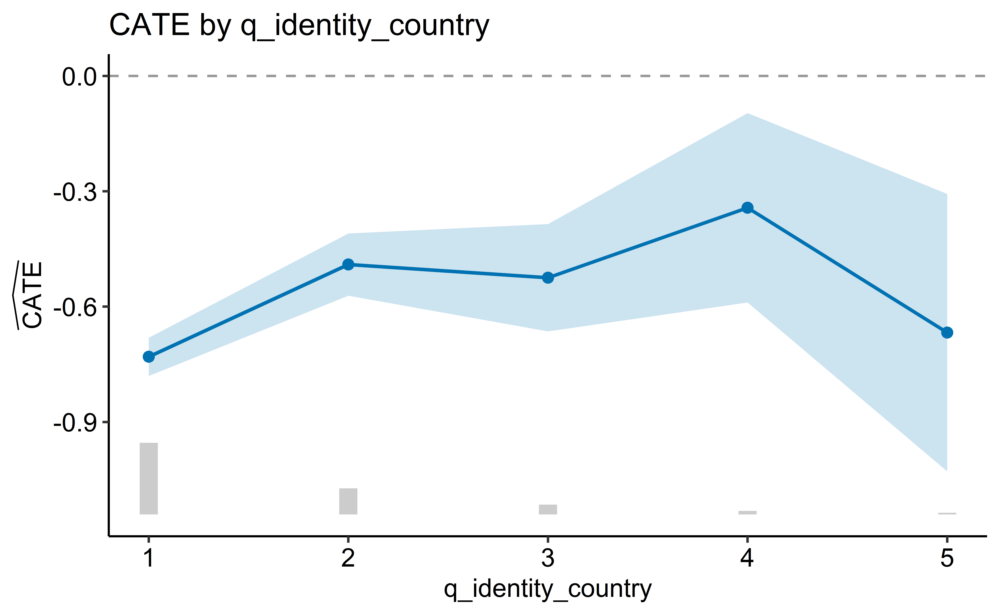

In [ ]:
mod <- "q_identity_country"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_eu

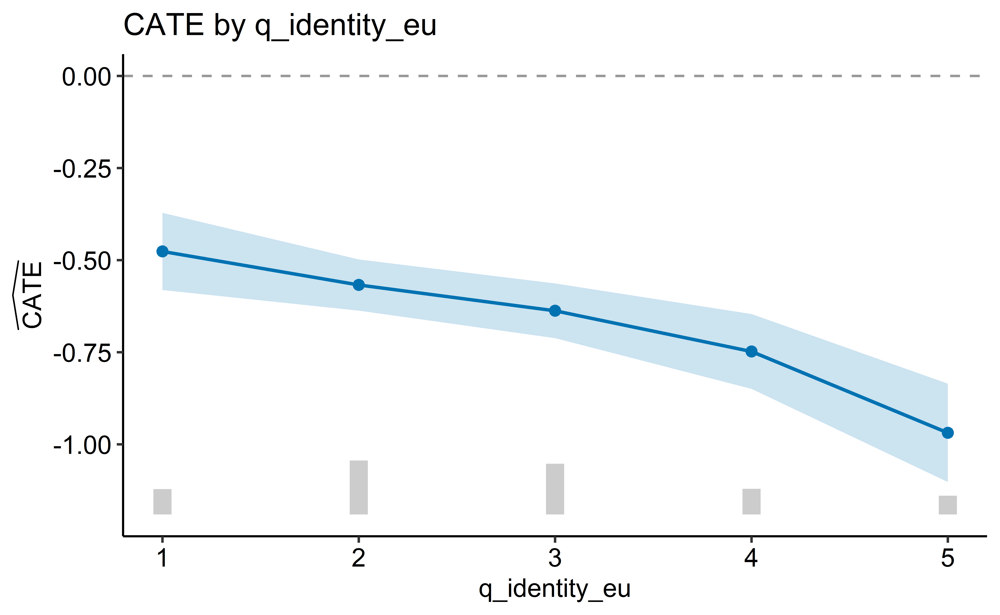

In [ ]:
mod <- "q_identity_eu"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_identity_europe

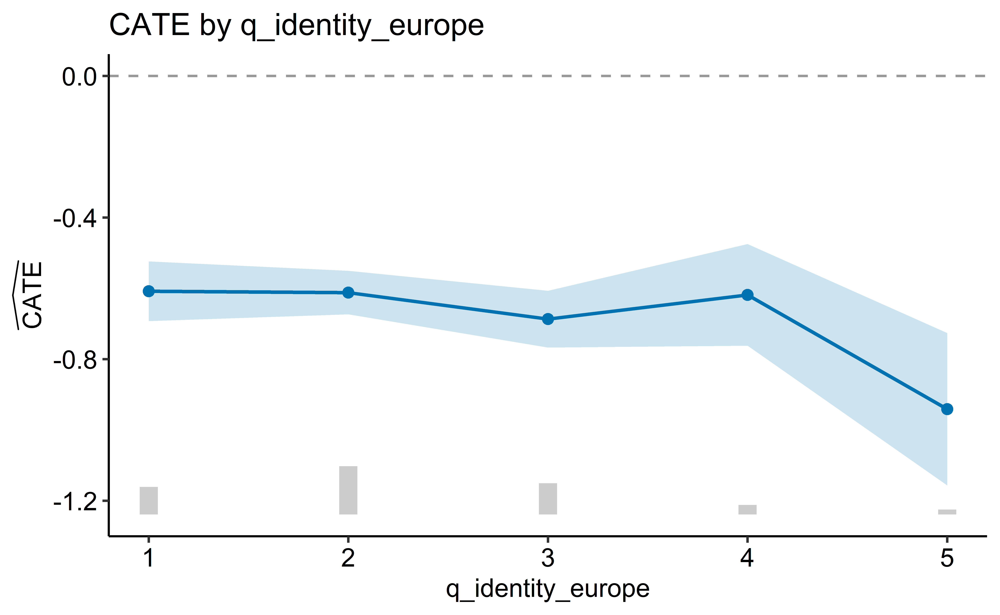

In [ ]:
mod <- "q_identity_europe"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_religion

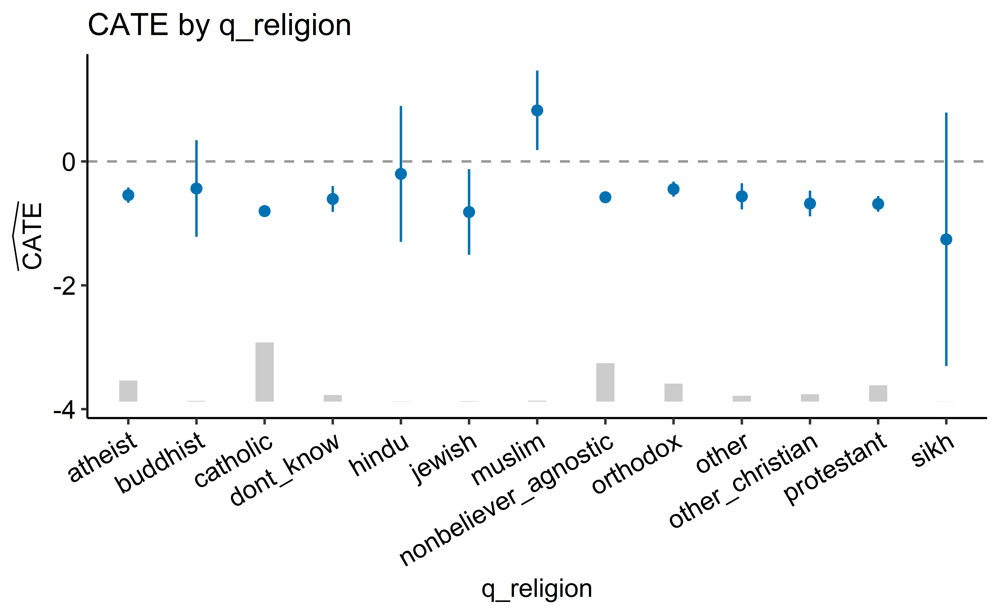

In [ ]:
mod <- "q_religion"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_class

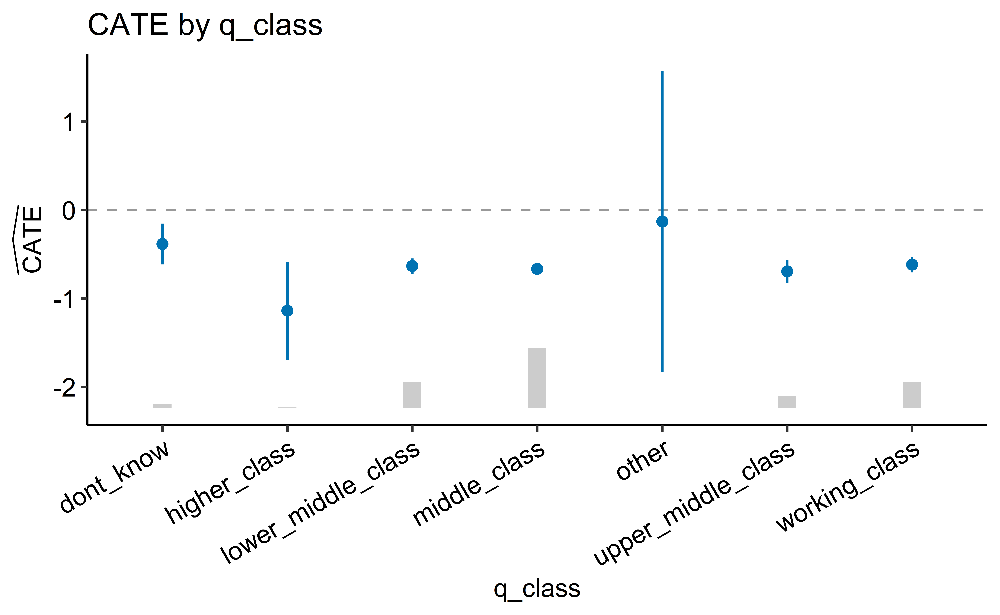

In [ ]:
mod <- "q_class"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_eu_efficacy_understand

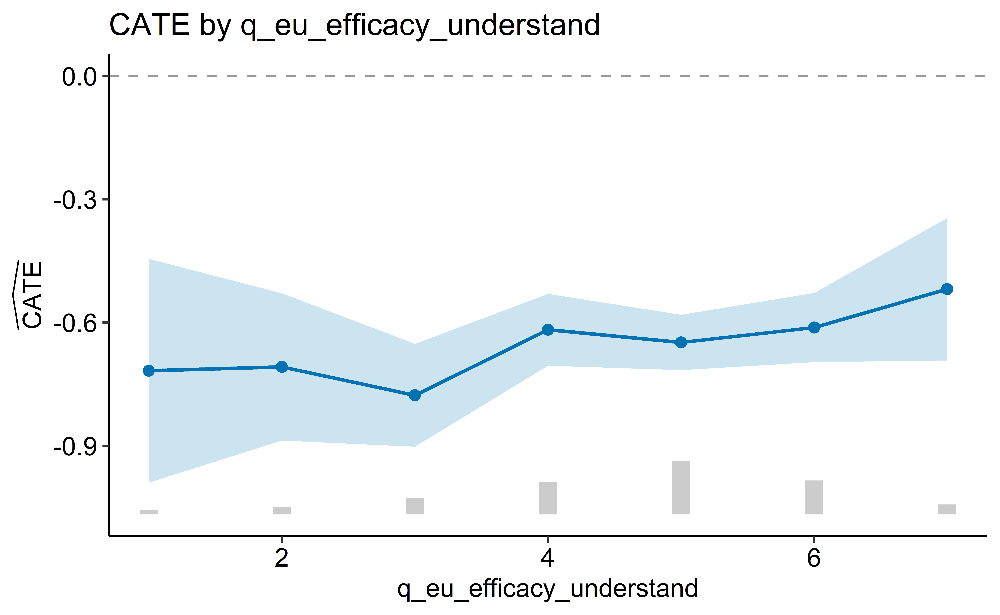

In [ ]:
mod <- "q_eu_efficacy_understand"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_reps

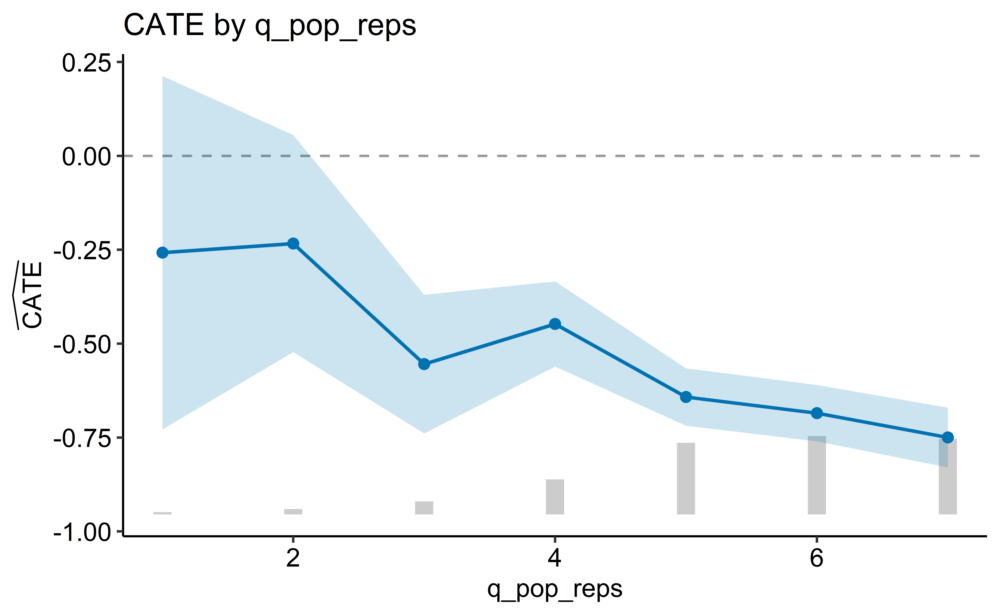

In [ ]:
mod <- "q_pop_reps"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_goodevil

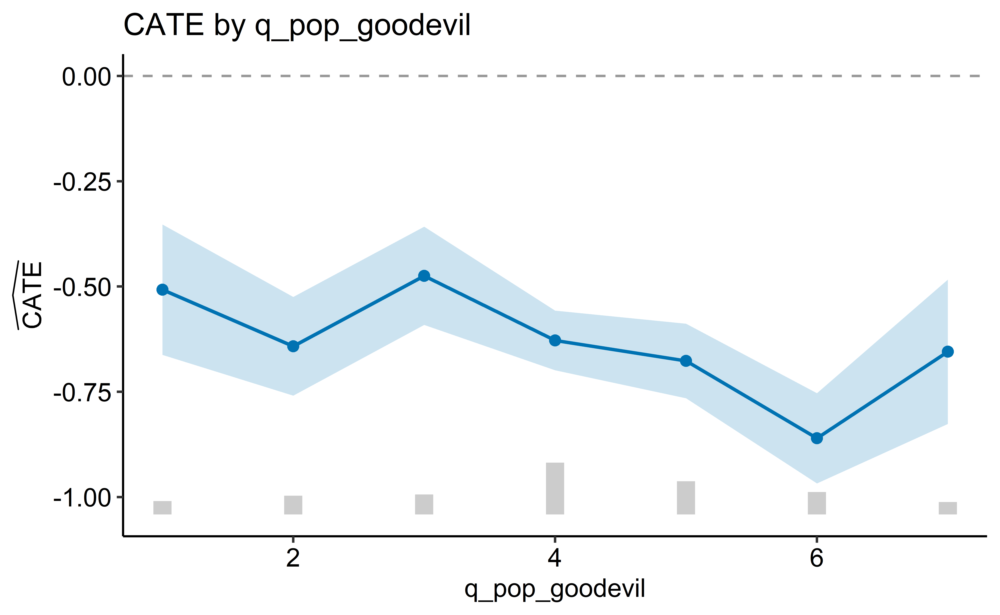

In [ ]:
mod <- "q_pop_goodevil"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_pop_compromise

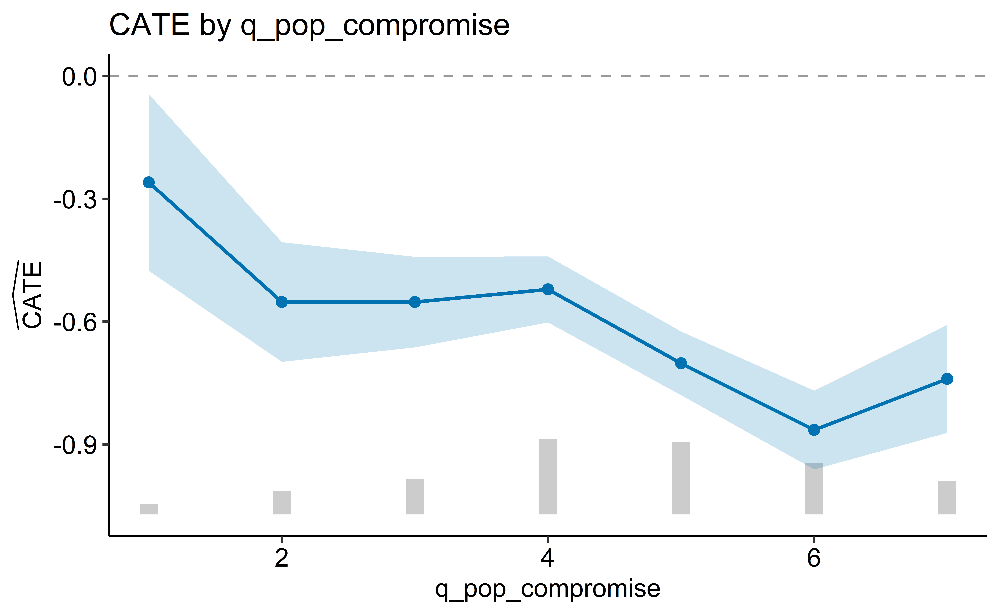

In [ ]:
mod <- "q_pop_compromise"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_dem_compromise

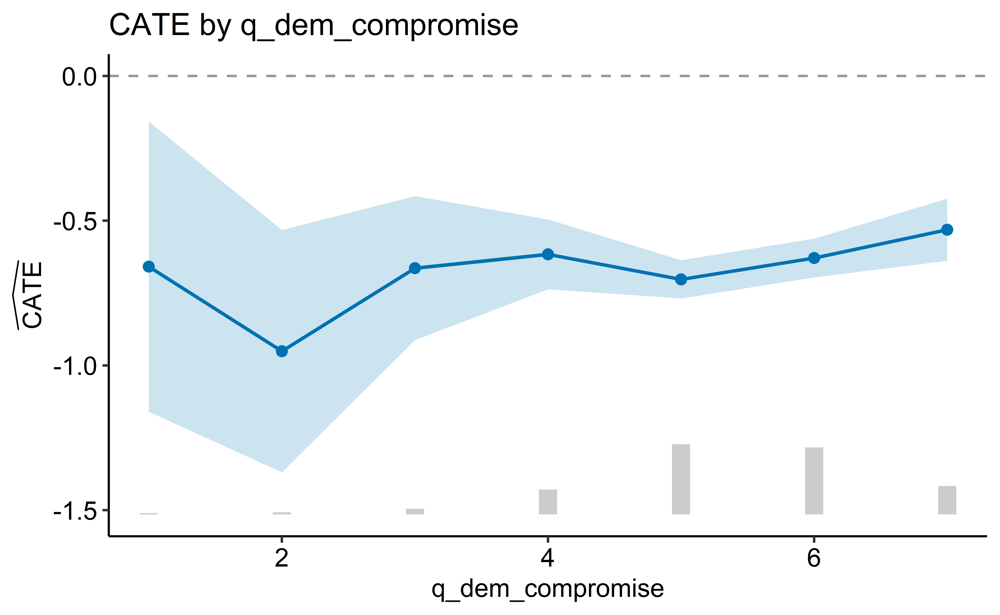

In [ ]:
mod <- "q_dem_compromise"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_dem_listen

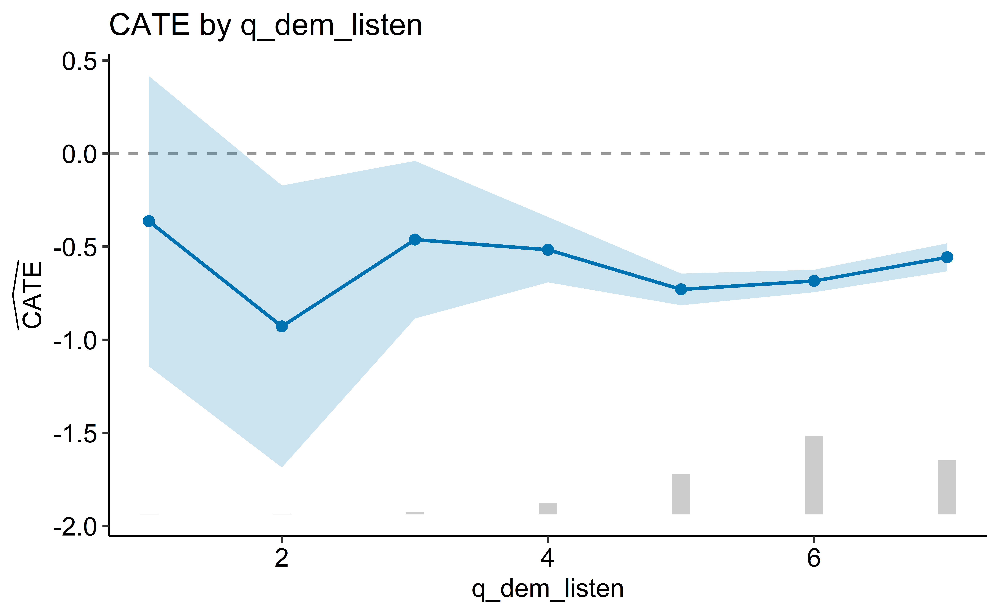

In [ ]:
mod <- "q_dem_listen"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_tech_experts

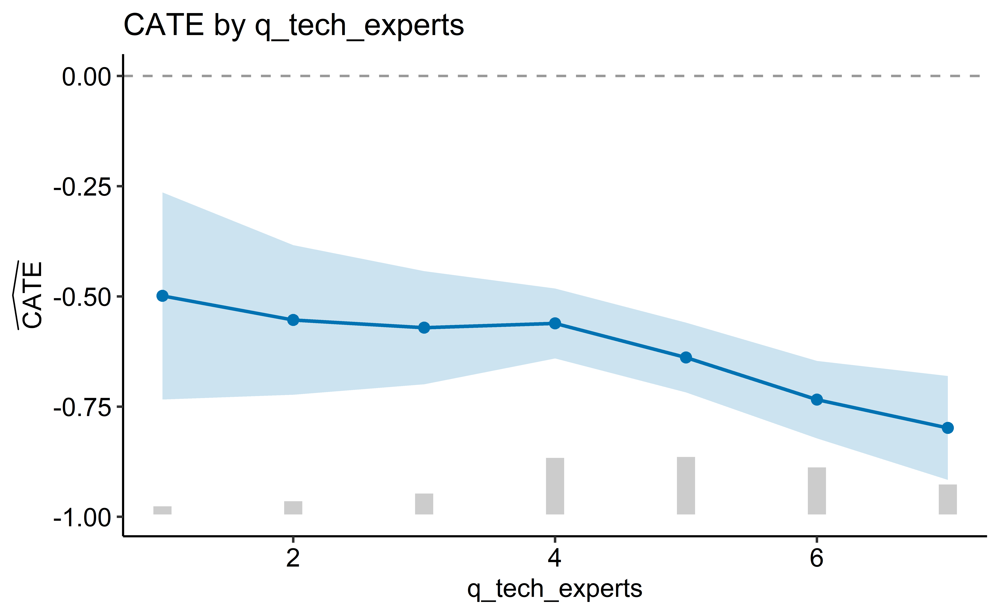

In [ ]:
mod <- "q_tech_experts"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_tech_leaders

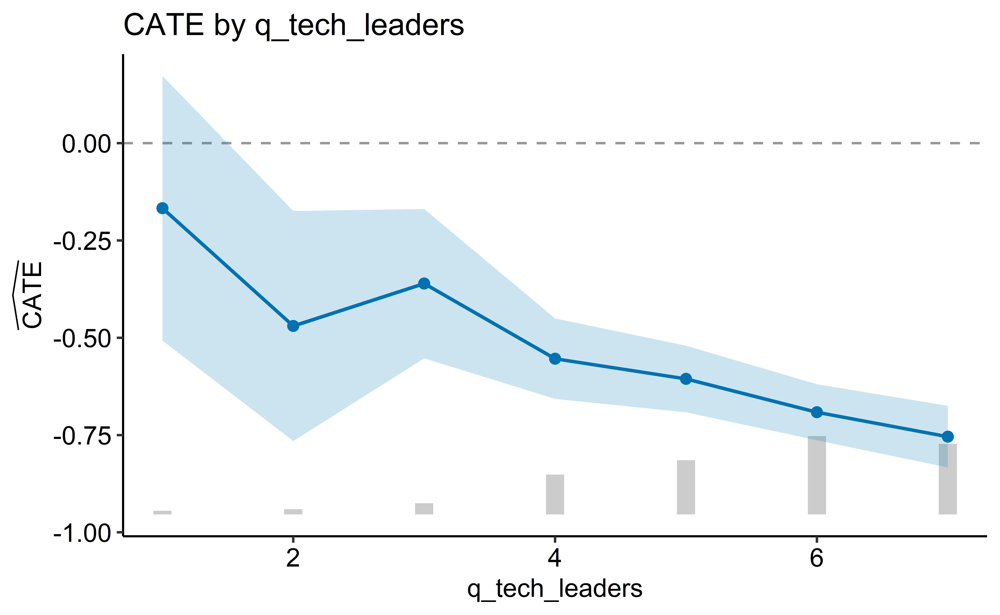

In [ ]:
mod <- "q_tech_leaders"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_party_harm

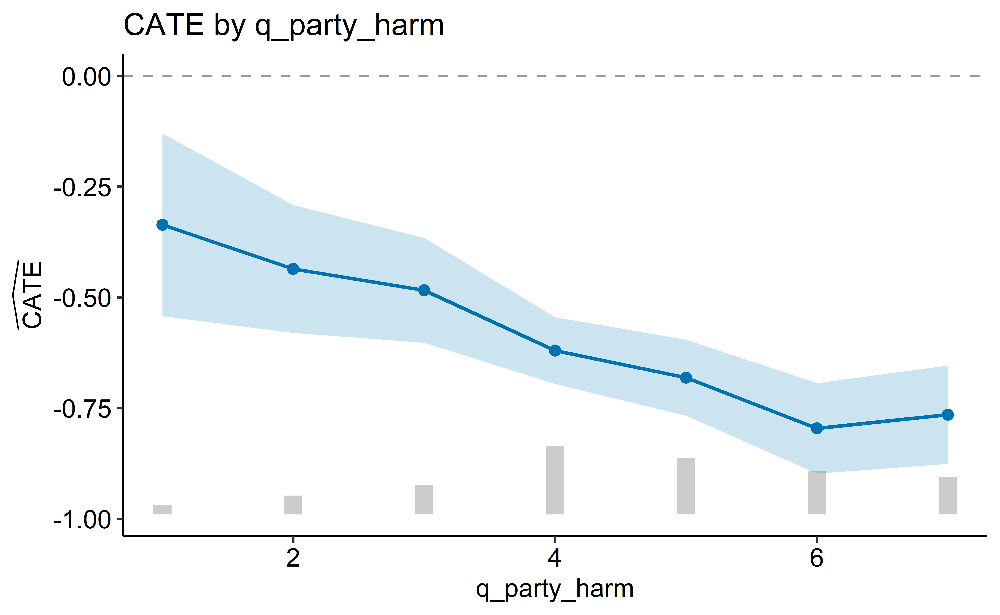

In [ ]:
mod <- "q_party_harm"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_people_incompetent

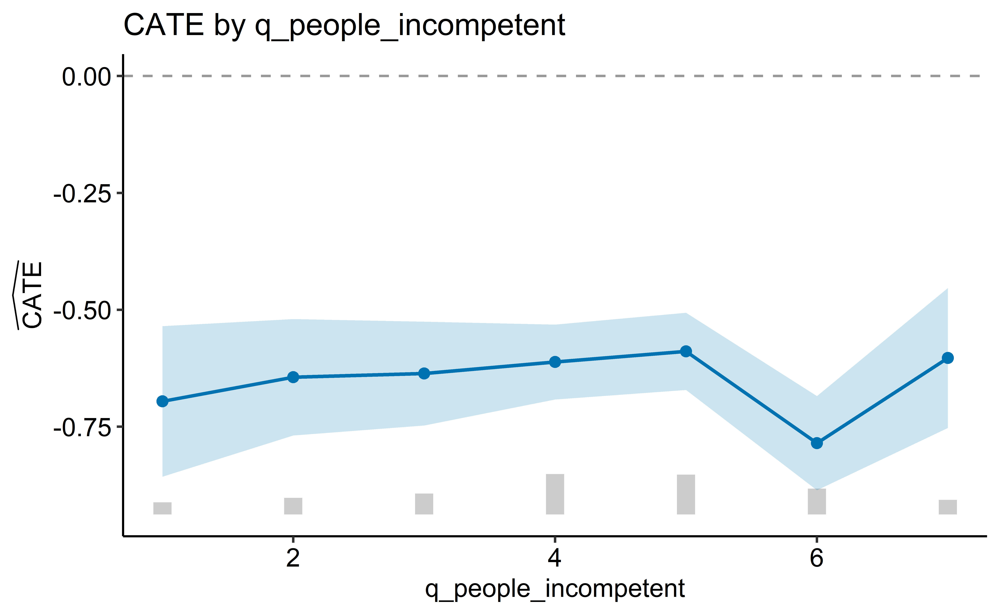

In [ ]:
mod <- "q_people_incompetent"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_longterm

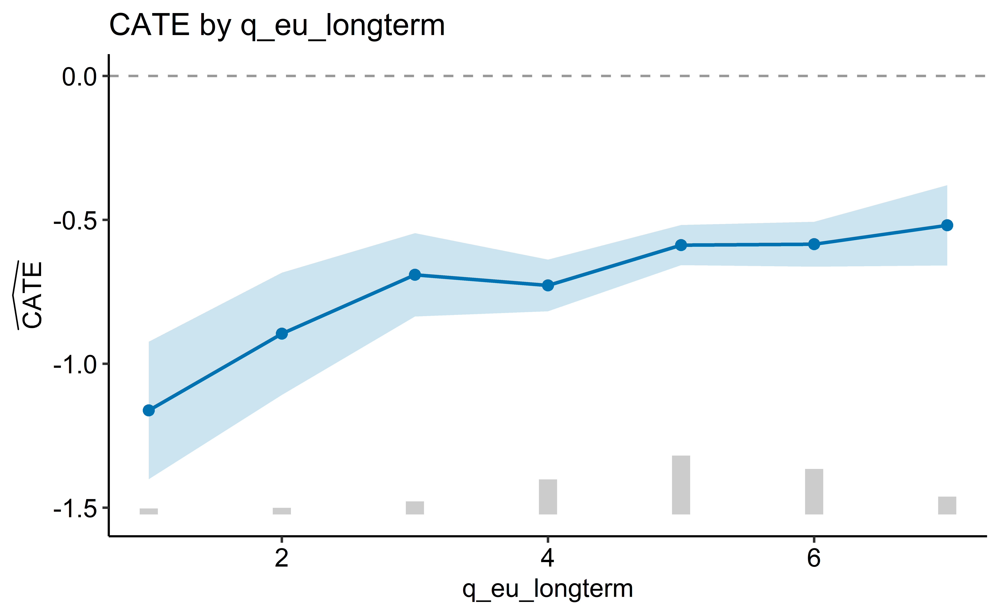

In [ ]:
mod <- "q_eu_longterm"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_responsive

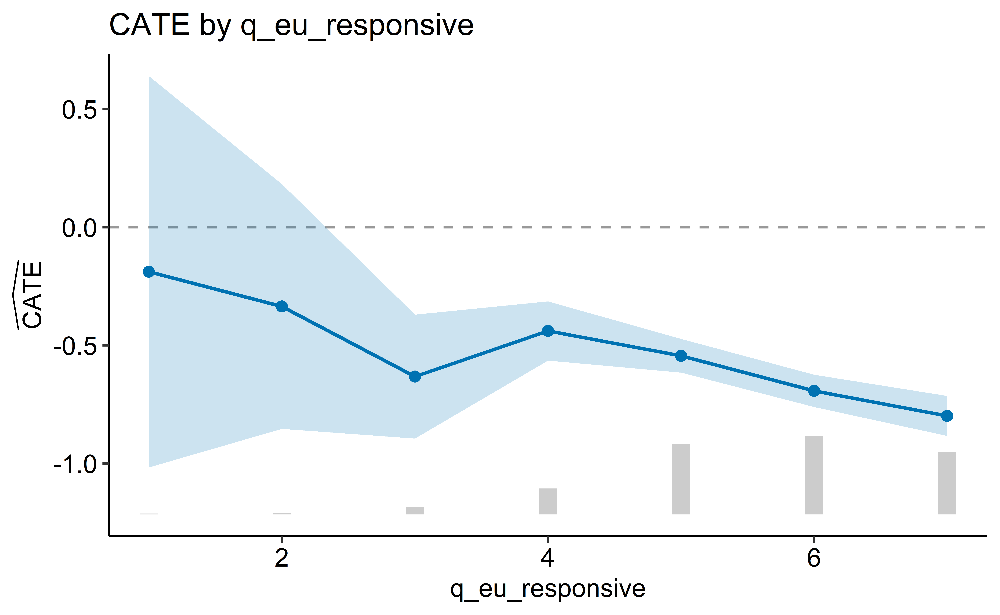

In [ ]:
mod <- "q_eu_responsive"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_econ

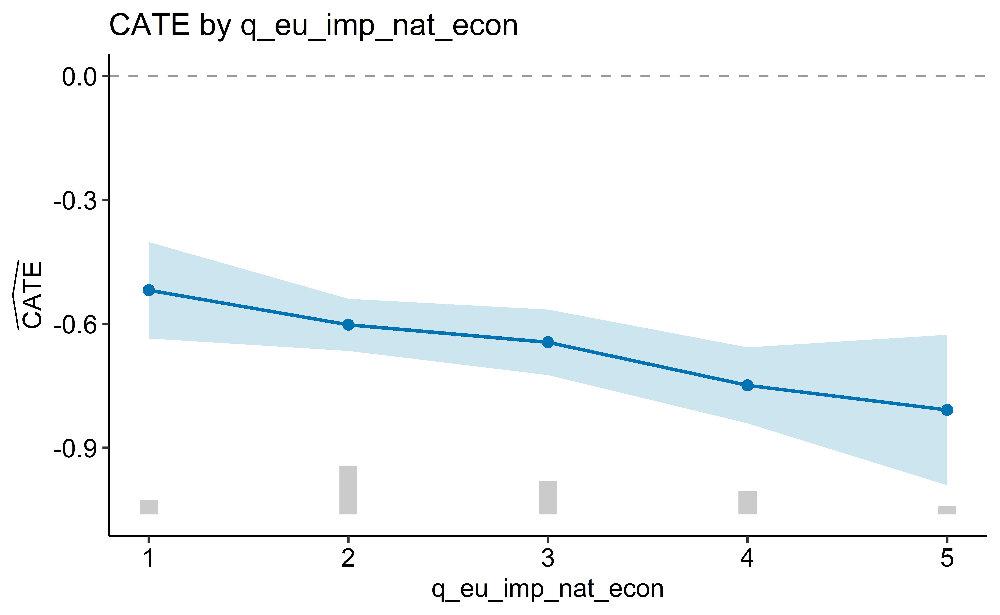

In [ ]:
mod <- "q_eu_imp_nat_econ"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_cul

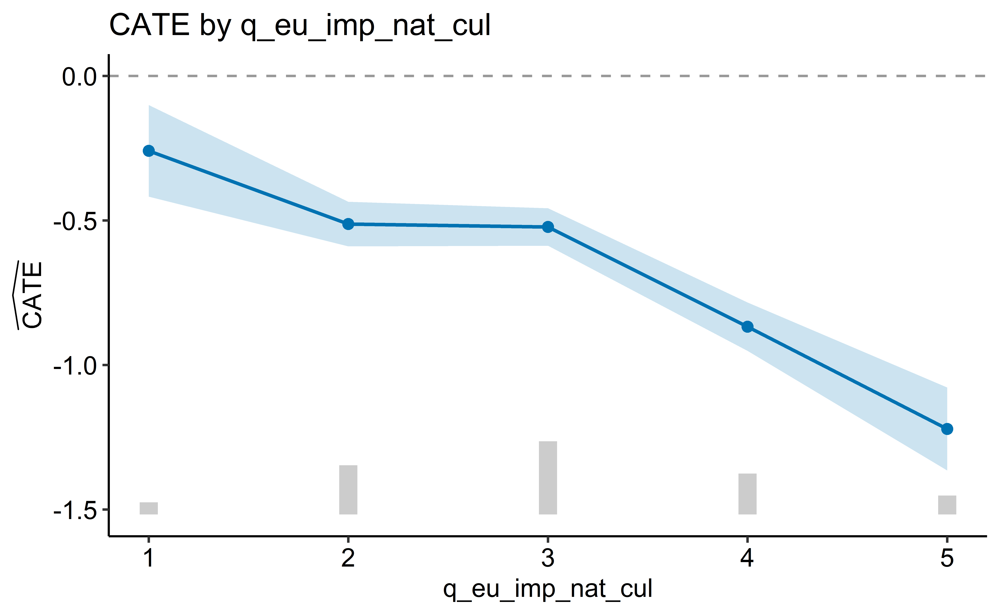

In [ ]:
mod <- "q_eu_imp_nat_cul"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_imp_nat_pol

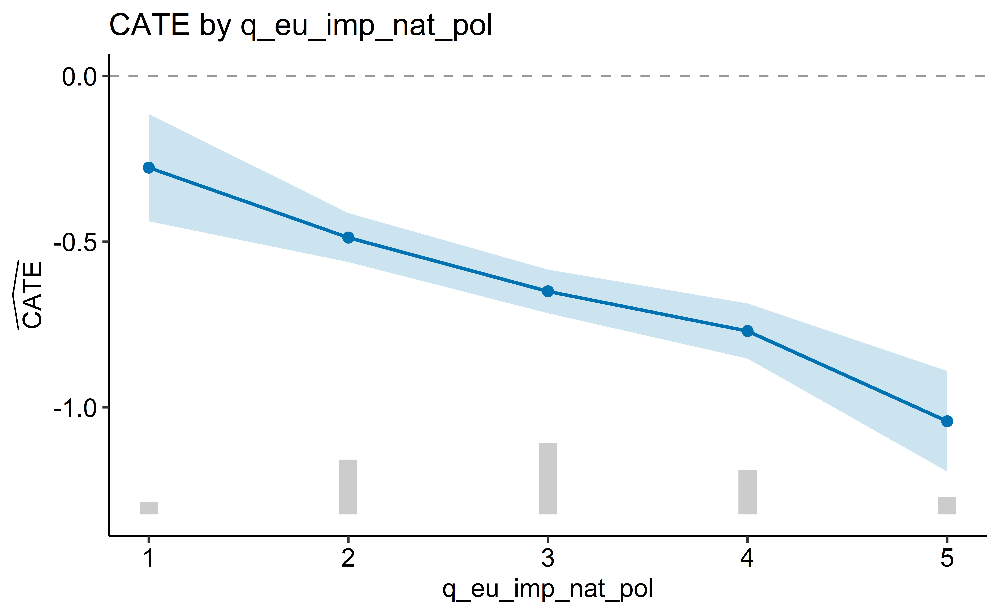

In [ ]:
mod <- "q_eu_imp_nat_pol"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_abolish

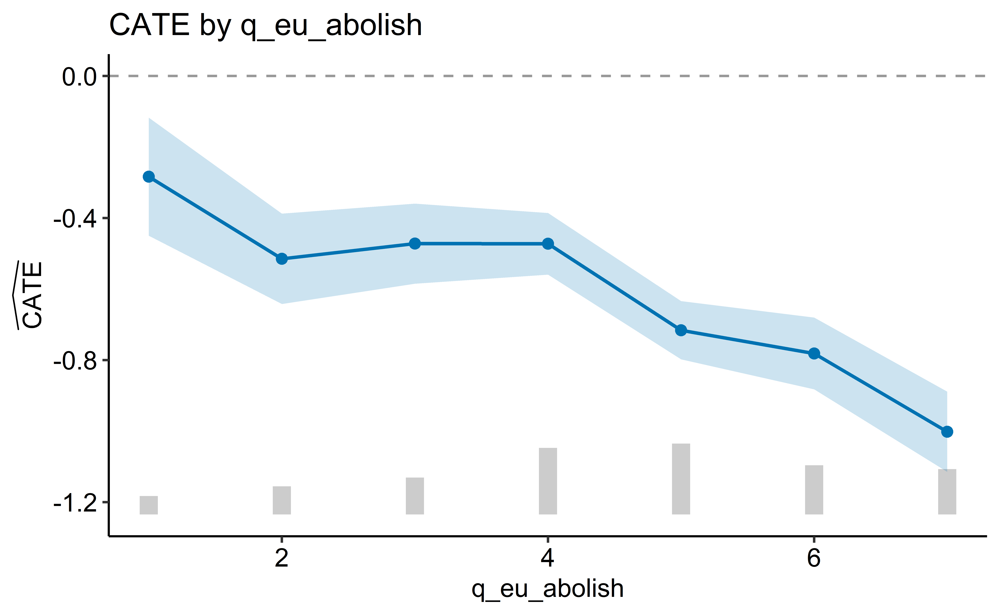

In [ ]:
mod <- "q_eu_abolish"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_eu_satisfaction

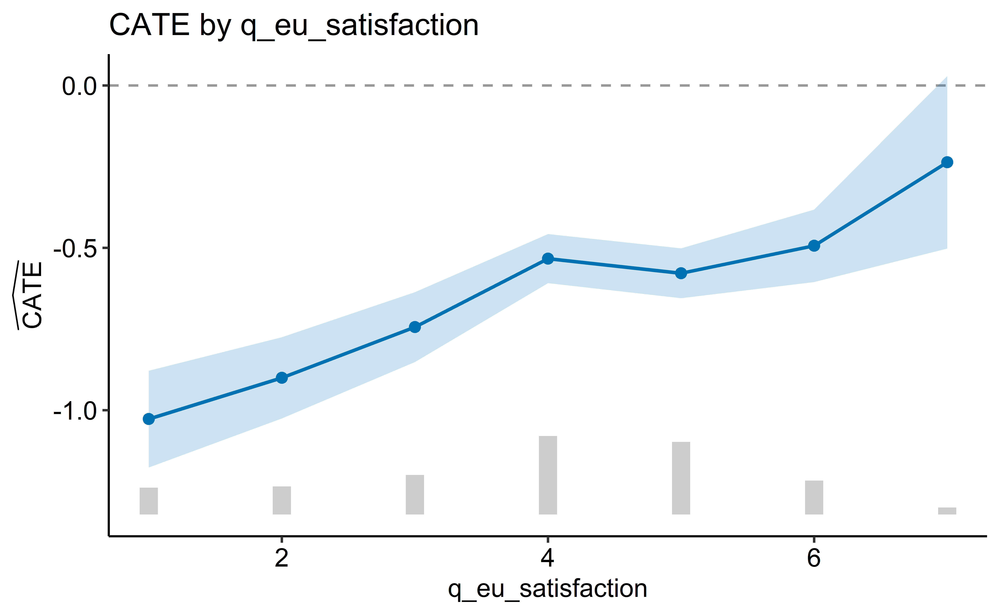

In [ ]:
mod <- "q_eu_satisfaction"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


### q_rural_urban

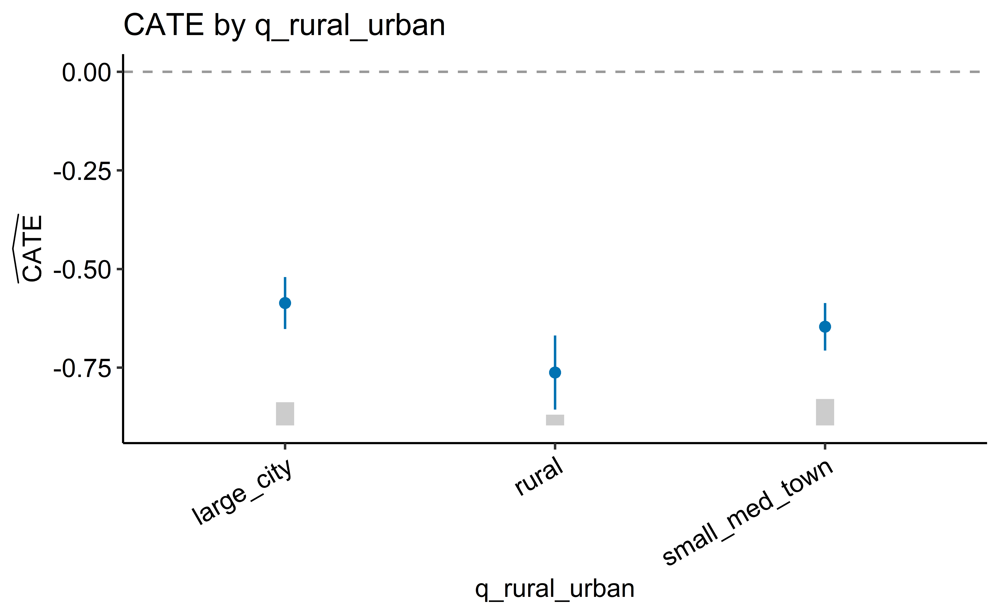

In [ ]:
mod <- "q_rural_urban"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))


### q_edu_age_stop

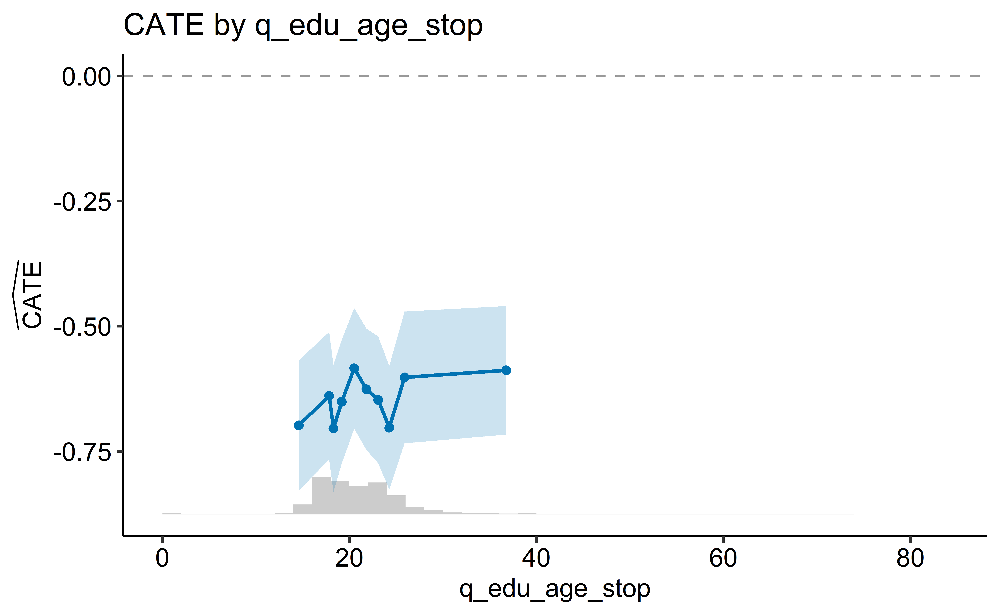

In [ ]:
mod <- "q_edu_age_stop"
col <- m_trust[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()


## Combined figures

The per-game, per-moderator figures above are the detailed view. This section attempts two compact overviews that place every moderator on one canvas and overlay both games at once. Following the house style of `09_additional_figs_tables.qmd`, the two games are the only thing encoded by colour, shape, and linetype, and they are always encoded by all three together, so each game is distinguishable in colour, in greyscale print, and under colourblindness. Every other distinction (which moderator, which level) is carried by facets and axis position.

## House style

The Okabe-Ito game palette with redundant shape and linetype, the three reserved scales, the shared theme, and the golden-ratio helper, copied from `09_additional_figs_tables.qmd`.

In [ ]:
game_labs <- c(cj_dict = "Dictator game", cj_trust = "Trust game")
game_cols <- c("Dictator game" = "#0072B2", "Trust game" = "#D55E00")
game_shapes <- c("Dictator game" = 16, "Trust game" = 17) # circle / triangle
game_ltys <- c("Dictator game" = "solid", "Trust game" = "longdash")

scale_colour_game <- function() {
  scale_colour_manual(values = game_cols, name = NULL)
}
scale_shape_game <- function() {
  scale_shape_manual(values = game_shapes, name = NULL)
}
scale_linetype_game <- function() {
  scale_linetype_manual(values = game_ltys, name = NULL)
}

# shared moderator labels + categorical-first ordering for the facets
source(here::here("code", "helper_scripts", "moderator_labels.R"))

theme_mbeu <- function(base_size = 11) {
  ggpubr::theme_pubr(base_size = base_size) +
    theme(legend.position = "top")
}
ref_zero <- geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60")
dodge <- position_dodge(width = 0.5)
yl_cate <- expression(widehat(CATE))
yl_ric <- expression(hat(tau)[ric]) # profile-level CATE
yl_i <- expression(hat(tau)[ic]) # respondent-level CATE


## Presentational moderator transforms

Two display-only recodings, applied to the plotting copies `m_dict` / `m_trust` only. The forest design matrices `X_dict` / `X_trust` were built far above, so the best linear projection and variable-importance figures are untouched; only the CATE-by-moderator panels below see these. The three identity scales run `1` (most attached) to `5` (least attached); we reverse them to `6 - x` so that, like every other panel, moving right means *more* of the construct (more attachment). The three “EU effect on” items (`q_eu_imp_nat_econ`, `q_eu_imp_nat_cul`, `q_eu_imp_nat_pol`) run `1` (very positive) to `5` (very negative); we reverse them the same way so moving right means a *more positive* evaluation of the EU’s effect. `q_class` is reordered from working class up to higher class, with the non-substantive `dont_know` last, so the facet reads as a status gradient rather than alphabetically.

In [ ]:
class_order <- c(
  "working_class",
  "lower_middle_class",
  "middle_class",
  "upper_middle_class",
  "higher_class",
  "dont_know",
  "other"
)
flip5 <- \(x) 6 - x # 5-point scales: reverse so higher = more of the construct
for (nm in c("m_dict", "m_trust")) {
  assign(
    nm,
    get(nm) |>
      mutate(
        across(
          c(
            q_identity_country,
            q_identity_eu,
            q_identity_europe,
            q_eu_imp_nat_econ,
            q_eu_imp_nat_cul,
            q_eu_imp_nat_pol
          ),
          flip5
        ),
        q_class = factor(q_class, levels = class_order),
        q_rural_urban = factor(
          q_rural_urban,
          levels = c("rural", "small_med_town", "large_city")
        ),
        der_cj_eu_identity = factor(
          der_cj_eu_identity,
          levels = c("eu_citizen", "not_eu_citizen", "not_displayed")
        ),
        der_cj_partisanship = factor(
          der_cj_partisanship,
          levels = c("not_shown", "shown", "not_applicable")
        )
      )
  )
}


## Builders

`cate_one()` returns the per-level (or per-grid-cell, for the two genuinely continuous moderators) subset ATE and 95% CI for one moderator in one game, tagging whether the moderator is an ordered numeric scale (which earns a connecting line) and carrying the per-level count `n`. Discrete levels comprising fewer than 1% of that game’s sample are dropped, because their subset CATE is too imprecisely estimated to compare against the well-populated levels; `cj_age` is treated as discrete (points only, no line) because its five values are fixed conjoint ages, not a continuous scale. The two genuinely continuous moderators are binned on a **fixed display grid** rather than into deciles — `q_age` over 100 equal intervals across 18–75, `q_edu_age_stop` at each integer year 15–30 — so the line spans the full range (decile bins were plotted at their bin *means*, which is why the old `q_age` line began near 25 rather than 18); the 1% rule is not applied to these grid cells, since the full range is shown by design. `build_comb()` stacks that over a set of moderators and both games. `plot_comb()` draws the faceted overview with a free y-axis per facet: grey per-level count bars (pooled over the games shown) along the bottom, points and CIs dodged by game everywhere, plus a connecting line on the ordered-scale facets only.

In [ ]:
# fixed display grids for the two genuinely continuous moderators
cont_grids <- list(
  q_age = seq(18, 75, length.out = 101), # 100 intervals over the full range
  q_edu_age_stop = seq(14.5, 30.5, by = 1) # integer years 15..30
)

cate_one <- function(cf, mm, mod, game_label) {
  v <- mm[[mod]]
  is_num <- is.numeric(v)
  # genuinely continuous moderators
  if (is_num && length(unique(v)) > 12) {
    # fixed-grid moderators: subset ATE per non-empty grid cell, plotted at the
    # cell midpoint so the line spans the full display range
    if (mod %in% names(cont_grids)) {
      br <- cont_grids[[mod]]
      cell <- cut(v, breaks = br, include.lowest = TRUE)
      mids <- (head(br, -1) + tail(br, -1)) / 2
      rows <- lapply(
        which(tabulate(cell, nbins = length(mids)) > 0),
        function(k) {
          sel <- !is.na(cell) & as.integer(cell) == k
          a <- grf::average_treatment_effect(cf, subset = sel)
          tibble(
            mod = mod,
            level = as.character(round(mids[k])),
            order = mids[k],
            is_scale = TRUE,
            game = game_label,
            n = sum(sel),
            estimate = a["estimate"],
            lower = a["estimate"] - 1.96 * a["std.err"],
            upper = a["estimate"] + 1.96 * a["std.err"]
          )
        }
      )
      return(bind_rows(rows))
    }
    # fallback: decile bins, integer labels
    bin <- ntile(v, 10)
    rows <- lapply(sort(unique(bin)), function(k) {
      sel <- bin == k
      a <- grf::average_treatment_effect(cf, subset = sel)
      tibble(
        mod = mod,
        level = as.character(round(mean(v[sel]))),
        order = mean(v[sel]),
        is_scale = TRUE,
        game = game_label,
        n = sum(sel),
        estimate = a["estimate"],
        lower = a["estimate"] - 1.96 * a["std.err"],
        upper = a["estimate"] + 1.96 * a["std.err"]
      )
    })
    return(bind_rows(rows))
  }
  # discrete moderators: honor factor level order; drop levels below 1% of the game sample
  levs <- if (is_num) {
    sort(unique(v))
  } else if (is.factor(v)) {
    levels(droplevels(v))
  } else {
    sort(unique(as.character(v)))
  }
  rows <- lapply(seq_along(levs), function(i) {
    lev <- levs[i]
    sel <- if (is_num) v == lev else as.character(v) == lev
    # drop rare levels (< 1% of the game sample): subset CATE too imprecise to compare
    if (sum(sel) / sum(!is.na(v)) < 0.01) {
      return(NULL)
    }
    a <- grf::average_treatment_effect(cf, subset = sel)
    tibble(
      mod = mod,
      level = as.character(lev),
      order = if (is_num) as.numeric(lev) else i,
      is_scale = is_num && mod != "cj_age",
      game = game_label,
      n = sum(sel),
      estimate = a["estimate"],
      lower = a["estimate"] - 1.96 * a["std.err"],
      upper = a["estimate"] + 1.96 * a["std.err"]
    )
  })
  bind_rows(rows)
}

build_comb <- function(mods) {
  bind_rows(
    bind_rows(lapply(mods, \(m) cate_one(cf_dict, m_dict, m, "Dictator game"))),
    bind_rows(lapply(mods, \(m) cate_one(cf_trust, m_trust, m, "Trust game")))
  ) |>
    mutate(mod = factor(mod, levels = mods))
}

plot_comb <- function(df, ncol, title, ylab = yl_i) {
  d <- df |>
    arrange(mod, order) |>
    mutate(
      key = factor(
        paste0(mod, "@@", level),
        levels = unique(paste0(mod, "@@", level))
      )
    )
  # per-facet grey count bars (pooled over games shown)
  band <- d |>
    summarise(cnt = sum(n), .by = c(mod, key)) |>
    left_join(
      d |>
        summarise(
          floor_y = min(lower) - 0.12 * (max(upper) - min(lower)),
          span = 0.20 * (max(upper) - min(lower)),
          .by = mod
        ),
      by = "mod"
    ) |>
    mutate(bar_top = floor_y + (cnt / max(cnt)) * span, .by = mod)
  d_scale <- dplyr::filter(d, is_scale)
  d_cat <- dplyr::filter(d, !is_scale)
  p <- ggplot(d, aes(x = key, y = estimate, colour = game, shape = game)) +
    geom_segment(
      data = band,
      aes(x = key, xend = key, y = floor_y, yend = bar_top),
      colour = "grey80",
      linewidth = 3,
      inherit.aes = FALSE
    ) +
    ref_zero
  # ordered scales: overlaid ribbon + line + point (continuous-style)
  if (nrow(d_scale) > 0) {
    p <- p +
      geom_ribbon(
        data = d_scale,
        aes(ymin = lower, ymax = upper, fill = game, group = game),
        alpha = 0.15,
        colour = NA
      ) +
      geom_line(data = d_scale, aes(group = game, linetype = game)) +
      geom_point(data = d_scale) +
      scale_fill_manual(values = game_cols, name = NULL)
  }
  # categorical: dodged linerange + point
  if (nrow(d_cat) > 0) {
    p <- p +
      geom_linerange(
        data = d_cat,
        aes(ymin = lower, ymax = upper, linetype = game),
        position = dodge
      ) +
      geom_point(data = d_cat, position = dodge)
  }
  p +
    facet_wrap(
      ~mod,
      scales = "free",
      ncol = ncol,
      labeller = labeller(mod = mod_strip)
    ) +
    scale_colour_game() +
    scale_shape_game() +
    scale_linetype_game() +
    scale_x_discrete(labels = relabel_key) +
    labs(title = title, x = NULL, y = ylab) +
    guides(fill = "none", linetype = "none") +
    theme_mbeu() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 7))
}

# one continuous moderator: fixed-grid CATE ribbon + real histogram, x trimmed to xlim
cont_panel <- function(mod, xlim, ylab = yl_i) {
  d <- build_comb(mod)
  # covariate distribution within the visible range
  v <- m_dict[[mod]]
  v <- v[!is.na(v) & v >= xlim[1] & v <= xlim[2]]
  h <- hist(v, breaks = 30, plot = FALSE)
  floor_y <- min(d$lower) - 0.12 * (max(d$upper) - min(d$lower))
  span <- 0.20 * (max(d$upper) - min(d$lower))
  hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
    mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
  ggplot(d, aes(x = order, y = estimate, colour = game, shape = game)) +
    geom_rect(
      data = hd,
      aes(
        xmin = mid - w / 2,
        xmax = mid + w / 2,
        ymin = floor_y,
        ymax = bar_top
      ),
      fill = "grey80",
      inherit.aes = FALSE
    ) +
    ref_zero +
    geom_ribbon(
      aes(ymin = lower, ymax = upper, fill = game, group = game),
      alpha = 0.15,
      colour = NA
    ) +
    geom_line(aes(group = game, linetype = game)) +
    geom_point() +
    scale_colour_game() +
    scale_shape_game() +
    scale_linetype_game() +
    scale_fill_manual(values = game_cols, name = NULL) +
    scale_x_continuous(breaks = scales::breaks_pretty(6)) +
    coord_cartesian(xlim = xlim) +
    labs(title = mod_labels[[mod]], x = "Covariate value (years)", y = ylab) +
    theme_mbeu()
}


## Conjoint-round moderators, both games

All five conjoint-round (profile-level) moderators on one canvas, Dictator and Trust overlaid. All five are categorical (including `cj_age`, whose five values are fixed conjoint ages), so each is drawn as dodged points with cluster-robust interval bars, the two games keyed by colour, shape, and linetype together.

In [ ]:
comb_prof <- build_comb(prof_mods)
plot_comb(
  comb_prof,
  ncol = 3,
  title = bquote(
    "CATE by conjoint-round moderator, both games" ~ (hat(tau)[ric])
  ),
  ylab = yl_ric
)


## Individual-level moderators, both games

The respondent-level moderators on two figures so the facets stay legible. Each figure stacks (via `patchwork`) a faceted panel of half the discrete moderators on top with one of the two genuinely continuous moderators (`q_age`, `q_edu_age_stop`) on a continuous x-axis below, so the continuous covariate keeps its real histogram and trimmed axis while still sitting beside the discrete moderators it belongs with. Ordered numeric scales (the 5- and 7-point items) now carry the same ribbon styling as the continuous panels — an overlaid 95% CI band plus connecting line per game; categorical moderators keep dodged points and CIs. The three identity scales (`q_identity_country`, `q_identity_eu`, `q_identity_europe`) are reversed for display so higher on the x-axis means *more* attachment, the three “EU effect on” items (`q_eu_imp_nat_econ`, `q_eu_imp_nat_cul`, `q_eu_imp_nat_pol`) are reversed so higher means a *more positive* evaluation, and `q_class` is ordered from working class up to higher class with `dont_know` last. The shared game legend is drawn once, from the top panel.

In [ ]:
resp_cat <- setdiff(resp_mods, c("q_age", "q_edu_age_stop"))
# categorical moderators first, then the ordered scales
resp_cat <- c(intersect(cat_mods, resp_cat), setdiff(resp_cat, cat_mods))
half <- ceiling(length(resp_cat) / 2)
resp_half1 <- resp_cat[1:half]
resp_half2 <- resp_cat[(half + 1):length(resp_cat)]


In [ ]:
comb_resp1 <- build_comb(resp_half1)
p_resp1 <- plot_comb(
  comb_resp1,
  ncol = 4,
  title = bquote(
    "CATE by individual-level moderator, both games (1 of 2)" ~ (hat(tau)[ic])
  )
)
p_age <- cont_panel("q_age", c(18, 75)) +
  guides(colour = "none", shape = "none", fill = "none", linetype = "none")
(p_resp1 / p_age) + plot_layout(heights = c(3, 1))


In [ ]:
comb_resp2 <- build_comb(resp_half2)
p_resp2 <- plot_comb(
  comb_resp2,
  ncol = 4,
  title = bquote(
    "CATE by individual-level moderator, both games (2 of 2)" ~ (hat(tau)[ic])
  )
)
p_edu <- cont_panel("q_edu_age_stop", c(15, 30)) +
  guides(colour = "none", shape = "none", fill = "none", linetype = "none")
(p_resp2 / p_edu) + plot_layout(heights = c(3, 1))


## Diagnostics, both games

The three per-game diagnostics — the TOC/AUTOC curve, the best linear projection, and the construct-level variable importance — placed on one canvas each with the two games overlaid, reusing the objects already computed in the per-game sections above. Game is carried by colour (and, where a geom supports it, shape and linetype); every other distinction is carried by axis position or facet.

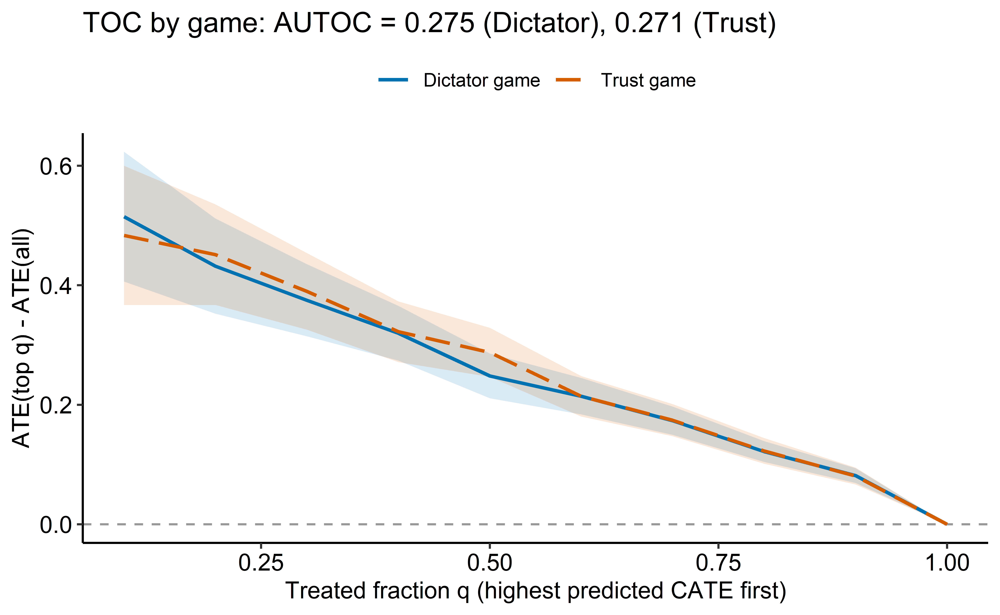

In [ ]:
toc_comb <- bind_rows(
  toc_dict |> mutate(game = "Dictator game"),
  toc_trust |> mutate(game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))

ggplot(toc_comb, aes(x = q, y = estimate, colour = game)) +
  ref_zero +
  geom_ribbon(
    aes(ymin = lower, ymax = upper, fill = game, group = game),
    alpha = 0.15,
    colour = NA
  ) +
  geom_line(aes(linetype = game), linewidth = 0.8) +
  scale_colour_game() +
  scale_linetype_game() +
  scale_fill_manual(values = game_cols, name = NULL) +
  guides(fill = "none") +
  labs(
    title = sprintf(
      "TOC by game: AUTOC = %.3f (Dictator), %.3f (Trust)",
      rate_dict$estimate,
      rate_trust$estimate
    ),
    x = "Treated fraction q (highest predicted CATE first)",
    y = "ATE(top q) - ATE(all)"
  ) +
  theme_mbeu()


In [ ]:
blp_comb <- bind_rows(
  blp_dict_df |> mutate(game = "Dictator game"),
  blp_trust_df |> mutate(game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))
blp_ord <- blp_comb |>
  summarise(m = mean(estimate), .by = term) |>
  arrange(m) |>
  pull(term)
blp_comb <- blp_comb |> mutate(term = factor(term, levels = blp_ord))

ggplot(blp_comb, aes(x = estimate, y = term, colour = game, shape = game)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), position = dodge) +
  scale_colour_game() +
  scale_shape_game() +
  labs(
    title = "Best linear projection of the CATE, both games",
    x = "Projection coefficient",
    y = NULL
  ) +
  theme_mbeu()


In [ ]:
vi_comb <- bind_rows(
  vi_dict_df |>
    mutate(moderator = as.character(moderator), game = "Dictator game"),
  vi_trust_df |>
    mutate(moderator = as.character(moderator), game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))
vi_ord <- vi_comb |>
  summarise(m = mean(importance), .by = moderator) |>
  arrange(m) |>
  pull(moderator)
vi_comb <- vi_comb |> mutate(moderator = factor(moderator, levels = vi_ord))

ggplot(vi_comb, aes(x = importance, y = moderator, fill = game)) +
  geom_col(position = position_dodge(width = 0.7), width = 0.6) +
  facet_wrap(~family, scales = "free_y", ncol = 1) +
  scale_fill_manual(values = game_cols, name = NULL) +
  labs(
    title = "Variable importance, both games",
    x = "Importance (depth-weighted split frequency)",
    y = NULL
  ) +
  theme_mbeu()


## Session Info

In [ ]:
session_info()


─ Session info ───────────────────────────────────────────────────────────────
 setting  value
 version  R version 4.5.3 (2026-03-11 ucrt)
 os       Windows 11 x64 (build 26200)
 system   x86_64, mingw32
 ui       RTerm
 language (EN)
 collate  English_United States.utf8
 ctype    English_United States.utf8
 tz       Europe/Berlin
 date     2026-06-12
 pandoc   3.8.3 @ c:\\Program Files\\Positron\\resources\\app\\quarto\\bin\\tools/ (via rmarkdown)
 quarto   1.9.36 @ C:\\PROGRA~1\\Quarto\\bin\\quarto.exe

─ Packages ───────────────────────────────────────────────────────────────────
 package      * version    date (UTC) lib source
 abind          1.4-8      2024-09-12 [1] CRAN (R 4.5.0)
 backports      1.5.0      2024-05-23 [1] CRAN (R 4.5.0)
 broom          1.0.11     2025-12-04 [1] CRAN (R 4.5.2)
 car            3.1-3      2024-09-27 [1] CRAN (R 4.5.1)
 carData        3.0-5      2022-01-06 [1] CRAN (R 4.5.1)
 cli            3.6.5      2025-04-23 [1] CRAN (R 4.5.1)
 codetools      0.2

## Execution Time

In [ ]:
end_time <- Sys.time()
exec_time <- end_time - start_time
cat(paste(
  "R code execution time:",
  round(as.numeric(exec_time, units = "secs"), 2),
  "seconds."
))


R code execution time: 363.56 seconds.

```` markdown
---
title: "GRF Post-Processing"
subtitle: |
  GRF Post-Processing — ATE, Heterogeneity Diagnostics, and CATE by Moderator (Dictator + Trust)
date: last-modified
date-format: MMMM D, YYYY
format:
  html:
    toc: true
    toc-depth: 3
    code-fold: true
    code-tools: true
execute:
  echo: true
  warning: true
  eval: true
  message: true
---

## Purpose {#sec-purpose}

This notebook post-processes the **primary** estimator — the saved `grf` causal forests
(`data/03_final/grf_{dictator,trust}.rds`) — following the canonical post-fit workflow from
the generalized-random-forest literature (`athey2019generalized`, `wager2018estimation`,
`athey2019estimating`).

It is written to be read **line by line**: every step is laid out sequentially, the two
games (Dictator, Trust) are done one after the other, and the headline CATE-by-moderator
figures are built **one explicit chunk per moderator** rather than through shared helper
functions.

For each game we run, in order:

1. **Average treatment effect (ATE) + SE** — `average_treatment_effect()`, the doubly-robust
   (AIPW) estimate with the cluster-robust standard error from the respondent clusters stored
   on the forest.
2. **Targeting Operator Characteristic (TOC) / RATE** — `rank_average_treatment_effect()`,
   the overall "is there targetable heterogeneity" summary (AUTOC ± SE plus the TOC curve).
3. **Best linear projection (BLP)** — `best_linear_projection()` of the CATE onto the
   moderator set, an appendix-style linear summary of effect modification.
4. **Variable importance** — `variable_importance()`, aggregated from the expanded dummy
   columns back up to the original moderators (construct level).
5. **CATE by moderator** — the headline figures: estimated CATE on the y-axis, the moderator
   on the x-axis, with an **honest 95% confidence interval at each level**. Per-level
   intervals come straight from `average_treatment_effect(cf, subset = ...)`, which is the
   documented `grf` way to get a doubly-robust, cluster-robust subset ATE.

Two moderator families, matching the research plan:

- **Conjoint round-level** moderators (`prof_mods`) — other attributes in the same profile.
- **Individual-level** moderators (`resp_mods`) — respondent pre-treatment items and indices.

The companion notebook `08_postprocess_bcf.qmd` runs the analogous workflow on the BCF fits.

::: callout-note
## A note on cost

Each per-level CI is a separate `average_treatment_effect()` call, so the CATE-by-moderator
sweep makes many calls (one per level, across 31 moderators, twice). This is slower than
computing the doubly-robust scores once and reusing them, but it is the most transparent
route and the user-requested one; Quarto `freeze: auto` caches the rendered result.
:::

## Setup {#sec-setup}

quarto-executable-code-5450563D

```r
#| label: setup
#| include: false
# execution time
start_time <- Sys.time()
# console width
options(width = 80)
# packages
p_required <- c(
  "tidyverse", # dplyr, ggplot2, tidyr, purrr
  "here", # relative paths
  "ggpubr", # theme_pubr
  "patchwork", # later composition
  "grf", # causal_forest predictions, ATE, RATE, BLP
  "sessioninfo" # session docs
)
packages <- rownames(installed.packages())
p_to_install <- p_required[!(p_required %in% packages)]
if (length(p_to_install) > 0) {
  install.packages(p_to_install)
}
sapply(p_required, require, character.only = TRUE)
rm(p_required, p_to_install, packages)
```

## Load data and fits {#sec-load}

quarto-executable-code-5450563D

```r
#| label: load-data
eu25_long <- readRDS(here::here("data", "02_processed", "eu25_long.rds"))
cf_dict <- readRDS(here::here("data", "03_final", "grf_dictator.rds"))
cf_trust <- readRDS(here::here("data", "03_final", "grf_trust.rds"))
```

## Reconstruct the moderator designs {#sec-designs}

The frozen moderator list, copied verbatim from `06_grf_fit.qmd`.

quarto-executable-code-5450563D

```r
#| label: moderators
prof_mods <- c(
  "cj_nationality_shown",
  "der_cj_eu_identity",
  "der_cj_partisanship",
  "cj_age",
  "cj_sex",
  "cj_class"
)
resp_mods <- c(
  "q_gender",
  "q_age",
  "q_identity_country",
  "q_identity_eu",
  "q_identity_europe",
  "q_religion",
  "q_class",
  "q_eu_efficacy_understand",
  "q_pop_reps",
  "q_pop_goodevil",
  "q_pop_compromise",
  "q_dem_compromise",
  "q_dem_listen",
  "q_tech_experts",
  "q_tech_leaders",
  "q_party_harm",
  "q_people_incompetent",
  "q_eu_longterm",
  "q_eu_responsive",
  "q_eu_imp_nat_econ",
  "q_eu_imp_nat_cul",
  "q_eu_imp_nat_pol",
  "q_eu_abolish",
  "q_eu_satisfaction",
  "q_rural_urban",
  "q_edu_age_stop"
)
all_mods <- c(prof_mods, resp_mods)
```

For each game we filter `dat` to that game in its original order (the same order the forest
was fit on), keep the original moderator columns for plotting (`m_dict` / `m_trust`), and
build the numeric moderator matrix used by the projection and importance steps (`X_dict` /
`X_trust`) exactly as at fit time.
The `stopifnot()` confirms the reconstructed rows line up with the forest's training rows, so
each τ̂ aligns with its moderator value.

quarto-executable-code-5450563D

```r
#| label: designs
# dictator design (same row order as the fit)
sub_dict <- eu25_long |> filter(cj_game_type == "cj_dict")
m_dict <- sub_dict |>
  select(all_of(all_mods)) |>
  mutate(across(where(is.character), factor))
X_dict <- model.matrix(~ . - 1, data = m_dict)

# trust design (same row order as the fit)
sub_trust <- eu25_long |> filter(cj_game_type == "cj_trust")
m_trust <- sub_trust |>
  select(all_of(all_mods)) |>
  mutate(across(where(is.character), factor))
X_trust <- model.matrix(~ . - 1, data = m_trust)

stopifnot(
  length(cf_dict$Y.orig) == nrow(m_dict),
  length(cf_trust$Y.orig) == nrow(m_trust),
  !anyNA(X_dict),
  !anyNA(X_trust)
)
```

The y-axis label, shared by every CATE figure.

quarto-executable-code-5450563D

```r
#| label: ylab
yl <- expression(widehat(CATE))
```

## Dictator game {#sec-dict}

## Average treatment effect {#sec-dict-ate}

The doubly-robust ATE with its cluster-robust SE (respondent clusters are stored on the
forest), and the implied 95% interval.

quarto-executable-code-5450563D

```r
#| label: ate-dict
ate_dict <- grf::average_treatment_effect(cf_dict, target.sample = "all")
cat(sprintf(
  "Dictator ATE: %.4f  (SE %.4f);  95%% CI [%.4f, %.4f]\n",
  ate_dict["estimate"],
  ate_dict["std.err"],
  ate_dict["estimate"] - 1.96 * ate_dict["std.err"],
  ate_dict["estimate"] + 1.96 * ate_dict["std.err"]
))
```

## Targeting Operator Characteristic (RATE) {#sec-dict-toc}

`rank_average_treatment_effect()` ranks observations by their out-of-bag predicted CATE and
traces the ATE among the top-`q` fraction against the overall ATE.
The area under this curve is the AUTOC; a curve and AUTOC clearly above zero is evidence of
targetable heterogeneity.
Priorities here are the forest's own out-of-bag predictions.
Because the prioritization rule is not estimated on data independent of the evaluation data, the AUTOC is read as descriptive support for targetable heterogeneity rather than a strictly valid test.
A separate train/evaluate split would be required for formal inference and is out of scope.

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-toc
#| fig-cap: "GRF Targeting Operator Characteristic curve (Dictator game): ATE among the top-q fraction by predicted CATE minus the overall ATE, with 95% CI. AUTOC summarises the area under the curve."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
prio_dict <- predict(cf_dict)$predictions
rate_dict <- grf::rank_average_treatment_effect(cf_dict, prio_dict)
print(rate_dict)

toc_dict <- rate_dict$TOC |>
  mutate(lower = estimate - 1.96 * std.err, upper = estimate + 1.96 * std.err)

ggplot(toc_dict, aes(x = q, y = estimate)) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(colour = "#0072B2", linewidth = 0.8) +
  labs(
    title = sprintf(
      "TOC (Dictator): AUTOC = %.3f (SE %.3f)",
      rate_dict$estimate,
      rate_dict$std.err
    ),
    x = "Treated fraction q (highest predicted CATE first)",
    y = "ATE(top q) - ATE(all)"
  ) +
  ggpubr::theme_pubr()
```

## Best linear projection {#sec-dict-blp}

The best linear projection of the CATE onto the moderator matrix: a linear summary of which
moderators shift the treatment effect.
This is an appendix/robustness summary, not a headline.

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-blp
#| fig-cap: "GRF best linear projection of the CATE onto the moderator set (Dictator game), with 95% CIs. Appendix-style linear summary of effect modification."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 9
blp_dict <- grf::best_linear_projection(cf_dict, X_dict)
blp_dict_df <- blp_dict |>
  unclass() |>
  as.data.frame() |>
  tibble::rownames_to_column("term") |>
  as_tibble() |>
  rename(estimate = Estimate, std_error = `Std. Error`) |>
  mutate(
    lower = estimate - 1.96 * std_error,
    upper = estimate + 1.96 * std_error
  ) |>
  filter(term != "(Intercept)")

ggplot(blp_dict_df, aes(x = estimate, y = fct_reorder(term, estimate))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), colour = "#0072B2") +
  labs(
    title = "Best linear projection of the CATE (Dictator)",
    x = "Projection coefficient",
    y = NULL
  ) +
  ggpubr::theme_pubr()
```

## Variable importance {#sec-dict-vi}

`variable_importance()` returns one value per design column (the expanded moderator dummies
plus the country fixed-effect dummies).
We map each column back to its source moderator by longest-prefix match and sum, giving a
construct-level ranking; country fixed-effect columns match no moderator and are dropped.

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-vi
#| fig-cap: "GRF variable importance (Dictator game), aggregated to the original moderators. Profile-level and respondent-level moderators distinguished by colour. Country fixed-effect columns excluded."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 7
vi_dict <- grf::variable_importance(cf_dict)
vi_dict_df <- tibble(
  column = colnames(cf_dict$X.orig),
  importance = as.numeric(vi_dict)
) |>
  mutate(
    moderator = map_chr(column, function(cn) {
      hit <- all_mods[startsWith(cn, all_mods)]
      if (length(hit) == 0) NA_character_ else hit[which.max(nchar(hit))]
    })
  ) |>
  filter(!is.na(moderator)) |>
  summarise(importance = sum(importance), .by = moderator) |>
  mutate(
    family = if_else(
      moderator %in% prof_mods,
      "Profile-level",
      "Respondent-level"
    ),
    moderator = fct_reorder(moderator, importance)
  )

ggplot(vi_dict_df, aes(x = importance, y = moderator, fill = family)) +
  geom_col() +
  scale_fill_manual(
    values = c("Profile-level" = "#D55E00", "Respondent-level" = "#0072B2")
  ) +
  labs(
    title = "Variable importance (Dictator)",
    x = "Importance (depth-weighted split frequency)",
    y = NULL,
    fill = NULL
  ) +
  ggpubr::theme_pubr()
```

## CATE by moderator — conjoint round-level {#sec-dict-prof}

For each discrete moderator we loop over its levels, compute the subset ATE with its honest
cluster-robust SE, form the 95% interval as estimate ± 1.96·SE, and plot the per-level
estimate (blue) over grey per-level count bars.

### cj_nationality_shown {#sec-dict-cj-nationality-shown}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-cj-nationality-shown
#| fig-cap: "GRF CATE of the Muslim profile by cj_nationality_shown (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_nationality_shown"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### der_cj_eu_identity {#sec-dict-der-cj-eu-identity}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-der-cj-eu-identity
#| fig-cap: "GRF CATE of the Muslim profile by der_cj_eu_identity (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "der_cj_eu_identity"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### der_cj_partisanship {#sec-dict-der-cj-partisanship}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-der-cj-partisanship
#| fig-cap: "GRF CATE of the Muslim profile by der_cj_partisanship (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "der_cj_partisanship"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### cj_age {#sec-dict-cj-age}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-cj-age
#| fig-cap: "GRF CATE of the Muslim profile by cj_age (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_age"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### cj_sex {#sec-dict-cj-sex}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-cj-sex
#| fig-cap: "GRF CATE of the Muslim profile by cj_sex (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_sex"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### cj_class {#sec-dict-cj-class}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-cj-class
#| fig-cap: "GRF CATE of the Muslim profile by cj_class (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_class"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

## CATE by moderator — respondent-level {#sec-dict-resp}

Same per-level construction for the respondent moderators.
The two genuinely continuous moderators — `q_age` and `q_edu_age_stop` — are instead split
into ten quantile bins and drawn as a ribbon-and-line with a covariate rug.

### q_gender {#sec-dict-q-gender}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-gender
#| fig-cap: "GRF CATE of the Muslim profile by q_gender (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_gender"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_age {#sec-dict-q-age}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-age
#| fig-cap: "GRF CATE of the Muslim profile across deciles of q_age (Dictator): per-bin subset ATE with honest cluster-robust 95% CI (ribbon); grey histogram shows the covariate distribution."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_age"
col <- m_dict[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_country {#sec-dict-q-identity-country}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-identity-country
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_country (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_country"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_eu {#sec-dict-q-identity-eu}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-identity-eu
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_eu (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_eu"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_europe {#sec-dict-q-identity-europe}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-identity-europe
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_europe (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_europe"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_religion {#sec-dict-q-religion}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-religion
#| fig-cap: "GRF CATE of the Muslim profile by q_religion (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts. Rare categories give wide CIs."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_religion"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_class {#sec-dict-q-class}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-class
#| fig-cap: "GRF CATE of the Muslim profile by q_class (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_class"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_eu_efficacy_understand {#sec-dict-q-eu-efficacy-understand}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-efficacy-understand
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_efficacy_understand (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_efficacy_understand"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_reps {#sec-dict-q-pop-reps}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-pop-reps
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_reps (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_reps"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_goodevil {#sec-dict-q-pop-goodevil}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-pop-goodevil
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_goodevil (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_goodevil"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_compromise {#sec-dict-q-pop-compromise}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-pop-compromise
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_compromise (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_compromise"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_dem_compromise {#sec-dict-q-dem-compromise}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-dem-compromise
#| fig-cap: "GRF CATE of the Muslim profile by q_dem_compromise (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_dem_compromise"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_dem_listen {#sec-dict-q-dem-listen}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-dem-listen
#| fig-cap: "GRF CATE of the Muslim profile by q_dem_listen (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_dem_listen"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_tech_experts {#sec-dict-q-tech-experts}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-tech-experts
#| fig-cap: "GRF CATE of the Muslim profile by q_tech_experts (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_tech_experts"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_tech_leaders {#sec-dict-q-tech-leaders}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-tech-leaders
#| fig-cap: "GRF CATE of the Muslim profile by q_tech_leaders (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_tech_leaders"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_party_harm {#sec-dict-q-party-harm}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-party-harm
#| fig-cap: "GRF CATE of the Muslim profile by q_party_harm (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_party_harm"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_people_incompetent {#sec-dict-q-people-incompetent}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-people-incompetent
#| fig-cap: "GRF CATE of the Muslim profile by q_people_incompetent (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_people_incompetent"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_longterm {#sec-dict-q-eu-longterm}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-longterm
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_longterm (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_longterm"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_responsive {#sec-dict-q-eu-responsive}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-responsive
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_responsive (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_responsive"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_econ {#sec-dict-q-eu-imp-nat-econ}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-imp-nat-econ
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_econ (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_econ"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_cul {#sec-dict-q-eu-imp-nat-cul}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-imp-nat-cul
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_cul (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_cul"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_pol {#sec-dict-q-eu-imp-nat-pol}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-imp-nat-pol
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_pol (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_pol"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_abolish {#sec-dict-q-eu-abolish}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-abolish
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_abolish (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_abolish"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_satisfaction {#sec-dict-q-eu-satisfaction}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-eu-satisfaction
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_satisfaction (Dictator): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_satisfaction"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_rural_urban {#sec-dict-q-rural-urban}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-rural-urban
#| fig-cap: "GRF CATE of the Muslim profile by q_rural_urban (Dictator): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_rural_urban"
levs <- sort(unique(m_dict[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_dict[[mod]] == lev
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_edu_age_stop {#sec-dict-q-edu-age-stop}

quarto-executable-code-5450563D

```r
#| label: fig-grf-dict-q-edu-age-stop
#| fig-cap: "GRF CATE of the Muslim profile across deciles of q_edu_age_stop (Dictator): per-bin subset ATE with honest cluster-robust 95% CI (ribbon); grey histogram shows the covariate distribution."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_edu_age_stop"
col <- m_dict[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_dict, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

## Trust game {#sec-trust}

## Average treatment effect {#sec-trust-ate}

quarto-executable-code-5450563D

```r
#| label: ate-trust
ate_trust <- grf::average_treatment_effect(cf_trust, target.sample = "all")
cat(sprintf(
  "Trust ATE: %.4f  (SE %.4f);  95%% CI [%.4f, %.4f]\n",
  ate_trust["estimate"],
  ate_trust["std.err"],
  ate_trust["estimate"] - 1.96 * ate_trust["std.err"],
  ate_trust["estimate"] + 1.96 * ate_trust["std.err"]
))
```

## Targeting Operator Characteristic (RATE) {#sec-trust-toc}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-toc
#| fig-cap: "GRF Targeting Operator Characteristic curve (Trust game): ATE among the top-q fraction by predicted CATE minus the overall ATE, with 95% CI. AUTOC summarises the area under the curve."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
prio_trust <- predict(cf_trust)$predictions
rate_trust <- grf::rank_average_treatment_effect(cf_trust, prio_trust)
print(rate_trust)

toc_trust <- rate_trust$TOC |>
  mutate(lower = estimate - 1.96 * std.err, upper = estimate + 1.96 * std.err)

ggplot(toc_trust, aes(x = q, y = estimate)) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(colour = "#0072B2", linewidth = 0.8) +
  labs(
    title = sprintf(
      "TOC (Trust): AUTOC = %.3f (SE %.3f)",
      rate_trust$estimate,
      rate_trust$std.err
    ),
    x = "Treated fraction q (highest predicted CATE first)",
    y = "ATE(top q) - ATE(all)"
  ) +
  ggpubr::theme_pubr()
```

## Best linear projection {#sec-trust-blp}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-blp
#| fig-cap: "GRF best linear projection of the CATE onto the moderator set (Trust game), with 95% CIs. Appendix-style linear summary of effect modification."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 9
blp_trust <- grf::best_linear_projection(cf_trust, X_trust)
blp_trust_df <- blp_trust |>
  unclass() |>
  as.data.frame() |>
  tibble::rownames_to_column("term") |>
  as_tibble() |>
  rename(estimate = Estimate, std_error = `Std. Error`) |>
  mutate(
    lower = estimate - 1.96 * std_error,
    upper = estimate + 1.96 * std_error
  ) |>
  filter(term != "(Intercept)")

ggplot(blp_trust_df, aes(x = estimate, y = fct_reorder(term, estimate))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), colour = "#0072B2") +
  labs(
    title = "Best linear projection of the CATE (Trust)",
    x = "Projection coefficient",
    y = NULL
  ) +
  ggpubr::theme_pubr()
```

## Variable importance {#sec-trust-vi}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-vi
#| fig-cap: "GRF variable importance (Trust game), aggregated to the original moderators. Profile-level and respondent-level moderators distinguished by colour. Country fixed-effect columns excluded."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 7
vi_trust <- grf::variable_importance(cf_trust)
vi_trust_df <- tibble(
  column = colnames(cf_trust$X.orig),
  importance = as.numeric(vi_trust)
) |>
  mutate(
    moderator = map_chr(column, function(cn) {
      hit <- all_mods[startsWith(cn, all_mods)]
      if (length(hit) == 0) NA_character_ else hit[which.max(nchar(hit))]
    })
  ) |>
  filter(!is.na(moderator)) |>
  summarise(importance = sum(importance), .by = moderator) |>
  mutate(
    family = if_else(
      moderator %in% prof_mods,
      "Profile-level",
      "Respondent-level"
    ),
    moderator = fct_reorder(moderator, importance)
  )

ggplot(vi_trust_df, aes(x = importance, y = moderator, fill = family)) +
  geom_col() +
  scale_fill_manual(
    values = c("Profile-level" = "#D55E00", "Respondent-level" = "#0072B2")
  ) +
  labs(
    title = "Variable importance (Trust)",
    x = "Importance (depth-weighted split frequency)",
    y = NULL,
    fill = NULL
  ) +
  ggpubr::theme_pubr()
```

## CATE by moderator — conjoint round-level {#sec-trust-prof}

### cj_nationality_shown {#sec-trust-cj-nationality-shown}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-cj-nationality-shown
#| fig-cap: "GRF CATE of the Muslim profile by cj_nationality_shown (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_nationality_shown"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### der_cj_eu_identity {#sec-trust-der-cj-eu-identity}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-der-cj-eu-identity
#| fig-cap: "GRF CATE of the Muslim profile by der_cj_eu_identity (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "der_cj_eu_identity"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### der_cj_partisanship {#sec-trust-der-cj-partisanship}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-der-cj-partisanship
#| fig-cap: "GRF CATE of the Muslim profile by der_cj_partisanship (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "der_cj_partisanship"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### cj_age {#sec-trust-cj-age}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-cj-age
#| fig-cap: "GRF CATE of the Muslim profile by cj_age (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_age"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### cj_sex {#sec-trust-cj-sex}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-cj-sex
#| fig-cap: "GRF CATE of the Muslim profile by cj_sex (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_sex"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### cj_class {#sec-trust-cj-class}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-cj-class
#| fig-cap: "GRF CATE of the Muslim profile by cj_class (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "cj_class"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

## CATE by moderator — respondent-level {#sec-trust-resp}

### q_gender {#sec-trust-q-gender}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-gender
#| fig-cap: "GRF CATE of the Muslim profile by q_gender (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_gender"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_age {#sec-trust-q-age}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-age
#| fig-cap: "GRF CATE of the Muslim profile across deciles of q_age (Trust): per-bin subset ATE with honest cluster-robust 95% CI (ribbon); grey histogram shows the covariate distribution."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_age"
col <- m_trust[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_country {#sec-trust-q-identity-country}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-identity-country
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_country (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_country"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_eu {#sec-trust-q-identity-eu}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-identity-eu
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_eu (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_eu"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_identity_europe {#sec-trust-q-identity-europe}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-identity-europe
#| fig-cap: "GRF CATE of the Muslim profile by q_identity_europe (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_identity_europe"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_religion {#sec-trust-q-religion}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-religion
#| fig-cap: "GRF CATE of the Muslim profile by q_religion (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts. Rare categories give wide CIs."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_religion"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_class {#sec-trust-q-class}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-class
#| fig-cap: "GRF CATE of the Muslim profile by q_class (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_class"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_eu_efficacy_understand {#sec-trust-q-eu-efficacy-understand}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-efficacy-understand
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_efficacy_understand (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_efficacy_understand"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_reps {#sec-trust-q-pop-reps}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-pop-reps
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_reps (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_reps"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_goodevil {#sec-trust-q-pop-goodevil}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-pop-goodevil
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_goodevil (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_goodevil"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_pop_compromise {#sec-trust-q-pop-compromise}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-pop-compromise
#| fig-cap: "GRF CATE of the Muslim profile by q_pop_compromise (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_pop_compromise"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_dem_compromise {#sec-trust-q-dem-compromise}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-dem-compromise
#| fig-cap: "GRF CATE of the Muslim profile by q_dem_compromise (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_dem_compromise"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_dem_listen {#sec-trust-q-dem-listen}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-dem-listen
#| fig-cap: "GRF CATE of the Muslim profile by q_dem_listen (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_dem_listen"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_tech_experts {#sec-trust-q-tech-experts}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-tech-experts
#| fig-cap: "GRF CATE of the Muslim profile by q_tech_experts (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_tech_experts"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_tech_leaders {#sec-trust-q-tech-leaders}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-tech-leaders
#| fig-cap: "GRF CATE of the Muslim profile by q_tech_leaders (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_tech_leaders"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_party_harm {#sec-trust-q-party-harm}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-party-harm
#| fig-cap: "GRF CATE of the Muslim profile by q_party_harm (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_party_harm"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_people_incompetent {#sec-trust-q-people-incompetent}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-people-incompetent
#| fig-cap: "GRF CATE of the Muslim profile by q_people_incompetent (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_people_incompetent"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_longterm {#sec-trust-q-eu-longterm}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-longterm
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_longterm (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_longterm"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_responsive {#sec-trust-q-eu-responsive}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-responsive
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_responsive (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_responsive"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_econ {#sec-trust-q-eu-imp-nat-econ}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-imp-nat-econ
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_econ (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_econ"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_cul {#sec-trust-q-eu-imp-nat-cul}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-imp-nat-cul
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_cul (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_cul"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_imp_nat_pol {#sec-trust-q-eu-imp-nat-pol}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-imp-nat-pol
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_imp_nat_pol (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_imp_nat_pol"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_abolish {#sec-trust-q-eu-abolish}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-abolish
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_abolish (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_abolish"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_eu_satisfaction {#sec-trust-q-eu-satisfaction}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-eu-satisfaction
#| fig-cap: "GRF CATE of the Muslim profile by q_eu_satisfaction (Trust): connected per-level subset ATE with honest cluster-robust 95% CI ribbon (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_eu_satisfaction"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    value = as.numeric(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = value)) +
  geom_segment(
    aes(xend = value, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

### q_rural_urban {#sec-trust-q-rural-urban}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-rural-urban
#| fig-cap: "GRF CATE of the Muslim profile by q_rural_urban (Trust): per-level subset ATE with honest cluster-robust 95% CI (blue); grey bars show per-level counts."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_rural_urban"
levs <- sort(unique(m_trust[[mod]]))
rows <- list()
for (lev in levs) {
  sel <- m_trust[[mod]] == lev
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(lev)]] <- tibble(
    level = as.character(lev),
    n = sum(sel),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(
    level = factor(level, levels = as.character(levs)),
    lower = estimate - 1.96 * se,
    upper = estimate + 1.96 * se
  )
yr <- range(c(cate$lower, cate$upper))
pad <- if (diff(yr) > 0) 0.12 * diff(yr) else 0.5
floor_y <- yr[1] - pad
span <- if (diff(yr) > 0) 0.20 * diff(yr) else 0.5
cate <- cate |> mutate(bar_top = floor_y + (n / max(n)) * span)
ggplot(cate, aes(x = level)) +
  geom_segment(
    aes(xend = level, y = floor_y, yend = bar_top),
    colour = "grey80",
    linewidth = 4
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_linerange(aes(ymin = lower, ymax = upper), colour = "#0072B2") +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 2) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
```

### q_edu_age_stop {#sec-trust-q-edu-age-stop}

quarto-executable-code-5450563D

```r
#| label: fig-grf-trust-q-edu-age-stop
#| fig-cap: "GRF CATE of the Muslim profile across deciles of q_edu_age_stop (Trust): per-bin subset ATE with honest cluster-robust 95% CI (ribbon); grey histogram shows the covariate distribution."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
mod <- "q_edu_age_stop"
col <- m_trust[[mod]]
bin <- ntile(col, 10)
rows <- list()
for (k in sort(unique(bin))) {
  sel <- bin == k
  a <- grf::average_treatment_effect(cf_trust, subset = sel)
  rows[[as.character(k)]] <- tibble(
    bin = k,
    x_pos = mean(col[sel]),
    estimate = a["estimate"],
    se = a["std.err"]
  )
}
cate <- bind_rows(rows) |>
  mutate(lower = estimate - 1.96 * se, upper = estimate + 1.96 * se)
# distribution band
yr <- range(c(cate$lower, cate$upper))
pad <- 0.12 * diff(yr)
floor_y <- yr[1] - pad
span <- 0.20 * diff(yr)
h <- hist(col[!is.na(col)], breaks = 30, plot = FALSE)
hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
  mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
ggplot(cate, aes(x = x_pos)) +
  geom_rect(
    data = hd,
    aes(xmin = mid - w / 2, xmax = mid + w / 2, ymin = floor_y, ymax = bar_top),
    fill = "grey80",
    inherit.aes = FALSE
  ) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2, fill = "#0072B2") +
  geom_line(aes(y = estimate), colour = "#0072B2", linewidth = 0.8) +
  geom_point(aes(y = estimate), colour = "#0072B2", size = 1.5) +
  labs(title = paste0("CATE by ", mod), x = mod, y = yl) +
  ggpubr::theme_pubr()
```

## Combined figures {#sec-combined}

The per-game, per-moderator figures above are the detailed view.
This section attempts two compact overviews that place every moderator on one canvas and
overlay both games at once.
Following the house style of `09_additional_figs_tables.qmd`, the two games are the only thing
encoded by colour, shape, and linetype, and they are always encoded by all three together, so
each game is distinguishable in colour, in greyscale print, and under colourblindness.
Every other distinction (which moderator, which level) is carried by facets and axis position.

## House style {#sec-combined-house}

The Okabe-Ito game palette with redundant shape and linetype, the three reserved scales, the
shared theme, and the golden-ratio helper, copied from `09_additional_figs_tables.qmd`.

quarto-executable-code-5450563D

```r
#| label: game-style
game_labs <- c(cj_dict = "Dictator game", cj_trust = "Trust game")
game_cols <- c("Dictator game" = "#0072B2", "Trust game" = "#D55E00")
game_shapes <- c("Dictator game" = 16, "Trust game" = 17) # circle / triangle
game_ltys <- c("Dictator game" = "solid", "Trust game" = "longdash")

scale_colour_game <- function() {
  scale_colour_manual(values = game_cols, name = NULL)
}
scale_shape_game <- function() {
  scale_shape_manual(values = game_shapes, name = NULL)
}
scale_linetype_game <- function() {
  scale_linetype_manual(values = game_ltys, name = NULL)
}

# shared moderator labels + categorical-first ordering for the facets
source(here::here("code", "helper_scripts", "moderator_labels.R"))

theme_mbeu <- function(base_size = 11) {
  ggpubr::theme_pubr(base_size = base_size) +
    theme(legend.position = "top")
}
ref_zero <- geom_hline(yintercept = 0, linetype = "dashed", colour = "grey60")
dodge <- position_dodge(width = 0.5)
yl_cate <- expression(widehat(CATE))
yl_ric <- expression(hat(tau)[ric]) # profile-level CATE
yl_i <- expression(hat(tau)[ic]) # respondent-level CATE
```

## Presentational moderator transforms {#sec-combined-transforms}

Two display-only recodings, applied to the plotting copies `m_dict` / `m_trust` only.
The forest design matrices `X_dict` / `X_trust` were built far above, so the best linear
projection and variable-importance figures are untouched; only the CATE-by-moderator panels
below see these.
The three identity scales run `1` (most attached) to `5` (least attached); we reverse them to
`6 - x` so that, like every other panel, moving right means *more* of the construct (more
attachment).
The three "EU effect on" items (`q_eu_imp_nat_econ`, `q_eu_imp_nat_cul`, `q_eu_imp_nat_pol`) run
`1` (very positive) to `5` (very negative); we reverse them the same way so moving right means a
*more positive* evaluation of the EU's effect.
`q_class` is reordered from working class up to higher class, with the non-substantive
`dont_know` last, so the facet reads as a status gradient rather than alphabetically.

quarto-executable-code-5450563D

```r
#| label: combined-transforms
class_order <- c(
  "working_class",
  "lower_middle_class",
  "middle_class",
  "upper_middle_class",
  "higher_class",
  "dont_know",
  "other"
)
flip5 <- \(x) 6 - x # 5-point scales: reverse so higher = more of the construct
for (nm in c("m_dict", "m_trust")) {
  assign(
    nm,
    get(nm) |>
      mutate(
        across(
          c(
            q_identity_country,
            q_identity_eu,
            q_identity_europe,
            q_eu_imp_nat_econ,
            q_eu_imp_nat_cul,
            q_eu_imp_nat_pol
          ),
          flip5
        ),
        q_class = factor(q_class, levels = class_order),
        q_rural_urban = factor(
          q_rural_urban,
          levels = c("rural", "small_med_town", "large_city")
        ),
        der_cj_eu_identity = factor(
          der_cj_eu_identity,
          levels = c("eu_citizen", "not_eu_citizen", "not_displayed")
        ),
        der_cj_partisanship = factor(
          der_cj_partisanship,
          levels = c("not_shown", "shown", "not_applicable")
        )
      )
  )
}
```

## Builders {#sec-combined-build}

`cate_one()` returns the per-level (or per-grid-cell, for the two genuinely continuous moderators)
subset ATE and 95% CI for one moderator in one game, tagging whether the moderator is an ordered
numeric scale (which earns a connecting line) and carrying the per-level count `n`.
Discrete levels comprising fewer than 1% of that game's sample are dropped, because their subset
CATE is too imprecisely estimated to compare against the well-populated levels; `cj_age` is treated
as discrete (points only, no line) because its five values are fixed conjoint ages, not a
continuous scale.
The two genuinely continuous moderators are binned on a **fixed display grid** rather than into
deciles — `q_age` over 100 equal intervals across 18–75, `q_edu_age_stop` at each integer year
15–30 — so the line spans the full range (decile bins were plotted at their bin *means*, which is
why the old `q_age` line began near 25 rather than 18); the 1% rule is not applied to these grid
cells, since the full range is shown by design.
`build_comb()` stacks that over a set of moderators and both games.
`plot_comb()` draws the faceted overview with a free y-axis per facet: grey per-level count bars
(pooled over the games shown) along the bottom, points and CIs dodged by game everywhere, plus a
connecting line on the ordered-scale facets only.

quarto-executable-code-5450563D

```r
#| label: combined-builders
# fixed display grids for the two genuinely continuous moderators
cont_grids <- list(
  q_age = seq(18, 75, length.out = 101), # 100 intervals over the full range
  q_edu_age_stop = seq(14.5, 30.5, by = 1) # integer years 15..30
)

cate_one <- function(cf, mm, mod, game_label) {
  v <- mm[[mod]]
  is_num <- is.numeric(v)
  # genuinely continuous moderators
  if (is_num && length(unique(v)) > 12) {
    # fixed-grid moderators: subset ATE per non-empty grid cell, plotted at the
    # cell midpoint so the line spans the full display range
    if (mod %in% names(cont_grids)) {
      br <- cont_grids[[mod]]
      cell <- cut(v, breaks = br, include.lowest = TRUE)
      mids <- (head(br, -1) + tail(br, -1)) / 2
      rows <- lapply(
        which(tabulate(cell, nbins = length(mids)) > 0),
        function(k) {
          sel <- !is.na(cell) & as.integer(cell) == k
          a <- grf::average_treatment_effect(cf, subset = sel)
          tibble(
            mod = mod,
            level = as.character(round(mids[k])),
            order = mids[k],
            is_scale = TRUE,
            game = game_label,
            n = sum(sel),
            estimate = a["estimate"],
            lower = a["estimate"] - 1.96 * a["std.err"],
            upper = a["estimate"] + 1.96 * a["std.err"]
          )
        }
      )
      return(bind_rows(rows))
    }
    # fallback: decile bins, integer labels
    bin <- ntile(v, 10)
    rows <- lapply(sort(unique(bin)), function(k) {
      sel <- bin == k
      a <- grf::average_treatment_effect(cf, subset = sel)
      tibble(
        mod = mod,
        level = as.character(round(mean(v[sel]))),
        order = mean(v[sel]),
        is_scale = TRUE,
        game = game_label,
        n = sum(sel),
        estimate = a["estimate"],
        lower = a["estimate"] - 1.96 * a["std.err"],
        upper = a["estimate"] + 1.96 * a["std.err"]
      )
    })
    return(bind_rows(rows))
  }
  # discrete moderators: honor factor level order; drop levels below 1% of the game sample
  levs <- if (is_num) {
    sort(unique(v))
  } else if (is.factor(v)) {
    levels(droplevels(v))
  } else {
    sort(unique(as.character(v)))
  }
  rows <- lapply(seq_along(levs), function(i) {
    lev <- levs[i]
    sel <- if (is_num) v == lev else as.character(v) == lev
    # drop rare levels (< 1% of the game sample): subset CATE too imprecise to compare
    if (sum(sel) / sum(!is.na(v)) < 0.01) {
      return(NULL)
    }
    a <- grf::average_treatment_effect(cf, subset = sel)
    tibble(
      mod = mod,
      level = as.character(lev),
      order = if (is_num) as.numeric(lev) else i,
      is_scale = is_num && mod != "cj_age",
      game = game_label,
      n = sum(sel),
      estimate = a["estimate"],
      lower = a["estimate"] - 1.96 * a["std.err"],
      upper = a["estimate"] + 1.96 * a["std.err"]
    )
  })
  bind_rows(rows)
}

build_comb <- function(mods) {
  bind_rows(
    bind_rows(lapply(mods, \(m) cate_one(cf_dict, m_dict, m, "Dictator game"))),
    bind_rows(lapply(mods, \(m) cate_one(cf_trust, m_trust, m, "Trust game")))
  ) |>
    mutate(mod = factor(mod, levels = mods))
}

plot_comb <- function(df, ncol, title, ylab = yl_i) {
  d <- df |>
    arrange(mod, order) |>
    mutate(
      key = factor(
        paste0(mod, "@@", level),
        levels = unique(paste0(mod, "@@", level))
      )
    )
  # per-facet grey count bars (pooled over games shown)
  band <- d |>
    summarise(cnt = sum(n), .by = c(mod, key)) |>
    left_join(
      d |>
        summarise(
          floor_y = min(lower) - 0.12 * (max(upper) - min(lower)),
          span = 0.20 * (max(upper) - min(lower)),
          .by = mod
        ),
      by = "mod"
    ) |>
    mutate(bar_top = floor_y + (cnt / max(cnt)) * span, .by = mod)
  d_scale <- dplyr::filter(d, is_scale)
  d_cat <- dplyr::filter(d, !is_scale)
  p <- ggplot(d, aes(x = key, y = estimate, colour = game, shape = game)) +
    geom_segment(
      data = band,
      aes(x = key, xend = key, y = floor_y, yend = bar_top),
      colour = "grey80",
      linewidth = 3,
      inherit.aes = FALSE
    ) +
    ref_zero
  # ordered scales: overlaid ribbon + line + point (continuous-style)
  if (nrow(d_scale) > 0) {
    p <- p +
      geom_ribbon(
        data = d_scale,
        aes(ymin = lower, ymax = upper, fill = game, group = game),
        alpha = 0.15,
        colour = NA
      ) +
      geom_line(data = d_scale, aes(group = game, linetype = game)) +
      geom_point(data = d_scale) +
      scale_fill_manual(values = game_cols, name = NULL)
  }
  # categorical: dodged linerange + point
  if (nrow(d_cat) > 0) {
    p <- p +
      geom_linerange(
        data = d_cat,
        aes(ymin = lower, ymax = upper, linetype = game),
        position = dodge
      ) +
      geom_point(data = d_cat, position = dodge)
  }
  p +
    facet_wrap(
      ~mod,
      scales = "free",
      ncol = ncol,
      labeller = labeller(mod = mod_strip)
    ) +
    scale_colour_game() +
    scale_shape_game() +
    scale_linetype_game() +
    scale_x_discrete(labels = relabel_key) +
    labs(title = title, x = NULL, y = ylab) +
    guides(fill = "none", linetype = "none") +
    theme_mbeu() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 7))
}

# one continuous moderator: fixed-grid CATE ribbon + real histogram, x trimmed to xlim
cont_panel <- function(mod, xlim, ylab = yl_i) {
  d <- build_comb(mod)
  # covariate distribution within the visible range
  v <- m_dict[[mod]]
  v <- v[!is.na(v) & v >= xlim[1] & v <= xlim[2]]
  h <- hist(v, breaks = 30, plot = FALSE)
  floor_y <- min(d$lower) - 0.12 * (max(d$upper) - min(d$lower))
  span <- 0.20 * (max(d$upper) - min(d$lower))
  hd <- tibble(mid = h$mids, w = diff(h$breaks)[1], cnt = h$counts) |>
    mutate(bar_top = floor_y + (cnt / max(cnt)) * span)
  ggplot(d, aes(x = order, y = estimate, colour = game, shape = game)) +
    geom_rect(
      data = hd,
      aes(
        xmin = mid - w / 2,
        xmax = mid + w / 2,
        ymin = floor_y,
        ymax = bar_top
      ),
      fill = "grey80",
      inherit.aes = FALSE
    ) +
    ref_zero +
    geom_ribbon(
      aes(ymin = lower, ymax = upper, fill = game, group = game),
      alpha = 0.15,
      colour = NA
    ) +
    geom_line(aes(group = game, linetype = game)) +
    geom_point() +
    scale_colour_game() +
    scale_shape_game() +
    scale_linetype_game() +
    scale_fill_manual(values = game_cols, name = NULL) +
    scale_x_continuous(breaks = scales::breaks_pretty(6)) +
    coord_cartesian(xlim = xlim) +
    labs(title = mod_labels[[mod]], x = "Covariate value (years)", y = ylab) +
    theme_mbeu()
}
```

## Conjoint-round moderators, both games {#sec-combined-prof}

All five conjoint-round (profile-level) moderators on one canvas, Dictator and Trust overlaid.
All five are categorical (including `cj_age`, whose five values are fixed conjoint ages), so each
is drawn as dodged points with cluster-robust interval bars, the two games keyed by colour, shape,
and linetype together.

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-prof
#| fig-cap: "CF estimates of the profile-level CATE ($\\hat{\\tau}_{ric}$) of the Muslim profile across the levels of every conjoint-round moderator (x-axis), Dictator and Trust games overlaid and distinguished jointly by colour, shape, and linetype. The y-axis is $\\hat{\\tau}_{ric}$ on the token-allocation scale. Each point is a per-level doubly-robust subset estimate with an honest cluster-robust 95% confidence interval, estimated separately on that subset and clustered by respondent. Grey bars along the bottom of each facet show the per-level row count (pooled over games). The y-axis is free per facet. In the Profile partisanship facet, partisanship not shown refers to within the co-national category only, since partisanship is displayed for co-national profiles only."
#| dpi: 500
#| fig-width: 9
#| fig-height: 6
comb_prof <- build_comb(prof_mods)
plot_comb(
  comb_prof,
  ncol = 3,
  title = bquote(
    "CATE by conjoint-round moderator, both games" ~ (hat(tau)[ric])
  ),
  ylab = yl_ric
)
```

## Individual-level moderators, both games {#sec-combined-resp}

The respondent-level moderators on two figures so the facets stay legible.
Each figure stacks (via `patchwork`) a faceted panel of half the discrete moderators on top with
one of the two genuinely continuous moderators (`q_age`, `q_edu_age_stop`) on a continuous x-axis
below, so the continuous covariate keeps its real histogram and trimmed axis while still sitting
beside the discrete moderators it belongs with.
Ordered numeric scales (the 5- and 7-point items) now carry the same ribbon styling as the
continuous panels — an overlaid 95% CI band plus connecting line per game; categorical moderators
keep dodged points and CIs.
The three identity scales (`q_identity_country`, `q_identity_eu`, `q_identity_europe`) are reversed
for display so higher on the x-axis means *more* attachment, the three "EU effect on" items
(`q_eu_imp_nat_econ`, `q_eu_imp_nat_cul`, `q_eu_imp_nat_pol`) are reversed so higher means a *more
positive* evaluation, and `q_class` is ordered from working class up to higher class with
`dont_know` last.
The shared game legend is drawn once, from the top panel.

quarto-executable-code-5450563D

```r
#| label: resp-split
resp_cat <- setdiff(resp_mods, c("q_age", "q_edu_age_stop"))
# categorical moderators first, then the ordered scales
resp_cat <- c(intersect(cat_mods, resp_cat), setdiff(resp_cat, cat_mods))
half <- ceiling(length(resp_cat) / 2)
resp_half1 <- resp_cat[1:half]
resp_half2 <- resp_cat[(half + 1):length(resp_cat)]
```

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-resp-1
#| fig-cap: "CF estimates of the respondent-level CATE ($\\hat{\\tau}_i$) of the Muslim profile across the levels of the first half of the discrete individual-level moderators (top panel) and across age (q_age, bottom panel), Dictator and Trust games overlaid and distinguished jointly by colour, shape, and linetype. The y-axis is $\\hat{\\tau}_i$ on the token-allocation scale. All item scales are oriented so that higher x-axis values mean more agreement, a more positive evaluation, or more attachment, depending on the item (see @tbl-wordings). Every point and ribbon value is a doubly-robust subset estimate with an honest cluster-robust 95% interval, computed separately on that subset and clustered by respondent. Top: ordered numeric scales are drawn as a connecting line and interval ribbon per game, categorical moderators as dodged points and intervals. Grey bars show the per-level row count (pooled over games). Bottom: per-grid-cell estimate, interval ribbon, and connecting line per game over a grey histogram of the covariate, on 100 equal intervals across the full 18–75 years. The y-axis is free per facet. Discrete levels comprising less than 1% of a game's sample are dropped because their estimate is too imprecise to compare."
#| dpi: 500
#| fig-width: 11
#| fig-height: 14
comb_resp1 <- build_comb(resp_half1)
p_resp1 <- plot_comb(
  comb_resp1,
  ncol = 4,
  title = bquote(
    "CATE by individual-level moderator, both games (1 of 2)" ~ (hat(tau)[ic])
  )
)
p_age <- cont_panel("q_age", c(18, 75)) +
  guides(colour = "none", shape = "none", fill = "none", linetype = "none")
(p_resp1 / p_age) + plot_layout(heights = c(3, 1))
```

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-resp-2
#| fig-cap: "CF estimates of the respondent-level CATE ($\\hat{\\tau}_i$) of the Muslim profile across the levels of the second half of the discrete individual-level moderators (top panel) and across age at which education stopped (q_edu_age_stop, bottom panel), Dictator and Trust games overlaid and distinguished jointly by colour, shape, and linetype. The y-axis is $\\hat{\\tau}_i$ on the token-allocation scale. All item scales are oriented so that higher x-axis values mean more agreement, a more positive evaluation, or more attachment, depending on the item (see @tbl-wordings). Every ribbon value is a doubly-robust subset estimate with an honest cluster-robust 95% interval, computed separately on that subset and clustered by respondent. Top: ordered numeric scales are drawn as a connecting line and interval ribbon per game. Grey bars show the per-level row count (pooled over games). Bottom: per-year estimate, interval ribbon, and connecting line per game at each integer year of education-stopping age from 15 to 30, over a grey histogram of the covariate. The y-axis is free per facet."
#| dpi: 500
#| fig-width: 11
#| fig-height: 14
comb_resp2 <- build_comb(resp_half2)
p_resp2 <- plot_comb(
  comb_resp2,
  ncol = 4,
  title = bquote(
    "CATE by individual-level moderator, both games (2 of 2)" ~ (hat(tau)[ic])
  )
)
p_edu <- cont_panel("q_edu_age_stop", c(15, 30)) +
  guides(colour = "none", shape = "none", fill = "none", linetype = "none")
(p_resp2 / p_edu) + plot_layout(heights = c(3, 1))
```

## Diagnostics, both games {#sec-combined-diag}

The three per-game diagnostics — the TOC/AUTOC curve, the best linear projection, and the
construct-level variable importance — placed on one canvas each with the two games overlaid,
reusing the objects already computed in the per-game sections above.
Game is carried by colour (and, where a geom supports it, shape and linetype); every other
distinction is carried by axis position or facet.

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-toc
#| fig-cap: "CF Targeting Operator Characteristic curve, both games overlaid: ATE among the top-q fraction by predicted CATE minus the overall ATE, with 95% CI ribbon. The area under each curve is the AUTOC, reported in the title."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 4
toc_comb <- bind_rows(
  toc_dict |> mutate(game = "Dictator game"),
  toc_trust |> mutate(game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))

ggplot(toc_comb, aes(x = q, y = estimate, colour = game)) +
  ref_zero +
  geom_ribbon(
    aes(ymin = lower, ymax = upper, fill = game, group = game),
    alpha = 0.15,
    colour = NA
  ) +
  geom_line(aes(linetype = game), linewidth = 0.8) +
  scale_colour_game() +
  scale_linetype_game() +
  scale_fill_manual(values = game_cols, name = NULL) +
  guides(fill = "none") +
  labs(
    title = sprintf(
      "TOC by game: AUTOC = %.3f (Dictator), %.3f (Trust)",
      rate_dict$estimate,
      rate_trust$estimate
    ),
    x = "Treated fraction q (highest predicted CATE first)",
    y = "ATE(top q) - ATE(all)"
  ) +
  theme_mbeu()
```

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-blp
#| fig-cap: "CF best linear projection of the CATE onto the moderator set, both games overlaid, with 95% CIs (dodged by game). Terms are ordered by their mean coefficient across the two games. Appendix-style linear summary of effect modification."
#| dpi: 500
#| fig-width: 6.5
#| fig-height: 9
blp_comb <- bind_rows(
  blp_dict_df |> mutate(game = "Dictator game"),
  blp_trust_df |> mutate(game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))
blp_ord <- blp_comb |>
  summarise(m = mean(estimate), .by = term) |>
  arrange(m) |>
  pull(term)
blp_comb <- blp_comb |> mutate(term = factor(term, levels = blp_ord))

ggplot(blp_comb, aes(x = estimate, y = term, colour = game, shape = game)) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = lower, xmax = upper), position = dodge) +
  scale_colour_game() +
  scale_shape_game() +
  labs(
    title = "Best linear projection of the CATE, both games",
    x = "Projection coefficient",
    y = NULL
  ) +
  theme_mbeu()
```

quarto-executable-code-5450563D

```r
#| label: fig-grf-combined-vi
#| fig-cap: "CF variable importance aggregated to the original moderators, both games overlaid (dodged bars by game). Profile-level and respondent-level moderators are separated into facets. Within each facet moderators are ordered by their mean importance across the two games. Country fixed-effect columns excluded."
#| dpi: 500
#| fig-width: 7
#| fig-height: 9
vi_comb <- bind_rows(
  vi_dict_df |>
    mutate(moderator = as.character(moderator), game = "Dictator game"),
  vi_trust_df |>
    mutate(moderator = as.character(moderator), game = "Trust game")
) |>
  mutate(game = factor(game, levels = c("Dictator game", "Trust game")))
vi_ord <- vi_comb |>
  summarise(m = mean(importance), .by = moderator) |>
  arrange(m) |>
  pull(moderator)
vi_comb <- vi_comb |> mutate(moderator = factor(moderator, levels = vi_ord))

ggplot(vi_comb, aes(x = importance, y = moderator, fill = game)) +
  geom_col(position = position_dodge(width = 0.7), width = 0.6) +
  facet_wrap(~family, scales = "free_y", ncol = 1) +
  scale_fill_manual(values = game_cols, name = NULL) +
  labs(
    title = "Variable importance, both games",
    x = "Importance (depth-weighted split frequency)",
    y = NULL
  ) +
  theme_mbeu()
```

## Session Info {#sec-session-info .appendix .unnumbered}

quarto-executable-code-5450563D

```r
#| label: session-info
#| eval: true
#| echo: true
session_info()
```

## Execution Time {#sec-exec-time .appendix .unnumbered}

quarto-executable-code-5450563D

```r
#| label: exec-time
#| eval: true
#| echo: true
#| include: true
end_time <- Sys.time()
exec_time <- end_time - start_time
cat(paste(
  "R code execution time:",
  round(as.numeric(exec_time, units = "secs"), 2),
  "seconds."
))
```
````